# TVB-ANNarchy: Bridging multiscale activity by co-simulation

## Step-by-step learn how to perform a co-simulation embedding spiking neural networks into large-scale brain networks using TVB.

In [1]:
from IPython.display import Image, display

## Mean field model


### ...equations:

### ...parameters

## Izhikevich Spiking network model in ANNarchy

For every neuron $i$ in region node $n$ modelled in ANNarchy as a spiking network:

Membrane potential:

$ \dot{V}_m = n_2V_m^2 + n_1V_m + n_0140 - U_m/C $

$\;\;\;\;\;\;\;- g_{AMPA}(V_m-E_{AMPA}) - g_{GABA}(V_m-E_{GABA}) - g_{BASE}V_m + I_e $

where the conductances follow the equations:

$ \dot{g}_{AMPA} = - g_{AMPA} / \tau_{AMPA} + \left[\sum_k \delta(t-t_k) \right]_{Exc}$

$ \dot{g}_{GABA} = - g_{GABA} / \tau_{GABA} + \left[\sum_k \delta(t-t_k) \right]_{Inh}$

$ \dot{g}_{BASE} = - g_{BASE} / \tau_{BASE} + \left[\sum_k \delta(t-t_k) \right]_{BASE}$

and recovery variable:

$ \dot{U}_m = a(bV_m - U_m)$


When $ V_m > V_{th} $ , $ V_m $ is set to $ c $, and $ U_m $ is incremented by $ d $.

# WORKFLOW:

In [2]:
import os
from collections import OrderedDict
import time
import numpy as np

from tvb.basic.profile import TvbProfile
TvbProfile.set_profile(TvbProfile.LIBRARY_PROFILE)

TVB_TO_SPIKENET_INTERFACE_MODEL = "RATE"  # "RATE" or "CURRENT"
TVB_TO_SPIKENET_INTERFACE_CURRENT_PROXY_MODEL = "E" # "EI" or "E"
INTERFACE_COUPLING_MODE = "TVB" # "TVB"  or "spikeNet"
ANNARCHY_TO_TVB_INTERFACE = True

data_mode = "control" # "control", or "patient"
SINGLE_CORTICAL_REGION = True

TVB_DT = 0.01

SPIKING_NODES_DELAYS = False
SPIKING_NODES_FIXED_DELAY = 0.1 # ms

SPIKING_CORTICAL_I = 7.0
if TVB_TO_SPIKENET_INTERFACE_MODEL == "CURRENT":
    if TVB_TO_SPIKENET_INTERFACE_CURRENT_PROXY_MODEL == "EI":
        SPIKING_CORTICAL_I = -10.0
    else:
        SPIKING_CORTICAL_I = -12.5

CORTICAL_SPIKING_NOISE = 0.0  # 10.0

simulation_mode = "rs"         # "stim" or "rs"
stim_target = "GPi"            #     "STN",        "GPi"
stim_mode = "simple"           # "bi"  | "mono" | "simple"
                               # -------------------------
stim_freq = 0.0                # 130.0 |  120.0 |    0.0 
stim_ampl = -10.0              #  20.0 |  -35.0 |  -10.0 
stim_duration = 0.0            #   0.3 |    0.3 |    0.0
if simulation_mode == "stim":
    simulation_mode = simulation_mode + "_%s_%s" % (stim_target, stim_mode)

from tvb_multiscale.tvb_annarchy.config import *

work_path = os.getcwd()
outputs_path = os.path.join(work_path, "outputs")
sim_mode_path = os.path.join(outputs_path, "TVBcortex_%s_coupl" % INTERFACE_COUPLING_MODE, 
                             data_mode, simulation_mode)

config = Config(output_base=sim_mode_path)
config.figures.SHOW_FLAG = True 
config.figures.SAVE_FLAG = True
config.figures.FIG_FORMAT = 'png'
config.figures.DEFAULT_SIZE= config.figures.NOTEBOOK_SIZE
FIGSIZE = config.figures.DEFAULT_SIZE

data_path = os.path.join(config.DATA_PATH, 'basal_ganglia')
fit_data_path = os.path.join(data_path, "ANNarchyFittedModels/dataFits_2020_02_05/databestfits", )
control_data = os.path.join(fit_data_path, "controlleft/OutputSim_Patient08.mat")
patient_data = os.path.join(fit_data_path, "patientleft/OutputSim_Patient09.mat")

# TODO: Retune if necessary!
if data_mode == "patient":
    subject_data = patient_data
    if INTERFACE_COUPLING_MODE == "TVB":
        STN_factor = 1.0 # 20.5 * 1e-2  # 0.205 
        dSN_factor = 1.0 # 22.2 * 1e-2  # 0.222 
        iSN_factor = 1.0 # 20.2 * 1e-2
    else:
        STN_factor = 1.0 # 30.05 * 1e-2
        dSN_factor = 1.0 # 17.64 * 1e-2
        iSN_factor = 1.0 # 20.24 * 1e-2
else:
    subject_data = control_data
    if INTERFACE_COUPLING_MODE == "TVB":
        STN_factor = 1.0 # 20.2 * 1e-2  # 0.202 
        dSN_factor = 1.0 # 23.4 * 1e-2  # 0.2340 
        iSN_factor = 1.0 # 21.1 * 1e-2  # 0.211 
    else:
        STN_factor = 1.0 # 24.92 * 1e-2
        dSN_factor = 1.0 # 14.9 * 1e-2
        iSN_factor = 1.0 # 18.53 * 1e-2
    
simulation_length = 1500.0
transient = 400.0
start_stimulus = 400.0
init_cond_jitter = 0.0


from tvb_multiscale.core.plot.plotter import Plotter
plotter = Plotter(config.figures)

# For interactive plotting:
# %matplotlib notebook  

# Otherwise:
%matplotlib inline 


2026-03-31 09:35:22,018 - WARNING - tvb.simulator.plot.tools - You need mpl_toolkits for some axe related features


/home/docker/venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Load structural data <br> (minimally a TVB connectivity)  <br> & prepare TVB simulator  <br> (region mean field model, integrator, monitors etc)

In [3]:

# ----------------------------------------------------------------------------------------------------------------
# ----Uncomment below to modify the simulator by changing the default options:--------------------------------------
# ----------------------------------------------------------------------------------------------------------------

from tvb.datatypes.connectivity import Connectivity
from tvb.simulator.integrators import HeunStochastic
from tvb.simulator.monitors import Raw  # , Bold, EEG
    
from examples.tvb_netpyne.notebooks.conn import get_weights_and_probs

# 0. GPe_Left, 1. GPi_Left, 2. STN_Left, 3. Striatum_Left, 4. Thal_Left
BG_opt_matrix_weights = np.zeros((5, 5))
conn_mode = "average" # subject" or "average"
fix_prob = 0.1

# if conn_mode == "average":
#     weights_maith = np.array([1.93, 3.56, 1.46, 4.51, 3.52, 2.30, 2.34, 3.78, 1.98, 
#                              1.30, 1.82, 3.56, 3.02, 1.78, 1.36, 2.27, 4.13, 2.74, 3.27])*1e-3  # controls
# #     weights_maith = np.array([3.27, 3.80, 2.65, 3.66, 3.06, 3.06, 3.25, 4.02, 3.32, 
# #                             2.98, 3.45, 3.64, 2.50, 2.12, 2.86, 2.79, 3.96, 3.69, 3.87])*1e-3   # patients
#     # probs_maith = ????
# else:
#     import scipy.io as sio
#     weights=sio.loadmat(subject_data)    # weights start from index 19
#     weights_maith = weights["X"][0, 19:] # these are indices 19 till 37
#     probs_maith = weights["X"][0, :19]   # these are indices 0 till 18

weights_maith, probs_maith = get_weights_and_probs(conn_mode, data_mode, fix_prob)


wdSNGPi = BG_opt_matrix_weights[3, 1] = weights_maith[0].item()
wiSNGPe = BG_opt_matrix_weights[3, 0] = weights_maith[1].item()
wGPeSTN = BG_opt_matrix_weights[0, 2] = weights_maith[2].item()
wSTNGPe = BG_opt_matrix_weights[2, 0] = weights_maith[3].item()
wSTNGPi = BG_opt_matrix_weights[2, 1] = weights_maith[4].item()
wGPeGPi = BG_opt_matrix_weights[0, 1] = weights_maith[5].item()  
wGPiTh = BG_opt_matrix_weights[1, 4] = weights_maith[8].item()
wThdSN = BG_opt_matrix_weights[4, 3] = weights_maith[10].item() # Th -> dSN
    
sliceBGnet = slice(0,5)

wGPeGPe = weights_maith[6].item()   # "GPe" -> "GPe" 
wGPiGPi = weights_maith[7].item()   # "GPi" -> "GPi" 
wThiSN = weights_maith[9].item()    # "Eth" -> "IiSN" 

wdSNdSN = weights_maith[11].item()  # "IdSN" -> "IdSN" 
wiSNiSN = weights_maith[12].item()  # "IiSN" -> "IiSN" 
wCtxdSN = weights_maith[13].item()  # "CxE" -> "IdSN" 
wCtxiSN = weights_maith[14].item()  # "CxE" -> "IiSN" 
wCtxSTN = weights_maith[15].item()  # "CxE" -> "Estn"
wCtxEtoI = weights_maith[16].item() # "CxE" -> "CxI"
wCtxItoE = weights_maith[17].item() # "CxI" -> "CxE"
wCtxItoI = weights_maith[18].item() # "CxI" -> "CxI"

pdSNGPi = probs_maith[0].item()
piSNGPe = probs_maith[1].item()
pGPeSTN = probs_maith[2].item()
pSTNGPe = probs_maith[3].item()
pSTNGPi = probs_maith[4].item()
pGPeGPi = probs_maith[5].item()
pGPeGPe = probs_maith[6].item()     # "GPe" -> "GPe" 
pGPiGPi = probs_maith[7].item()     # "GPi" -> "GPi" 
pGPiTh = probs_maith[8].item()
pThiSN =  probs_maith[9].item()     # "Eth" -> "IiSN
pThdSN = probs_maith[10].item()     # Th --> dSN
pdSNdSN = probs_maith[11].item()    # "IdSN" -> "IdSN" 
piSNiSN = probs_maith[12].item()    # "IiSN" -> "IiSN" 
pCtxdSN = probs_maith[13].item()    # "CxE" -> "IdSN" 
pCtxiSN = probs_maith[14].item()    # "CxE" -> "IiSN" 
pCtxSTN = probs_maith[15].item()    # "CxE" -> "Estn"
pCtxEtoI = probs_maith[16].item()   # "CxE" -> "CxI"
pCtxItoE = probs_maith[17].item()   # "CxI" -> "CxE"
pCtxItoI = probs_maith[18].item()   # "CxI" -> "CxI"
pCtxCtx = probs_maith[16:19].mean() # "Ctx" -> "Ctx"

loadedParams ={'dSNGPi_probs': probs_maith[0],
    	'dSNGPi_weights'  : weights_maith[0],
    	'iSNGPe_probs'   : probs_maith[1],
    	'iSNGPe_weights'  : weights_maith[1],
    	'GPeSTN_probs'   : probs_maith[2],
    	'GPeSTN_weights'  : weights_maith[2],
    	'STNGPe_probs'   : probs_maith[3],
    	'STNGPe_weights'  : weights_maith[3],
    	'STNGPi_probs'   : probs_maith[4],
    	'STNGPi_weights' : weights_maith[4],
    	'GPeGPi_probs'   : probs_maith[5],
    	'GPeGPi_weights'  : weights_maith[5],
    	'GPeGPe_probs'   : probs_maith[6],
    	'GPeGPe_weights'  : weights_maith[6],
    	'GPiGPi_probs'   : probs_maith[7],
    	'GPiGPi_weights'  : weights_maith[7],
    	'GPiThal_probs'   : probs_maith[8],
    	'GPiThal_weights'  : weights_maith[8],
    	'ThaliSN_probs'   : probs_maith[9],
    	'ThaliSN_weights'  : weights_maith[9],
    	'ThaldSN_probs'   : probs_maith[10],
    	'ThaldSN_weights'  : weights_maith[10],
    	'dSNdSN_probs'   : probs_maith[11],
    	'dSNdSN_weights'  : weights_maith[11],
    	'iSNiSN_probs'   : probs_maith[12],
    	'iSNiSN_weights'  : weights_maith[12],
    	'CtxdSN_probs'   : probs_maith[13],
    	'CtxdSN_weights'  : weights_maith[13],
    	'CtxiSN_probs'   : probs_maith[14],
    	'CtxiSN_weights'  : weights_maith[14],
    	'CtxSTN_probs'   : probs_maith[15],
    	'CtxSTN_weights'  : weights_maith[15],
    	'CtxECtxI_probs'    : probs_maith[16],
    	'CtxECtxI_weights'  : weights_maith[16],
    	'CtxICtxE_probs'    : probs_maith[17],
    	'CtxICtxE_weights'  : weights_maith[17],
    	'CtxICtxI_probs'   : probs_maith[18],
    	'CtxICtxI_weights'  : weights_maith[18],
        'CtxThal_weights': 0.0,
        'CtxThal_probs': 1.0}
print(loadedParams)

assert_loadedParams = dict(zip(loadedParams.values(), loadedParams.keys()))


{'dSNGPi_probs': 0.1, 'dSNGPi_weights': 0.0193, 'iSNGPe_probs': 0.1, 'iSNGPe_weights': 0.0356, 'GPeSTN_probs': 0.1, 'GPeSTN_weights': 0.014599999999999998, 'STNGPe_probs': 0.1, 'STNGPe_weights': 0.0451, 'STNGPi_probs': 0.1, 'STNGPi_weights': 0.0352, 'GPeGPi_probs': 0.1, 'GPeGPi_weights': 0.023, 'GPeGPe_probs': 0.1, 'GPeGPe_weights': 0.0234, 'GPiGPi_probs': 0.1, 'GPiGPi_weights': 0.0378, 'GPiThal_probs': 0.1, 'GPiThal_weights': 0.019799999999999998, 'ThaliSN_probs': 0.1, 'ThaliSN_weights': 0.013000000000000001, 'ThaldSN_probs': 0.1, 'ThaldSN_weights': 0.018199999999999997, 'dSNdSN_probs': 0.1, 'dSNdSN_weights': 0.0356, 'iSNiSN_probs': 0.1, 'iSNiSN_weights': 0.0302, 'CtxdSN_probs': 0.1, 'CtxdSN_weights': 0.0178, 'CtxiSN_probs': 0.1, 'CtxiSN_weights': 0.013600000000000001, 'CtxSTN_probs': 0.1, 'CtxSTN_weights': 0.022699999999999998, 'CtxECtxI_probs': 0.1, 'CtxECtxI_weights': 0.041299999999999996, 'CtxICtxE_probs': 0.1, 'CtxICtxE_weights': 0.0274, 'CtxICtxI_probs': 0.1, 'CtxICtxI_weights':

Connections of Thalami, Pallidum (GPe/i), Putamen and Caudate (Striatum) removed!:
 [[   0.    0. 2642.    0.  781.    0.  200.    0.]
 [   0.    0.    0. 1034.    0.   45.    0. 1025.]
 [2642.    0.    0.    0. 6058.    0. 1337.    0.]
 [   0. 1034.    0.    0.    0.  162.    0.  381.]
 [ 781.    0. 6058.    0.    0.    0. 1026.    0.]
 [   0.   45.    0.  162.    0.    0.    0.  989.]
 [ 200.    0. 1337.    0. 1026.    0.    0.    0.]
 [   0. 1025.    0.  381.    0.  989.    0.    0.]]
Removing BG -> Cortex connections with max:
1931.34115274226
Removing Cortex -> Thalamus connections with summed weight:
4144.253554987011
Removing Cortex -> GPe/i connections with max:
1682.84151027352

Left cortex connectome, after removing direct BG -> Cortex and intehemispheric BG <-> BG connections:


<Figure size 640x480 with 0 Axes>

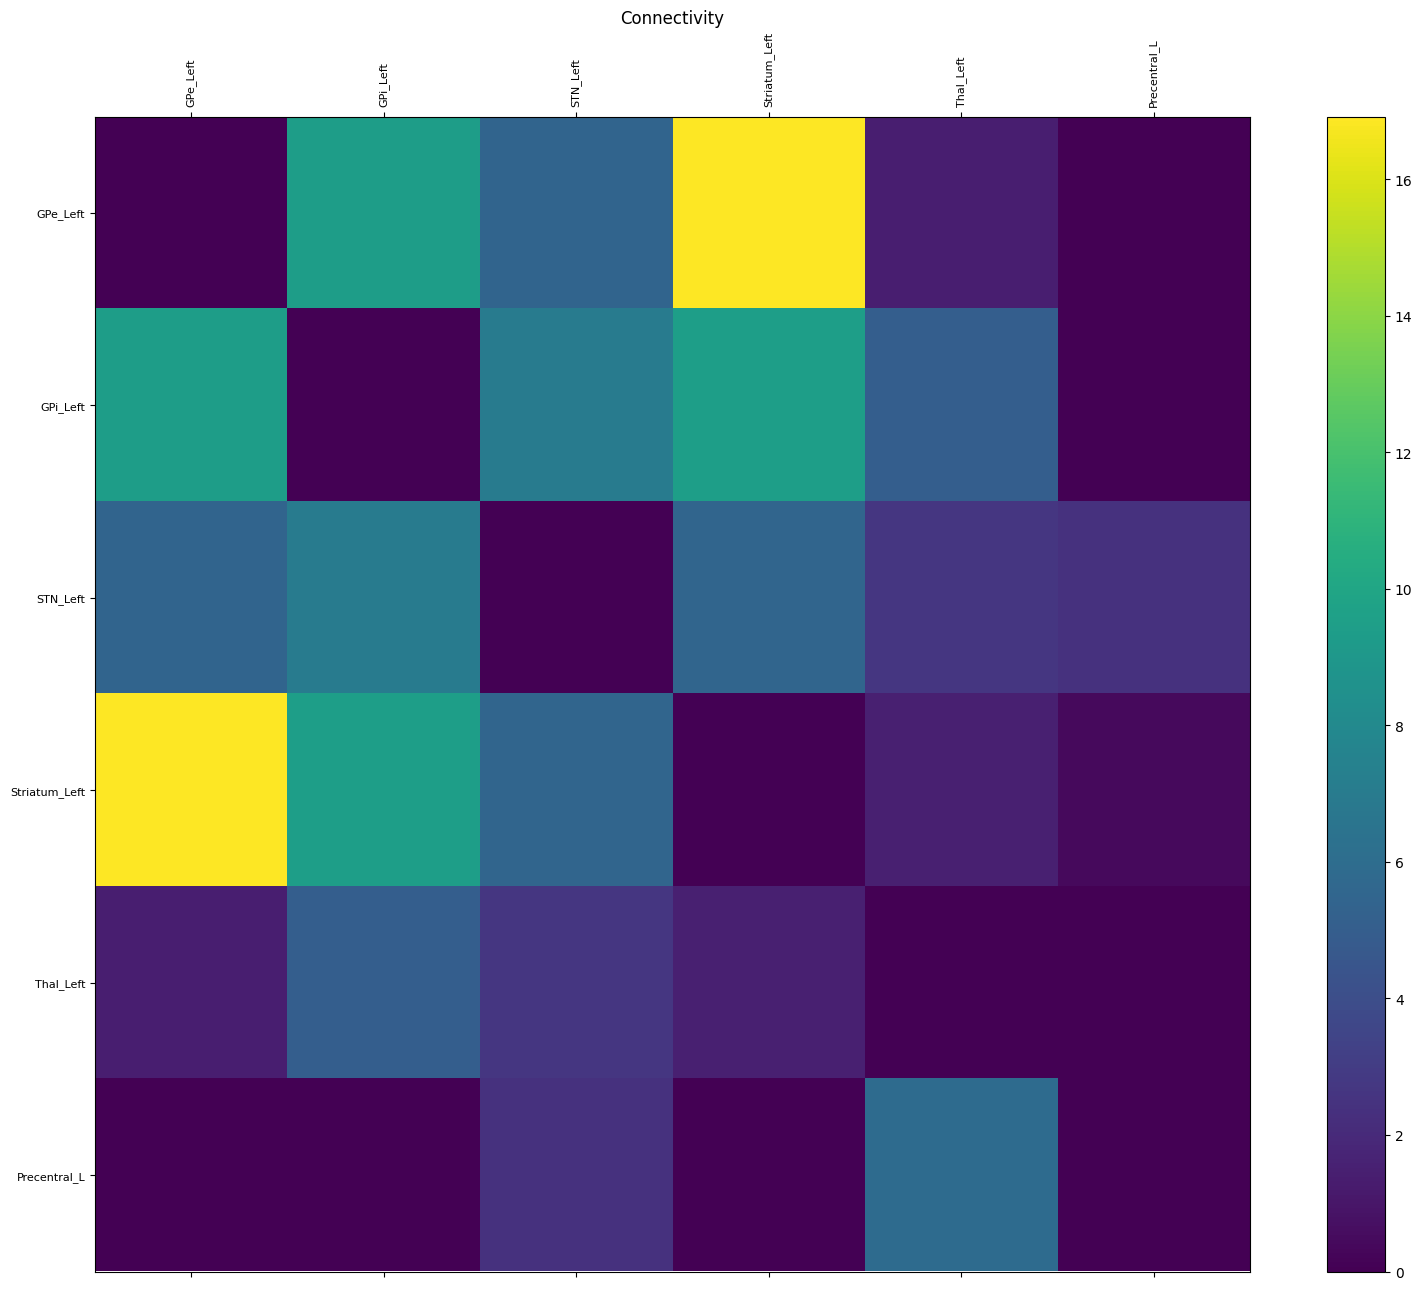

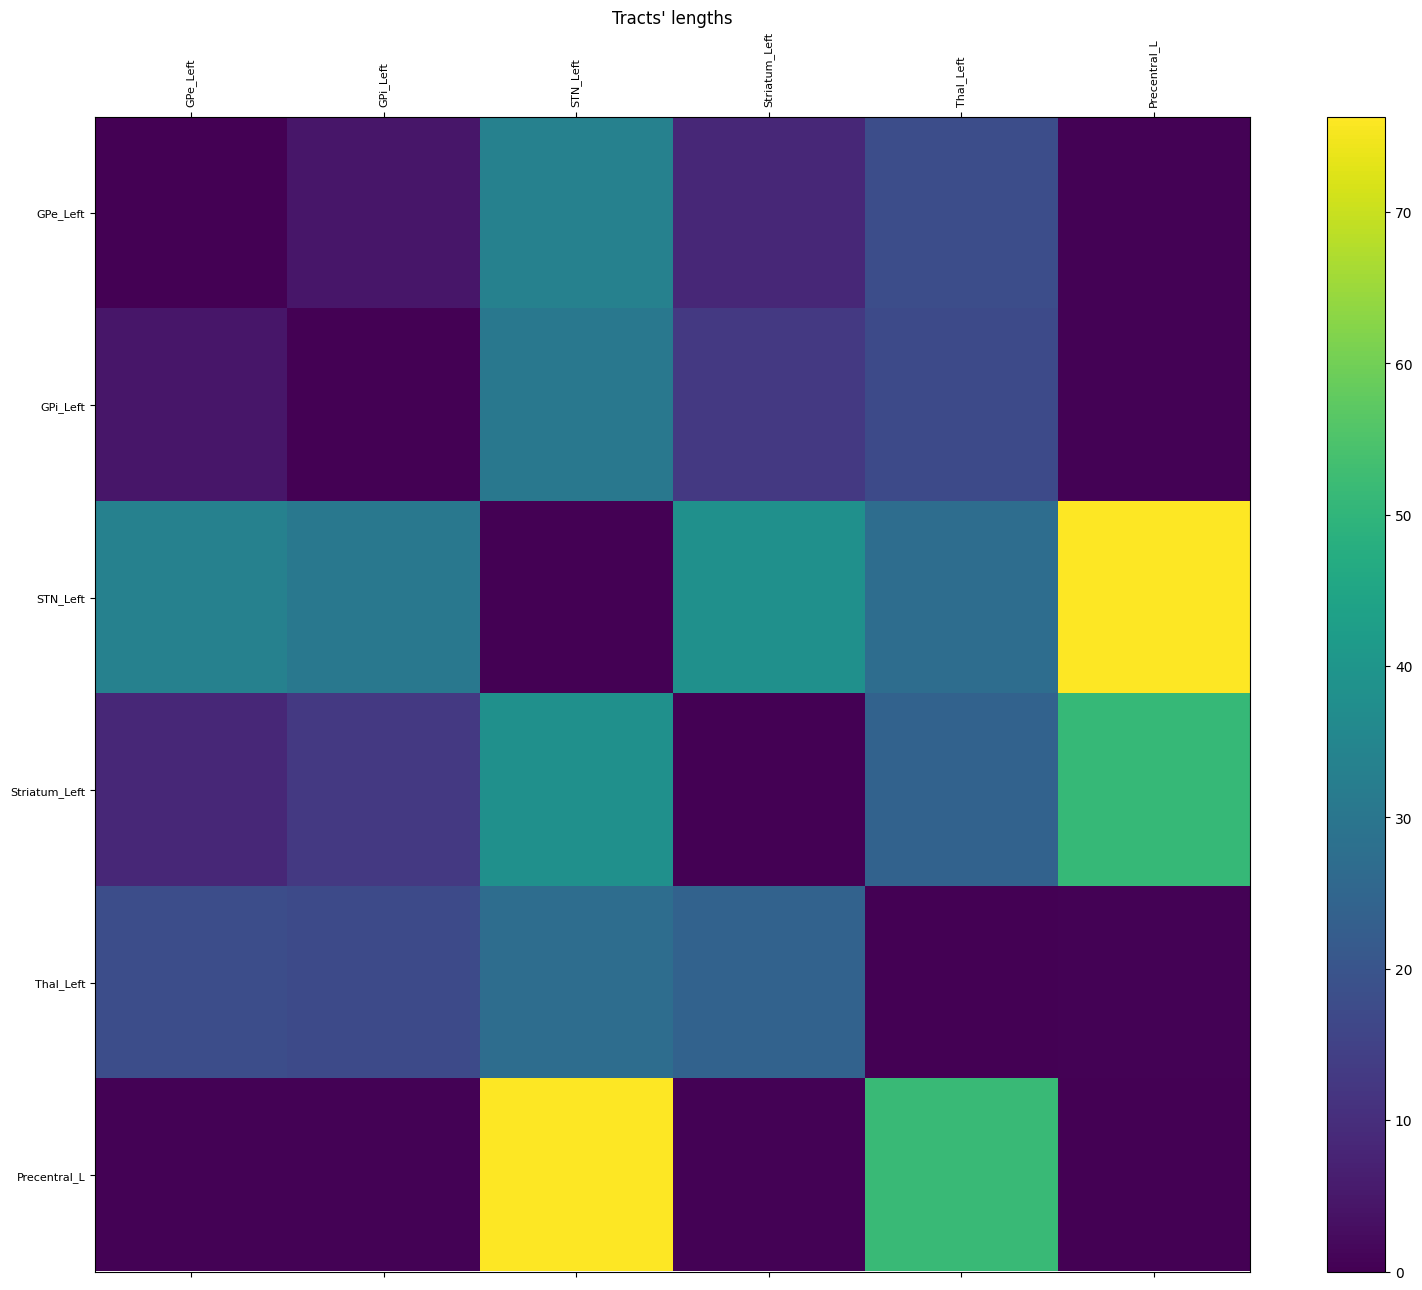

In [4]:
# Load full TVB connectome connectivity

conn_path = os.path.join(data_path, "conn")

#Load AAL atlas normative connectome including the Basal Ganglia regions from Petersen et al. atlas
wTVB = np.loadtxt(os.path.join(conn_path, "conn_denis_weights.txt"))
cTVB = np.loadtxt(os.path.join(conn_path, "aal_plus_BG_centers.txt"),usecols=range(1,4))
rlTVB = np.loadtxt(os.path.join(conn_path, "aal_plus_BG_centers.txt"),dtype="str", usecols=(0,))
tlTVB = np.loadtxt(os.path.join(conn_path, "BGplusAAL_tract_lengths.txt"))

# Remove the second Thalamus, Pallidum (GPe/i), Putamen and Caudate (Striatum):
inds_Th = (rlTVB.tolist().index("Thalamus_L"), rlTVB.tolist().index("Thalamus_R"))
inds_Pall = (rlTVB.tolist().index("Pallidum_L"), rlTVB.tolist().index("Pallidum_R"))
inds_Put = (rlTVB.tolist().index("Putamen_L"), rlTVB.tolist().index("Putamen_R"))
inds_Caud = (rlTVB.tolist().index("Caudate_L"), rlTVB.tolist().index("Caudate_R"))
inds_rm = inds_Th + inds_Pall + inds_Put + inds_Caud
print("Connections of Thalami, Pallidum (GPe/i), Putamen and Caudate (Striatum) removed!:\n", 
      wTVB[inds_rm, :][:, inds_rm])
wTVB = np.delete(wTVB, inds_rm, axis=0)
wTVB = np.delete(wTVB, inds_rm, axis=1)
tlTVB = np.delete(tlTVB, inds_rm, axis=0)
tlTVB = np.delete(tlTVB, inds_rm, axis=1)
rlTVB = np.delete(rlTVB, inds_rm, axis=0)
cTVB = np.delete(cTVB, inds_rm, axis=0)

number_of_regions = len(rlTVB)
speed = np.array([4.0])
min_tt = speed.item() * 0.1
sliceBG = [0, 1, 2, 3, 6, 7]
sliceCortex = slice(10, number_of_regions)

# Remove BG -> Cortex connections
print("Removing BG -> Cortex connections with max:")
print(wTVB[sliceCortex, :][:, sliceBG].max())
wTVB[sliceCortex, sliceBG] = 0.0
tlTVB[sliceCortex, sliceBG] = min_tt

# Remove Cortex -> Thalamus connections
sliceThal = [8, 9]
print("Removing Cortex -> Thalamus connections with summed weight:")
print(wTVB[sliceThal, sliceCortex].sum())
wTVB[sliceThal, sliceCortex] = 0.0
tlTVB[sliceThal, sliceCortex] = min_tt

# Remove Cortex -> GPe/i connections
sliceGP = [0, 1, 2, 3]
print("Removing Cortex -> GPe/i connections with max:")
print(wTVB[sliceGP, sliceCortex].max())
wTVB[sliceGP,  sliceCortex] = 0.0
tlTVB[sliceGP, sliceCortex] = min_tt

# # Minimize all delays for the optimized network
# tlTVB[:7][:, :7] = min_tt

connTVB = Connectivity(region_labels=rlTVB, weights=wTVB, centres=cTVB, tract_lengths=tlTVB, speed=speed)

# Normalize connectivity weights
connTVB.weights = connTVB.scaled_weights(mode="region")
connTVB.weights /= np.percentile(connTVB.weights, 99)

if SINGLE_CORTICAL_REGION:
    # Keep basal ganglia, thalamus and one cortical region (left hemisphere)
    sliceLeft = slice(0, 12, 2)
else:
    # Keep only left hemisphere and remove Vermis:
    sliceLeft = slice(0, connTVB.number_of_regions -8, 2)

connLeft = Connectivity(region_labels=connTVB.region_labels[sliceLeft], 
                        centres=connTVB.centres[sliceLeft],
                        weights=connTVB.weights[sliceLeft][:, sliceLeft],
                        tract_lengths=connTVB.tract_lengths[sliceLeft][:, sliceLeft], 
                        speed=connTVB.speed)

# if SINGLE_CORTICAL_REGION:
#     # Set the optimized Cortex -> Basal Ganglia weights:
#     wCtxSN = (wCtxdSN + wCtxiSN)/2
#     #                                   GPe  GPi    STN   Striatum  Th  Ctx
#     connLeft.weights[:, -1] = np.array([0.0, 0.0, wCtxSTN, wCtxSN, 0.0, 0.0])
#     print(connLeft.weights.astype("float32"))

    
connLeft.configure()

print("\nLeft cortex connectome, after removing direct BG -> Cortex and intehemispheric BG <-> BG connections:")
plotter.plot_tvb_connectivity(connLeft);


Left BG TVB network:


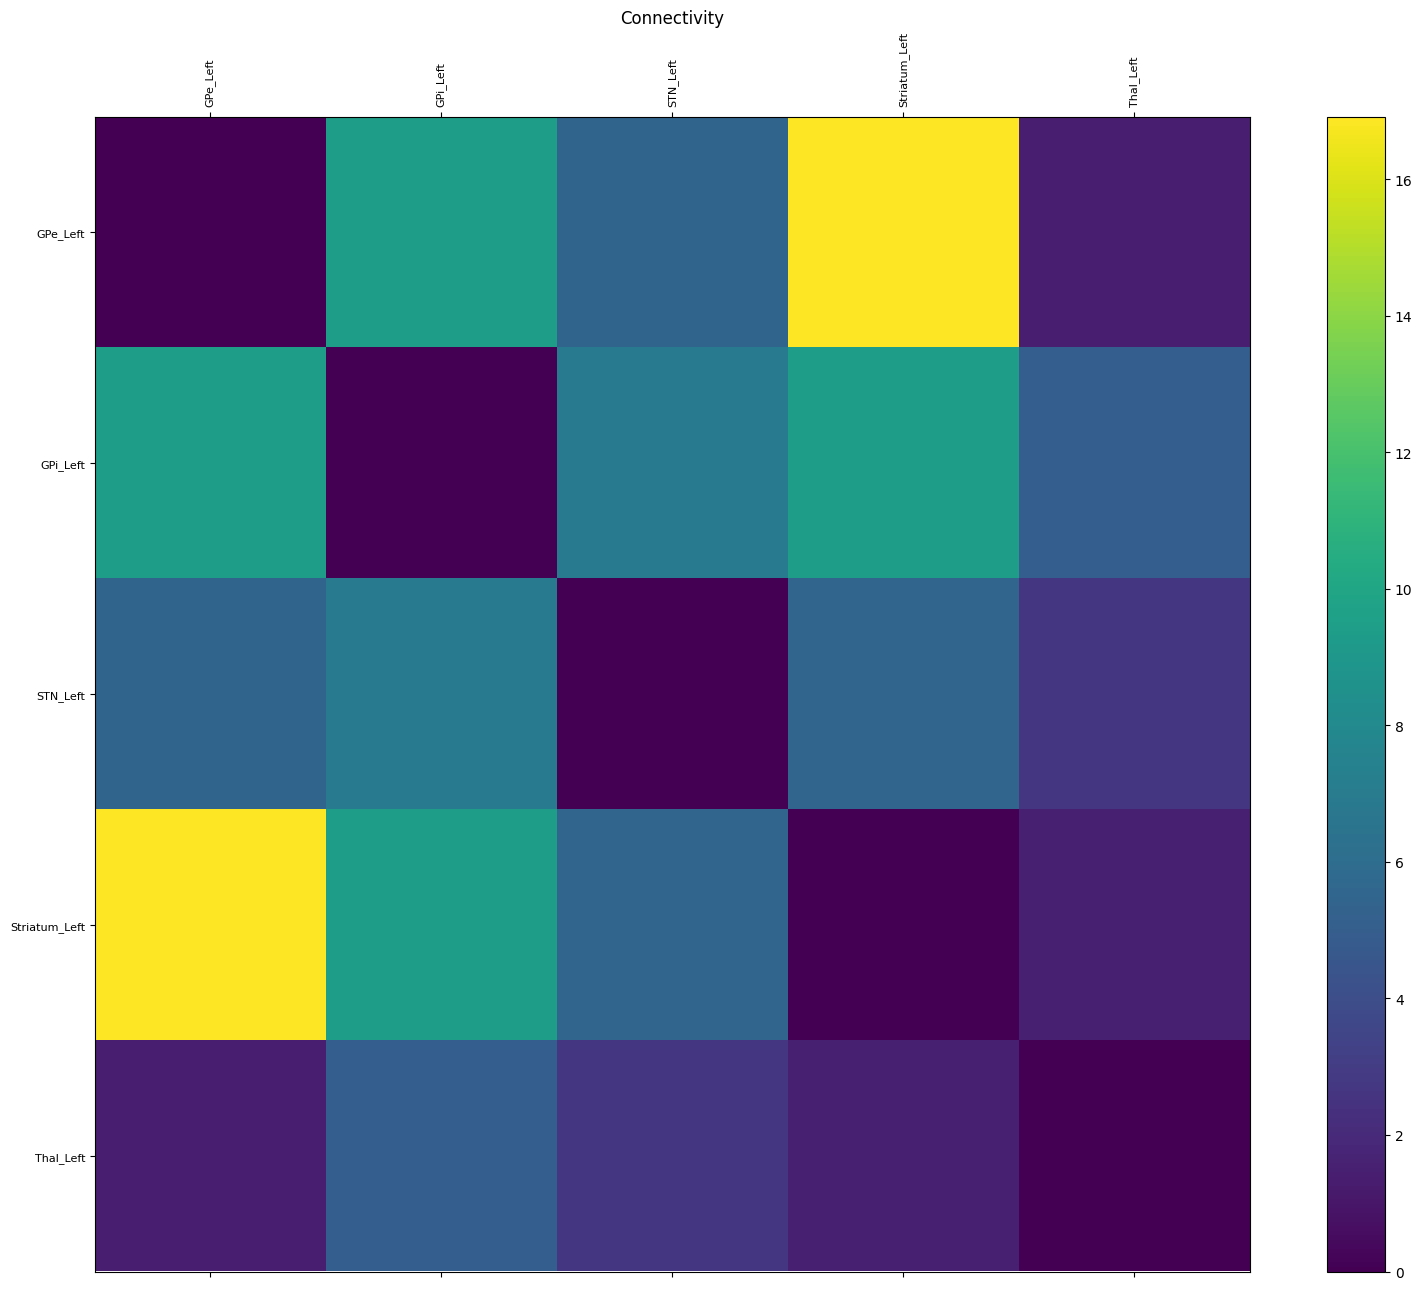

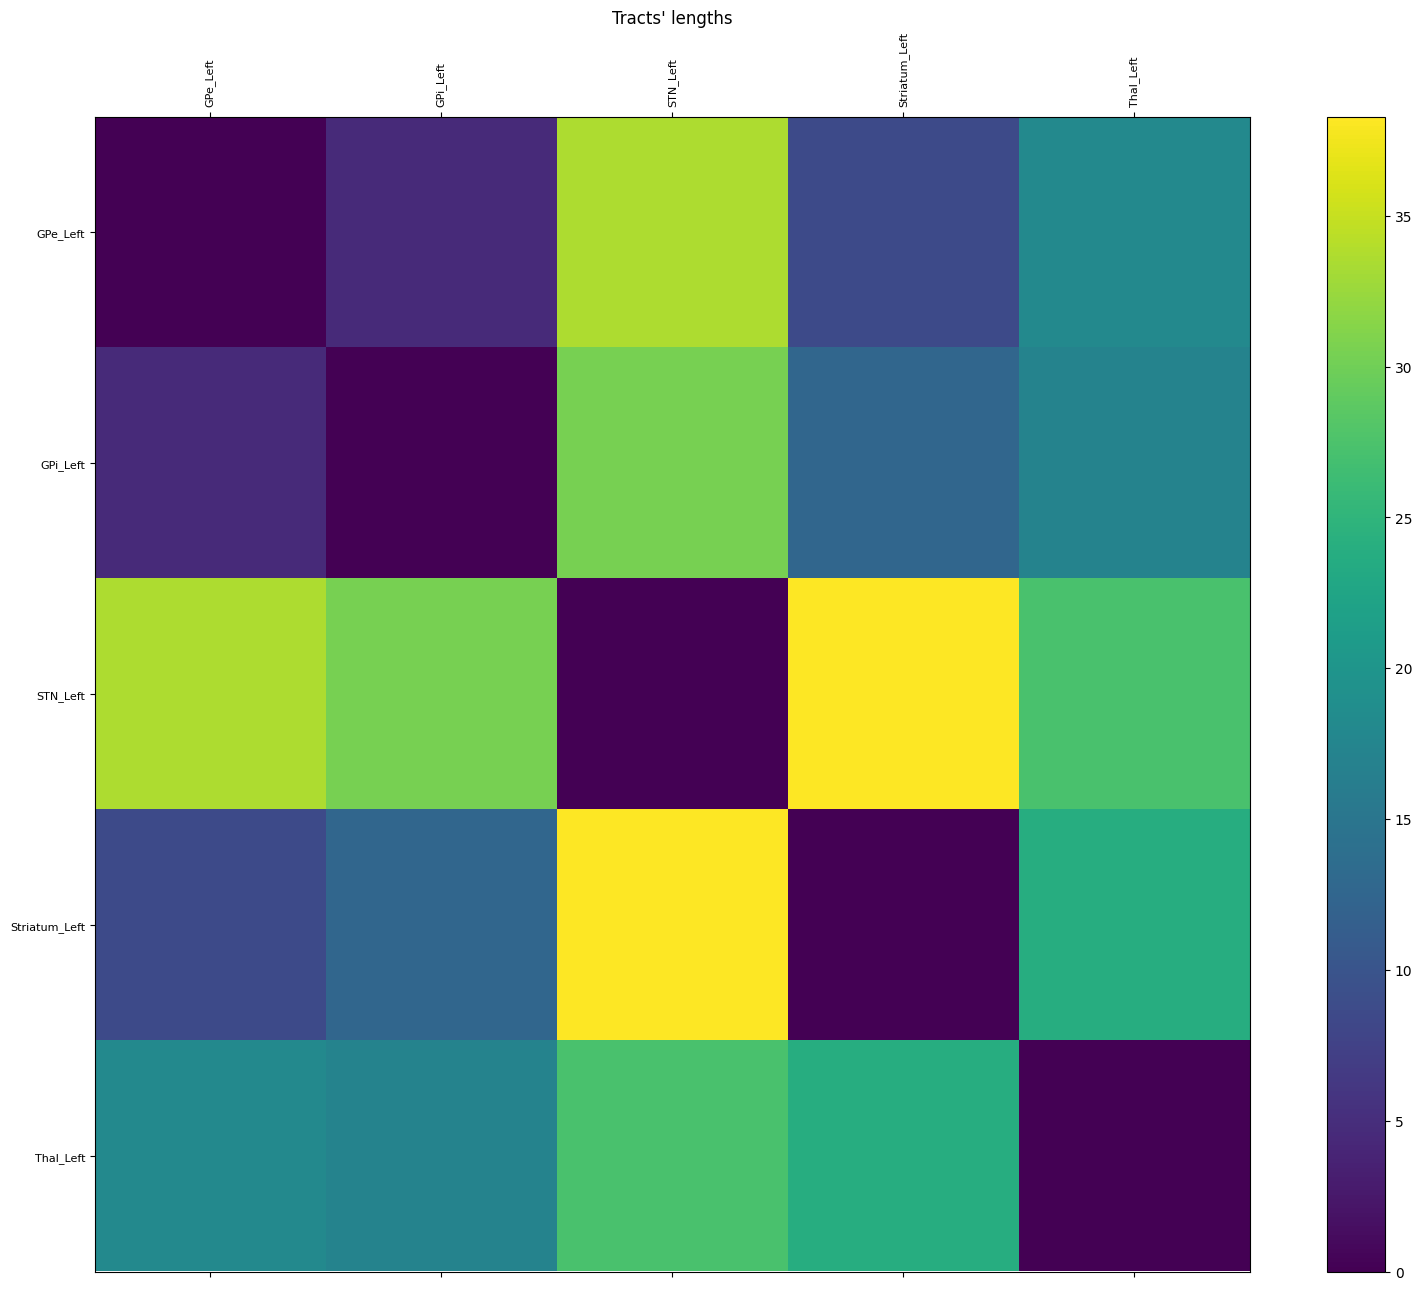

In [5]:
sliceBGnet = slice(0,5)
connTVBleftBG = Connectivity(region_labels=connLeft.region_labels[sliceBGnet], 
                             centres=connLeft.centres[sliceBGnet],
                             weights=connLeft.weights[sliceBGnet][:, sliceBGnet],
                             tract_lengths=connLeft.tract_lengths[sliceBGnet][:, sliceBGnet], 
                            speed=connLeft.speed)
connTVBleftBG.configure()

print("\nLeft BG TVB network:")
plotter.plot_tvb_connectivity(connTVBleftBG);


In [6]:
if SINGLE_CORTICAL_REGION:
    scaleBGoptTOtvb = 1.0
    connLeft.weights[-1] *= connLeft.weights[:, -1].mean() / connLeft.weights[-1].mean()
else:
    scaleBGoptTOtvb = np.percentile(BG_opt_matrix_weights, 95) /\
                      np.percentile(connTVBleftBG.weights, 95)
                  
print("Scaling factor of TVB BG network connectome to optimal one = %g" % scaleBGoptTOtvb)


Scaling factor of TVB BG network connectome to optimal one = 1


[[0.         0.         0.0451     0.0356     0.         0.        ]
 [0.023      0.         0.0352     0.0193     0.         0.        ]
 [0.0146     0.         0.         0.         0.         2.38624638]
 [0.         0.         0.         0.         0.0182     0.40807151]
 [0.         0.0198     0.         0.         0.         0.        ]
 [0.         0.         0.80138714 0.         1.99293076 0.        ]]


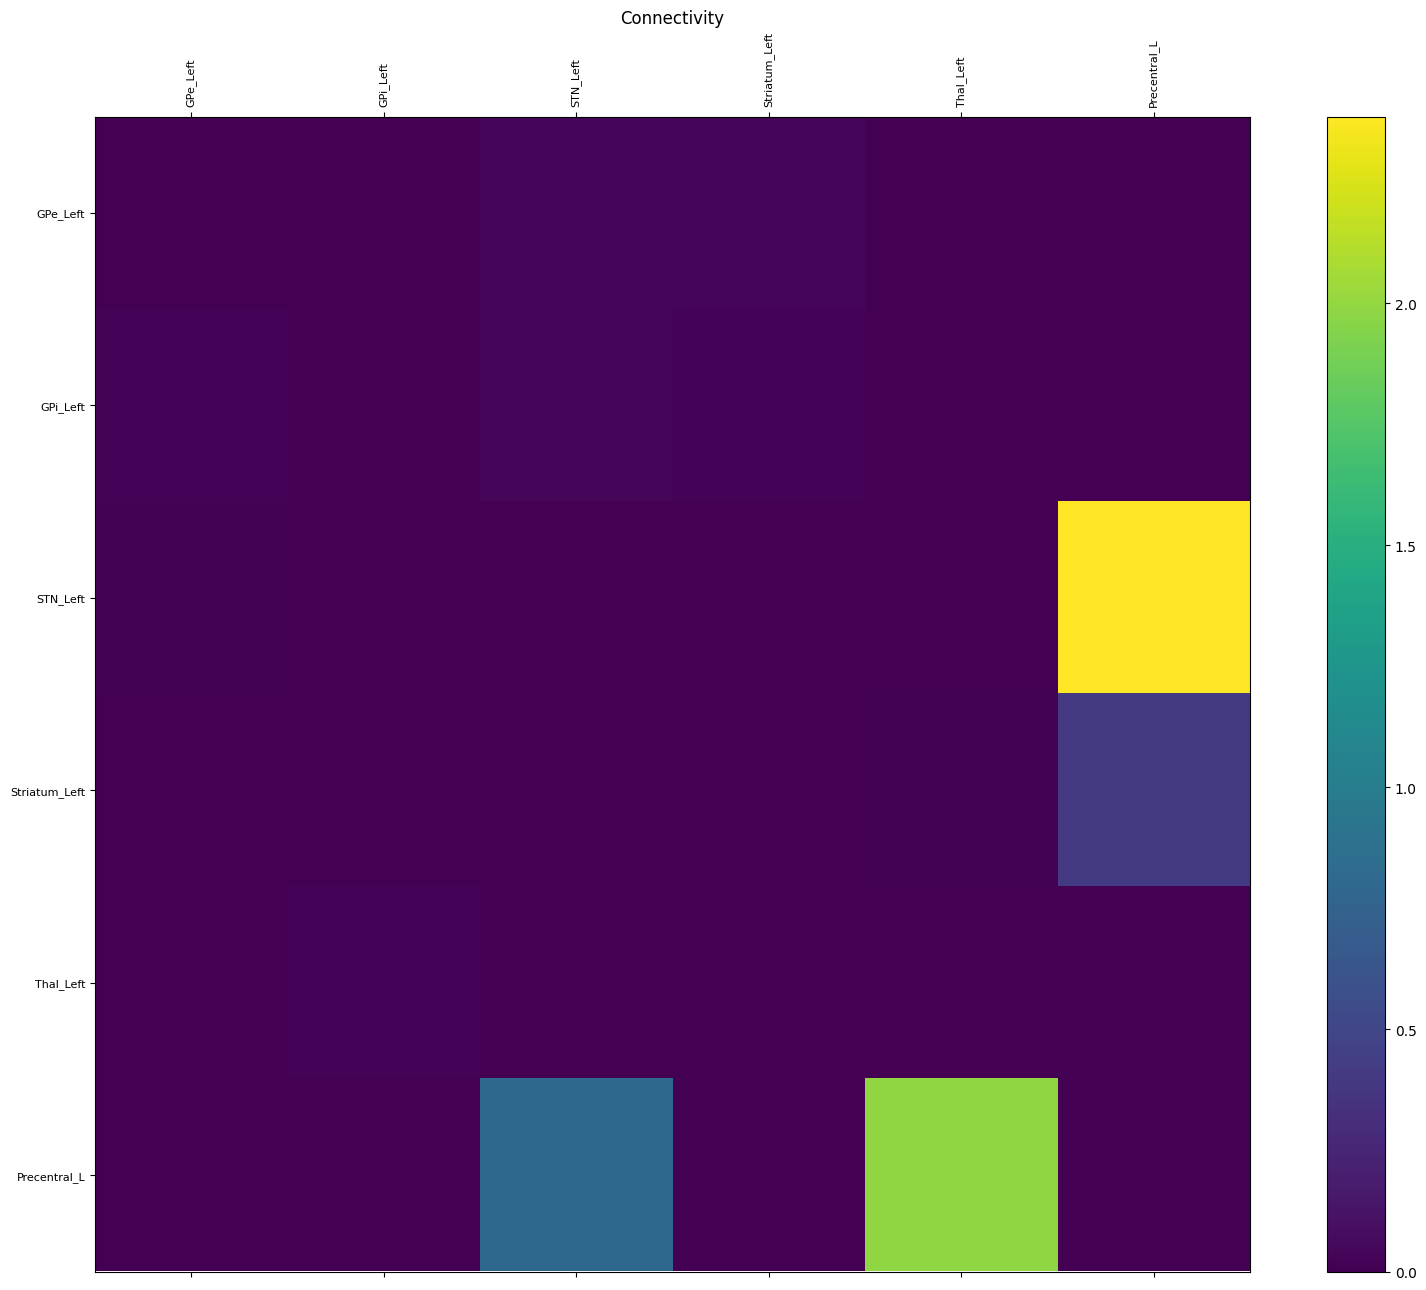

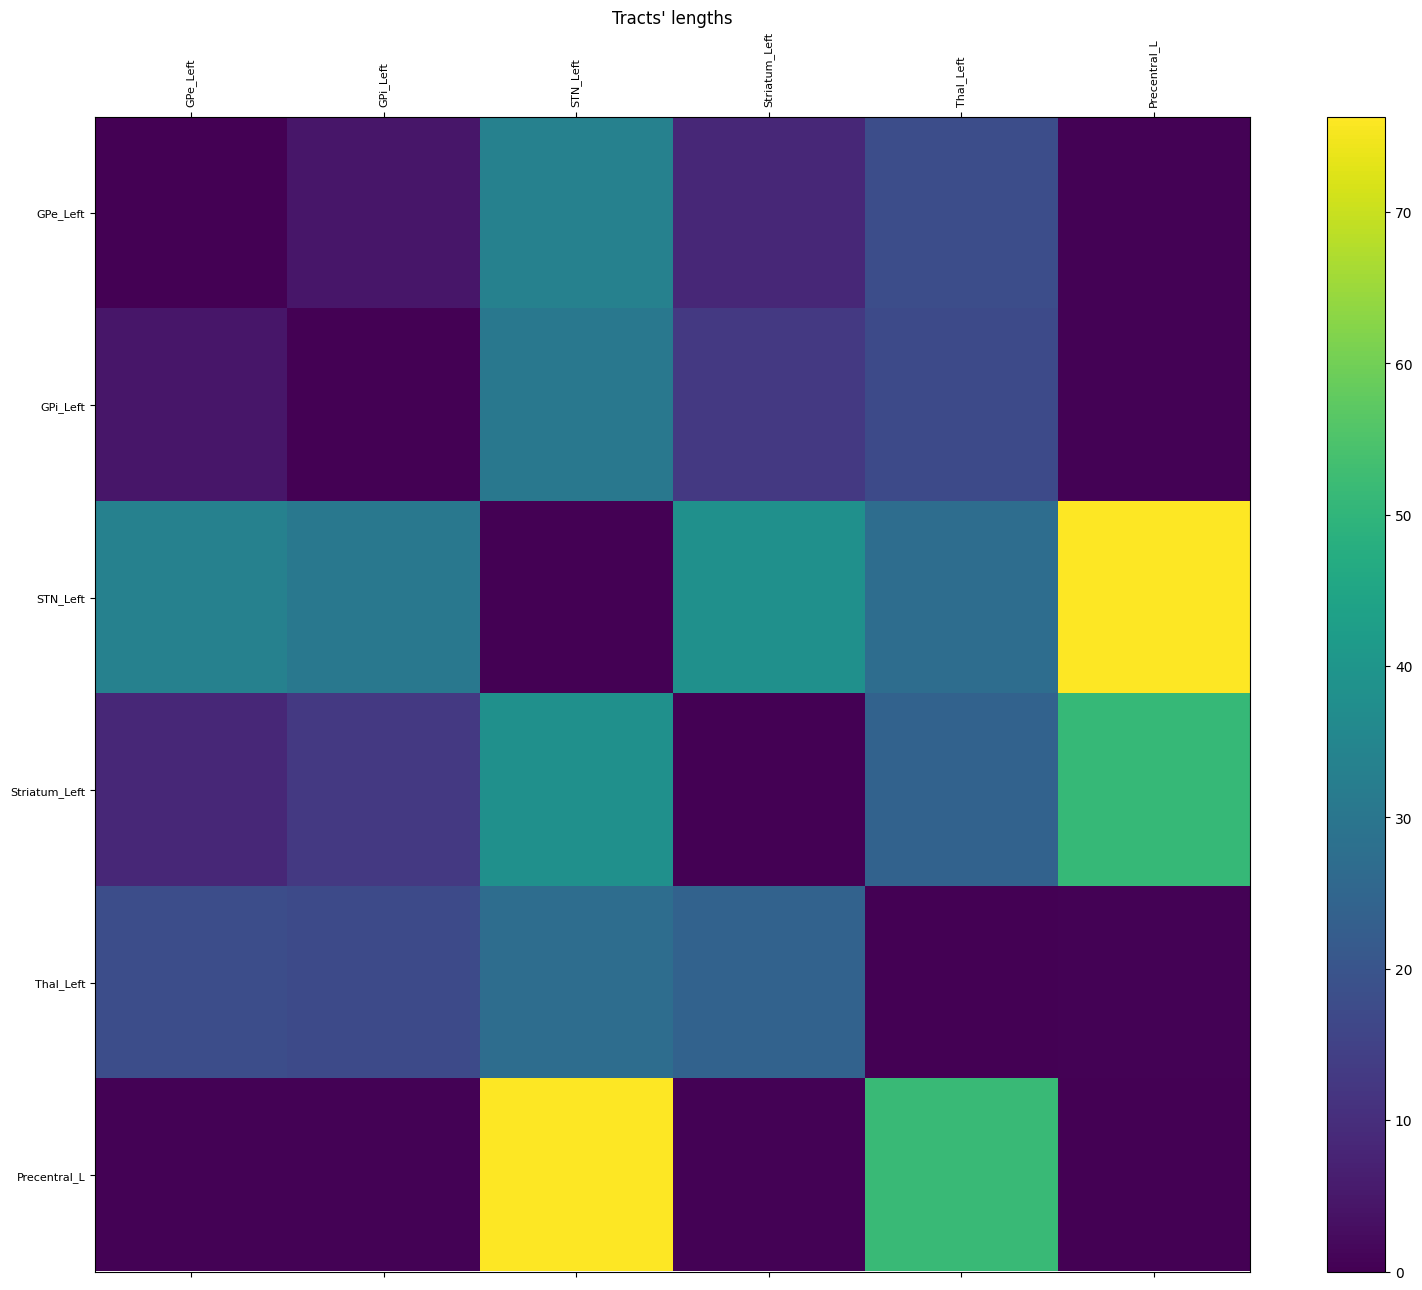

In [7]:
# Construct the final connectivity to use for simulation:
# Rescale the 
ww = scaleBGoptTOtvb * np.array(connLeft.weights)
ww[sliceBGnet, sliceBGnet] = BG_opt_matrix_weights.T  # !!!NOTE TVB indices convention Wi<-j!!!

connectivity = Connectivity(region_labels=connLeft.region_labels, 
                            centres=connLeft.centres,
                            weights=ww, tract_lengths=connLeft.tract_lengths, 
                            speed=connLeft.speed)
connectivity.configure()

if SINGLE_CORTICAL_REGION:
    print(connectivity.weights)
    plotter.plot_tvb_connectivity(connectivity);
else:
    # Construct only the optimized BG connectivity only for plotting:
    connBGopt = Connectivity(region_labels=connectivity.region_labels[sliceBGnet], 
                             centres=connectivity.centres[sliceBGnet],
                             weights=connectivity.weights[sliceBGnet][:, sliceBGnet],
                             tract_lengths=connectivity.tract_lengths[sliceBGnet][:, sliceBGnet], 
                             speed=connectivity.speed)
    connBGopt.configure()

    print("\nLeft BG optimized network:")
    plotter.plot_tvb_connectivity(connBGopt);



Connectome used for simulations:


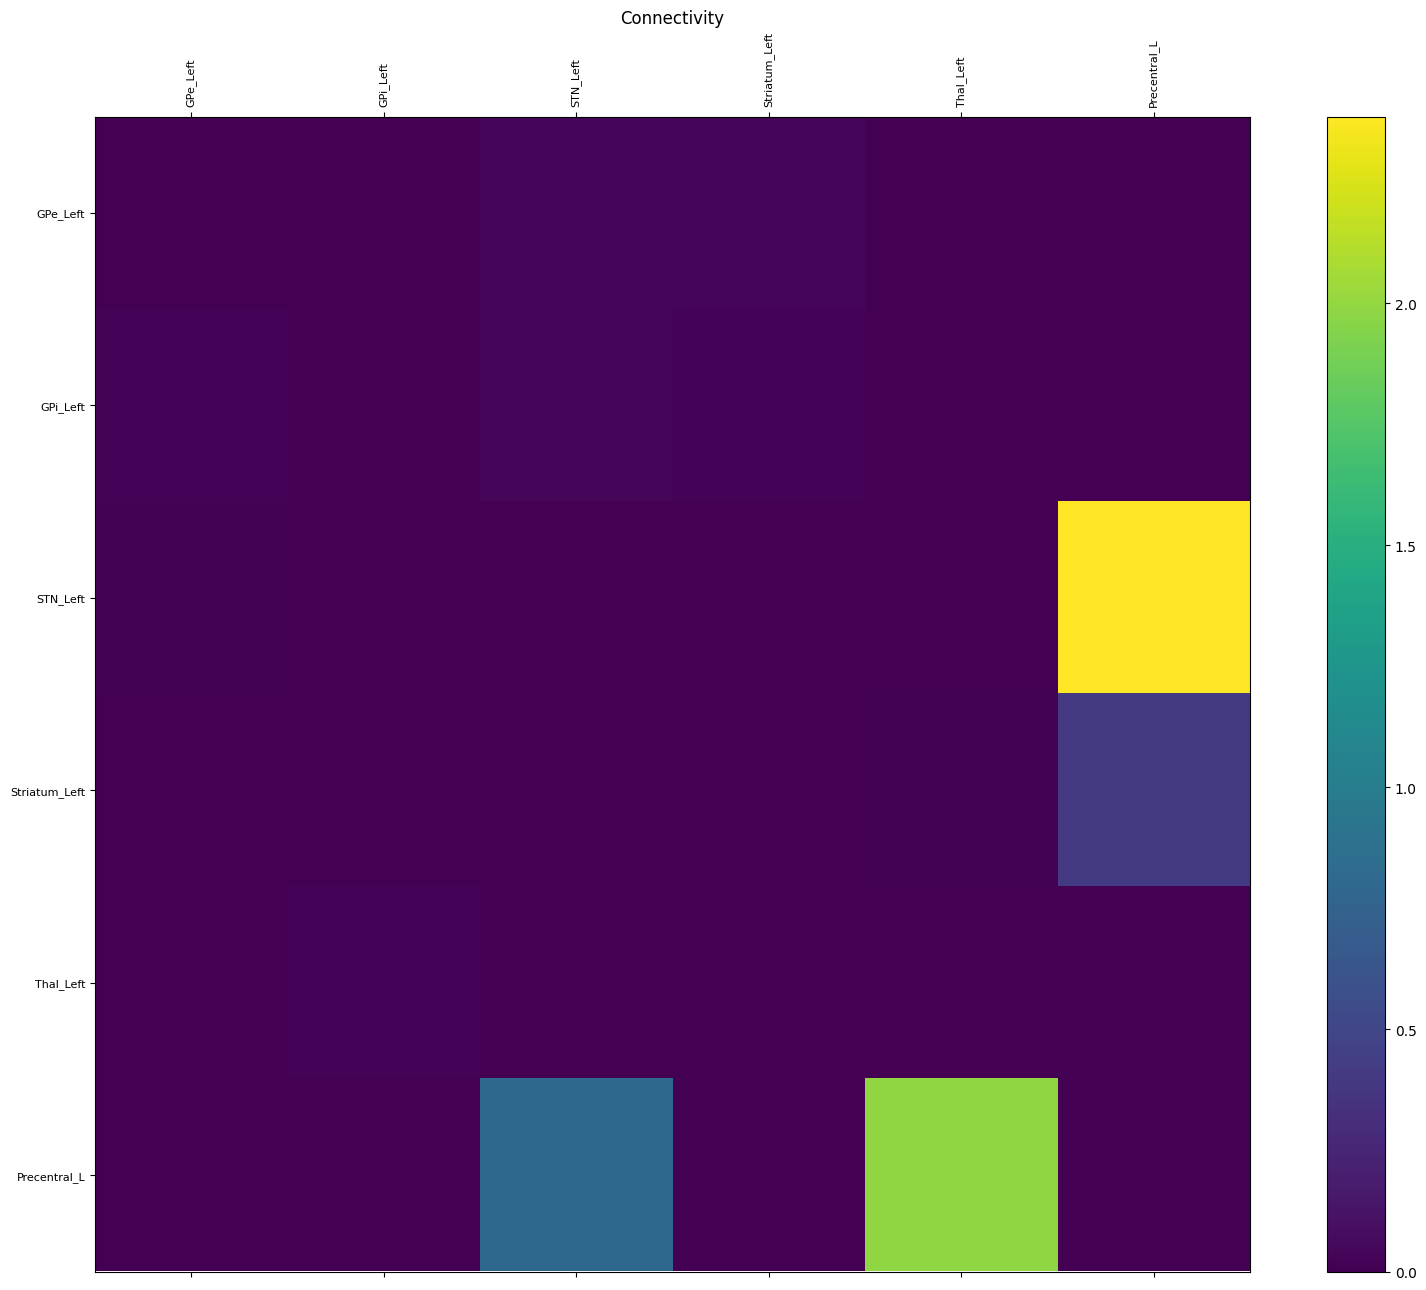

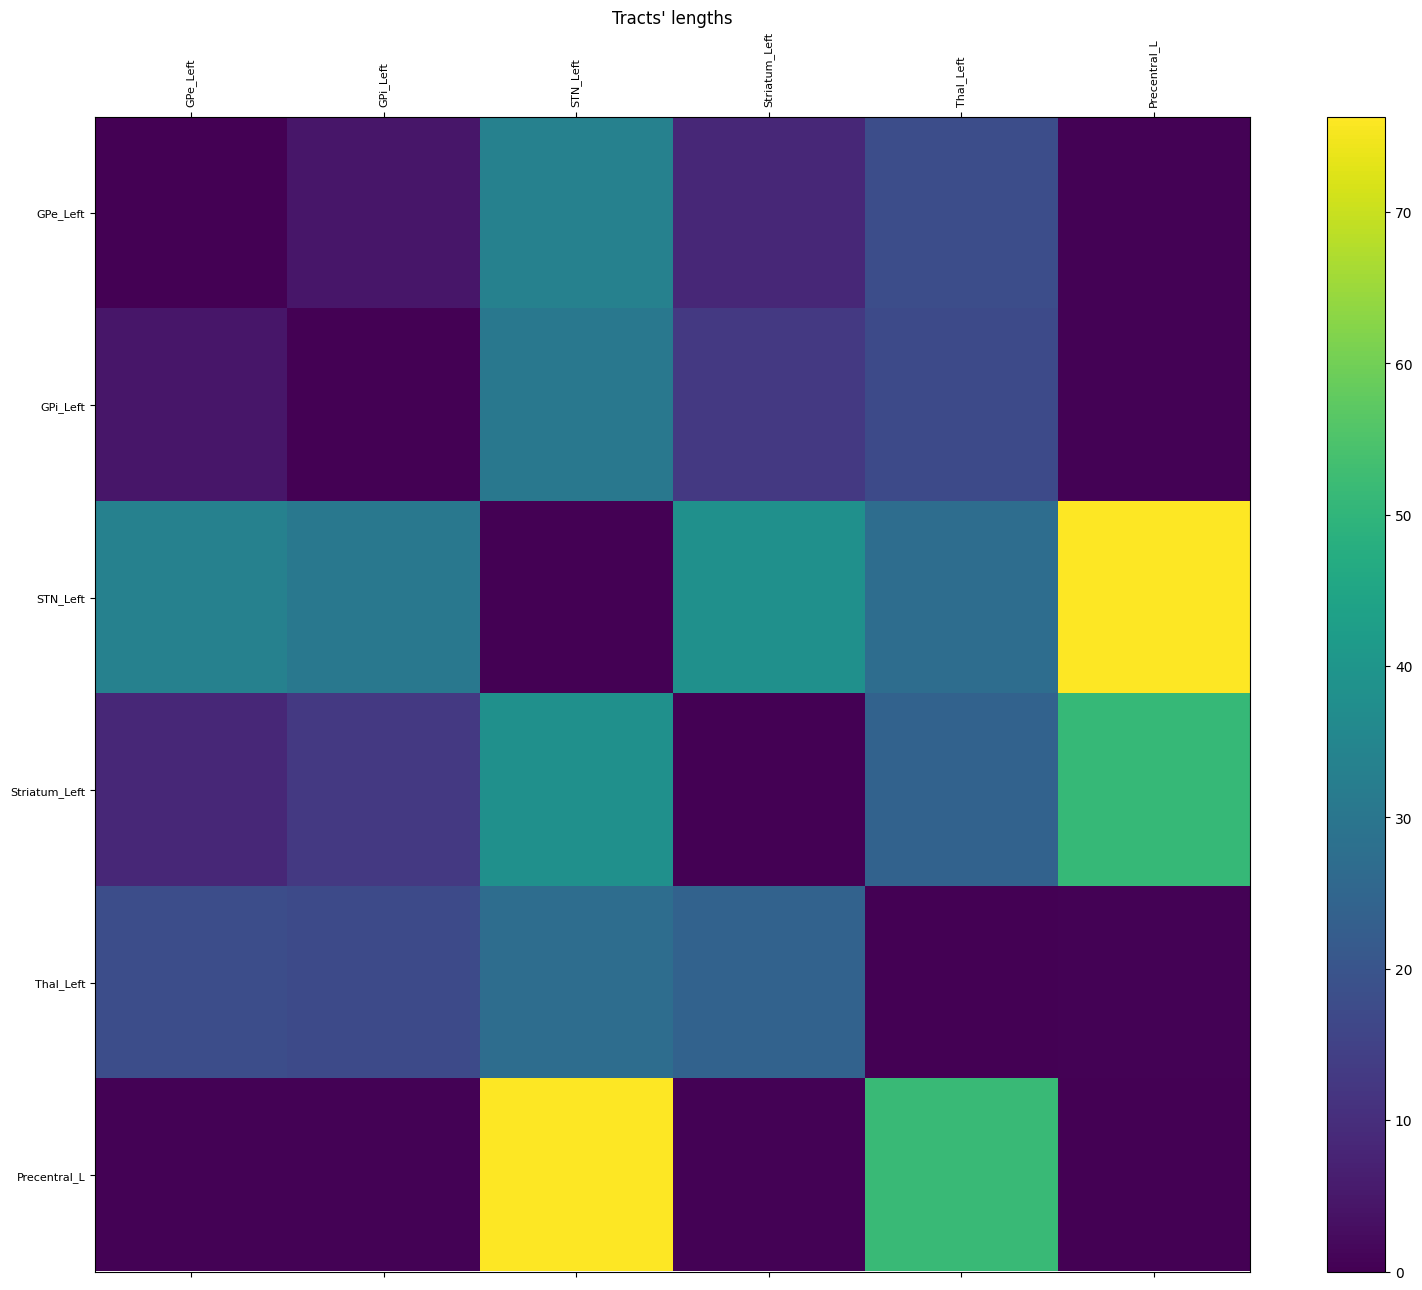

In [8]:
from tvb_multiscale.core.tvb.cosimulator.cosimulator_serial import CoSimulatorSerial as CoSimulator
from tvb_multiscale.core.tvb.cosimulator.models.MaithEtAlCortexExcInhGC import \
    MaithEtAlCortexExcInhGC as NCPModel

#white_matter_coupling = coupling.Linear(a=0.014)
# Create a TVB simulator and set all desired inputs
# (connectivity, model, surface, stimuli etc)
# We choose all defaults in this example
simulator = CoSimulator()

if data_mode == 'control':
    # seed 4 from fitting
    model_params = {
        'Δ': np.array([0.349]),
        'S_jump': np.array([2.698]),
        'G_cAMPA': np.array([0.0076]),
        'I_e': np.array([7.0]),
    }
else: # 'patient':
    # seed 1 from fitting
    model_params = {
        'Δ': np.array([0.363]),
        'S_jump': np.array([2.562]),
        'G_cAMPA': np.array([0.0083]),
        'I_e': np.array([7.0]),
    }
    
simulator.model = NCPModel(**model_params)
simulator.model.G = np.array([15.0/scaleBGoptTOtvb])
if TVB_TO_SPIKENET_INTERFACE_MODEL == "RATE":
    simulator.model.cvar = np.array([6, 0])
simulator.model.configure()

simulator.connectivity = connectivity

# Let's remove coupling.a as an independent degree of freedom:
simulator.coupling.a = np.array([1.0])

simulator.integrator = HeunStochastic()
simulator.integrator.dt = TVB_DT
simulator.integrator.noise.nsig = np.array([1e-8])  # 1e-5

mon_raw = Raw(period=1.0)  # ms
simulator.monitors = (mon_raw, )
simulator.connectivity.set_idelays(simulator.integrator.dt)

# init_cond_filepath = os.path.join(data_path, "tvb_init_cond_left.npy")
# init_cond = np.load(init_cond_filepath)   # 

init_cond = np.zeros((simulator.connectivity.idelays.max(),
                    simulator.model.nvar,
                    simulator.connectivity.number_of_regions,
                    simulator.model.number_of_modes))

# if SINGLE_CORTICAL_REGION:
#     init_cond = init_cond[:,:simulator.connectivity.number_of_regions,:].shape

simulator.initial_conditions = init_cond
simulator.initial_conditions = simulator.initial_conditions[:,:,:,[0]]


print("\nConnectome used for simulations:")
plotter.plot_tvb_connectivity(simulator.connectivity);


# # Serializing TVB cosimulator is necessary for parallel cosimulation:
# from tvb_multiscale.core.utils.file_utils import dump_pickled_dict
# from tvb_multiscale.core.tvb.cosimulator.cosimulator_serialization import serialize_tvb_cosimulator
# sim_serial_filepath = os.path.join(config.out.FOLDER_RES, "tvb_serial_cosimulator.pkl")
# sim_serial = serialize_tvb_cosimulator(simulator)
# display(sim_serial)

# # Dumping the serialized TVB cosimulator to a file will be necessary for parallel cosimulation.
# dump_pickled_dict(sim_serial, sim_serial_filepath)

## 2. Build and connect the ANNarchy network model <br> (networks of spiking neural populations for fine-scale <br>regions, stimulation devices, spike detectors etc)

In [9]:
from tvb_multiscale.tvb_annarchy.annarchy_models.models.basal_ganglia_izhikevich import BasalGangliaIzhikevichBuilder
from tvb_multiscale.tvb_annarchy.annarchy.models import \
    Izhikevich_Hamker, Izhikevich_Hamker_Proxy_E, Izhikevich_Hamker_Proxy_EI
from examples.tvb_netpyne.notebooks.conn import lorentzian
from ANNarchy import HomogeneousCorrelatedSpikeTrains # PoissonPopulation
import ANNarchy as ann

# Select the regions for the fine scale modeling with ANNarchy spiking networks
spiking_nodes_ids = [0, 1, 2, 3, 4] # the indices of fine scale regions modeled with ANNarchy

# Build a ANNarchy network model with the corresponding builder
ann_model_builder = BasalGangliaIzhikevichBuilder(simulator, spiking_nodes_ids, config=config)


# # ----------------------------------------------------------------------------------------------------------------
# # ----Uncomment below to modify the builder by changing the default options:--------------------------------------
# # ----------------------------------------------------------------------------------------------------------------
from copy import deepcopy

population_neuron_model = Izhikevich_Hamker

ann_model_builder.population_order = 200 # reduce for speed

# When any of the properties model, params and scale below depends on regions,
# set a handle to a function with
# arguments (region_index=None) returning the corresponding property

ann_model_builder.params_common = \
    {"E_ampa": 0.0, "E_gaba": -90.0, "v_th": 30.0, "Vr": 0.0, "c": -65.0,
     "C": 1.0, "I": 0.0,
     "tau_syn": 1.0, "tau_ampa": 10.0, "tau_gaba": 10.0,
     "n0": 140.0, "n1": 5.0, "n2": 0.04, 
     "v": -72.0, "u": -14.0, 
     "noise": 0.0}

ann_model_builder._paramsI = deepcopy(ann_model_builder.params_common)
ann_model_builder._paramsI.update({"a": 0.005, "b": 0.585, "d": 4.0, 
                                   "v": -70.0, "u": -18.55})
ann_model_builder._paramsE = deepcopy(ann_model_builder.params_common)
ann_model_builder._paramsE.update({"v": -70.0, "u": -18.55})
ann_model_builder.paramsStr = deepcopy(ann_model_builder.params_common)
ann_model_builder.paramsStr.update({"v_th": 40.0, "C": 50.0, "Vr": -80.0,
                                    "n0": 61.65119, "n1": 2.594639, "n2": 0.022799, 
                                    "a": 0.05, "b": -20.0, "c": -55.0, "d": 377.0, 
                                    "v": -70.0, "u": -18.55})

ann_model_builder.Igpe_nodes_ids = [0]
ann_model_builder.Igpi_nodes_ids = [1]
ann_model_builder.Estn_nodes_ids = [2]
ann_model_builder.Eth_nodes_ids = [4]
ann_model_builder.Istr_nodes_ids = [3]
ann_model_builder.Crtx_nodes_ids = list(range(5,simulator.connectivity.number_of_regions))

I_nodes_ids = ann_model_builder.Igpe_nodes_ids + ann_model_builder.Igpi_nodes_ids
E_nodes_ids = ann_model_builder.Estn_nodes_ids + ann_model_builder.Eth_nodes_ids


SPIKING_CORTICAL_I_D = np.maximum(np.abs(0.01*SPIKING_CORTICAL_I), 0.01)

def paramsE_fun(node_id, cortex_noise=CORTICAL_SPIKING_NOISE):
    paramsE = deepcopy(ann_model_builder._paramsE)
    if node_id in ann_model_builder.Estn_nodes_ids:
        paramsE.update({"a": 0.005, "b": 0.265, "d": 2.0, "I": 3.0})  # dictionary of params for Estn
    elif node_id in ann_model_builder.Eth_nodes_ids:
        paramsE.update({"a": 0.02, "b": 0.25, "d": 0.05, "I": 3.5}) # dictionary of params for Eth
    elif node_id in ann_model_builder.Crtx_nodes_ids:
        paramsE.update({"v": -72.0, # lorentzian(-72.0, 7.2, 150, deterministic=True),
                        "u": -14.0, 
                        "a": 0.02, "b": 0.2, "d": 6.0,"c": -72.0, 
                        "tau_refrac": 5.0,
                        # I = 7.0,  or 50.0 
                        "I": lorentzian(SPIKING_CORTICAL_I, SPIKING_CORTICAL_I_D, 600, deterministic=True),
                        "noise": cortex_noise})
    return paramsE

    
def paramsI_fun(node_id):
    # For the moment they are identical, unless you differentiate the noise parameters
    paramsI = deepcopy(ann_model_builder._paramsI)
    if node_id in ann_model_builder.Igpe_nodes_ids:
        paramsI.update({"I": 12.0})
    elif node_id in ann_model_builder.Igpi_nodes_ids:
        paramsI.update({"I": 30.0})
    elif node_id in ann_model_builder.Crtx_nodes_ids:
        paramsI.update({"v": -72.0, # lorentzian(-72.0, 7.2, 150, deterministic=True), 
                        "u": -14.0, 
                        "c": -72.0, "a": 0.02, "b": 0.2, "d": 6.0, 
                        "tau_refrac": 5.0,
                        "I": lorentzian(0.0, SPIKING_CORTICAL_I_D, 150, deterministic=True)})
    return paramsI


# Populations' configurations
# When any of the properties model, params and scale below depends on regions,
# set a handle to a function with
# arguments (region_index=None) returning the corresponding property
ann_model_builder.populations = [
    {"label": "E", "model": population_neuron_model,  
     "params":  paramsE_fun, 
     "nodes": E_nodes_ids,  # Estn in [2], Eth in [4]
     "scale": 1.0},
    {"label": "I", "model": population_neuron_model,  
     "params": paramsI_fun, 
     "nodes": I_nodes_ids,  # Igpe in [0], Igpi in [1]
     "scale": 1.0},
    {"label": "IdSN", "model": population_neuron_model,   
     "params": ann_model_builder.paramsStr, 
     "nodes": ann_model_builder.Istr_nodes_ids,  # IdSN in [3]
     "scale": 1.0},
    {"label": "IiSN", "model": population_neuron_model,   # IiSN in [3]
     "params": ann_model_builder.paramsStr, 
     "nodes": ann_model_builder.Istr_nodes_ids,  # None means "all"
     "scale": 1.0}
]

# Within region-node connections
# When any of the properties model, conn_spec, weight, delay, receptor_type below
# set a handle to a function with
# arguments (region_index=None) returning the corresponding property

synapse_model = "Synapse"
conn_spec = {'rule': "all_to_all", 
             "allow_self_connections": True, "force_multiple_weights": False}
conn_spec_fixed_probability = conn_spec.copy()
conn_spec_fixed_probability.update({'rule': "fixed_probability", "probability": 0.1})

def conn_spec_fixed_prob(prob=None):
    output = conn_spec_fixed_probability.copy()
    if prob is not None:
        output["probability"] = prob
    return output

within_node_delay = SPIKING_NODES_FIXED_DELAY  # ms
        

# for each connection, we have a different probability
ann_model_builder.populations_connections = [
     #        source   ->   target
    {"source": "I", "target": "I",  # I -> I This is a self-connection for population "Igpe"
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pGPeGPe),  # conn_spec
     "weight": np.abs(wGPeGPe).item(), "delay": within_node_delay,
     "receptor_type": "gaba", "nodes": ann_model_builder.Igpe_nodes_ids},  # None means apply to all
    {"source": "I", "target": "I",  # I -> I This is a self-connection for population "Igpi"
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pGPiGPi),  # conn_spec
     "weight": np.abs(wGPiGPi).item(), "delay": within_node_delay,
     "receptor_type": "gaba", "nodes": ann_model_builder.Igpi_nodes_ids},  # None means apply to all
    {"source": "IdSN", "target": "IdSN",  # IdSN -> IdSN This is a self-connection for population "IdSN"
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pdSNdSN),  # conn_spec
     "weight": np.abs(wdSNdSN).item(), "delay": within_node_delay,
     "receptor_type": "gaba", "nodes": ann_model_builder.Istr_nodes_ids},
    {"source": "IiSN", "target": "IiSN",  # IiSN -> IiSN This is a self-connection for population "IiSN"
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(piSNiSN),  # conn_spec
     "weight": np.abs(wiSNiSN).item(), "delay": within_node_delay,
     "receptor_type": "gaba", "nodes": ann_model_builder.Istr_nodes_ids},
    ]


# Among/Between region-node connections
# Given that only the AMPA population of one region-node couples to
# all populations of another region-node,
# we need only one connection type
        
# When any of the properties model, conn_spec, weight, delay, receptor_type below
# depends on regions, set a handle to a function with
# arguments (source_region_index=None, target_region_index=None)

from tvb_multiscale.core.spiking_models.builders.templates import scale_tvb_weight, tvb_delay

# We set global coupling scaling to 1.0,
# because we need the Maith et al optimized weights without any scaling:
ann_model_builder.global_coupling_scaling = 1.0 
        
# Function that will return the TVB weight with optional scaling:
class TVBWeightFun(object):
    
    def __init__(self, 
                 global_coupling_scaling=ann_model_builder.global_coupling_scaling, 
                 tvb_weights = ann_model_builder.tvb_weights):
        self.global_coupling_scaling = float(global_coupling_scaling)
        self.tvb_weights = tvb_weights.copy()
    
    def __call__(self, source_node, target_node):
        return scale_tvb_weight(source_node, target_node, self.tvb_weights,
                                scale=self.global_coupling_scaling)

# Function that will return the TVB delay unless SPIKING_NODES_DELAYS == False:
tvb_delay_fun = \
    lambda source_node, target_node: \
        np.maximum(ann_model_builder.tvb_dt, 
                   tvb_delay(source_node, target_node, ann_model_builder.tvb_delays)) \
            if SPIKING_NODES_DELAYS else within_node_delay
    
    
ann_model_builder.nodes_connections = [
    #        source    ->     target
    {"source": "IdSN", "target": "I",             # "IdSN" -> "Igpi"
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pdSNGPi),  # conn_spec
     "weight": TVBWeightFun(),
     "delay": lambda source_node, target_node: tvb_delay_fun(source_node, target_node),  
     "receptor_type": "gaba", 
     "source_nodes": ann_model_builder.Istr_nodes_ids, 
     "target_nodes": ann_model_builder.Igpi_nodes_ids},  # None means apply to all
    {"source": "IiSN", "target": "I",            # "IiSN" -> "Igpe"
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(piSNGPe),  # conn_spec
     "weight": TVBWeightFun(),
     "delay": lambda source_node, target_node: tvb_delay_fun(source_node, target_node),  
     "receptor_type": "gaba", 
     "source_nodes": ann_model_builder.Istr_nodes_ids, 
     "target_nodes": ann_model_builder.Igpe_nodes_ids},  # None means apply to all
    {"source": "I", "target": "I",             # "Igpe" -> "Igpi"
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pGPeGPi),  # conn_spec
     "weight": TVBWeightFun(),
     "delay": lambda source_node, target_node: tvb_delay_fun(source_node, target_node),  
     "receptor_type": "gaba", 
     "source_nodes": ann_model_builder.Igpe_nodes_ids, 
     "target_nodes": ann_model_builder.Igpi_nodes_ids},  # None means apply to all
    {"source": "I", "target": "E",              # "Igpi" -> "Eth"
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pGPiTh),  # conn_spec
     "weight": TVBWeightFun(),
     "delay": lambda source_node, target_node: tvb_delay_fun(source_node, target_node),  
     "receptor_type": "gaba", 
     "source_nodes": ann_model_builder.Igpi_nodes_ids, 
     "target_nodes": ann_model_builder.Eth_nodes_ids},  # None means apply to all
    {"source": "I", "target": "E",             # "Igpe" -> "Estn"
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pGPeSTN),  # conn_spec
     "weight": TVBWeightFun(),
     "delay": lambda source_node, target_node: tvb_delay_fun(source_node, target_node),  
     "receptor_type": "gaba", 
     "source_nodes": ann_model_builder.Igpe_nodes_ids, 
     "target_nodes": ann_model_builder.Estn_nodes_ids},  # None means apply to all
    {"source": "E", "target": "IdSN",   # "Eth" -> ["IdSN"] 
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pThdSN),  # conn_spec
     "weight": wThdSN, # TVBWeightFun(),
     "delay": lambda source_node, target_node: tvb_delay_fun(source_node, target_node),  
     "receptor_type": "ampa", 
     "source_nodes": ann_model_builder.Eth_nodes_ids, 
     "target_nodes": ann_model_builder.Istr_nodes_ids},  # None means apply to all
    {"source": "E", "target": "IiSN",   # "Eth" -> ["IiSN"] 
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pThiSN),  # conn_spec
     "weight": wThiSN,
     "delay": lambda source_node, target_node: tvb_delay_fun(source_node, target_node),  
     "receptor_type": "ampa", 
     "source_nodes": ann_model_builder.Eth_nodes_ids, 
     "target_nodes": ann_model_builder.Istr_nodes_ids},  # No
     {"source": "E", "target": "I",          # "Estn" -> ["Igpe"]
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pSTNGPe),  # conn_spec
     "weight": TVBWeightFun(),
     "delay": lambda source_node, target_node: tvb_delay_fun(source_node, target_node),  
     "receptor_type": "ampa", 
     "source_nodes": ann_model_builder.Estn_nodes_ids, 
     "target_nodes": ann_model_builder.Igpe_nodes_ids},
    {"source": "E", "target": "I",          # "Estn" -> ["Igpi"]
     "synapse_model": synapse_model, "conn_spec": conn_spec_fixed_prob(pSTNGPi),  # conn_spec
     "weight": TVBWeightFun(),
     "delay": lambda source_node, target_node: tvb_delay_fun(source_node, target_node),  
     "receptor_type": "ampa", 
     "source_nodes": ann_model_builder.Estn_nodes_ids, 
     "target_nodes": ann_model_builder.Igpi_nodes_ids},
     ]

# Creating  devices to be able to observe ANNarchy activity:

ann_model_builder.output_devices = []

period = 1.0

# Creating  devices to be able to observe ANNarchy activity:
params = deepcopy(ann_model_builder.config.ANNARCHY_OUTPUT_DEVICES_PARAMS_DEF["SpikeMonitor"])
for pop in ann_model_builder.populations:
    connections = OrderedDict({})
    #                      label <- target population
    connections[pop["label"]] = pop["label"]
    ann_model_builder.output_devices.append(
        {"model": "SpikeMonitor", "params": deepcopy(params),
         "connections": connections, "nodes": pop["nodes"]})  # None means apply to "all"

# Labels have to be different for every connection to every distinct population
# params for baladron implementation commented out for the moment
# TODO: use baladron neurons
params = deepcopy(ann_model_builder.config.ANNARCHY_OUTPUT_DEVICES_PARAMS_DEF["Monitor"])
params.update({"period": period,  
               'variables': ["v", "u", "I_syn", "I_syn_ex", "I_syn_in", "g_ampa", "g_gaba", "g_base"]})
for pop in ann_model_builder.populations:
    connections = OrderedDict({})
    #               label    <- target population
    connections[pop["label"] + "_ts"] = pop["label"]
    ann_model_builder.output_devices.append(
            {"model": "Monitor", "params": deepcopy(params),
             "connections": connections, "nodes": pop["nodes"]})  # None means apply to all
    
    
    
# # Create a spike stimulus input device
ann_model_builder.input_devices = []  #

# ----------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------

ann_model_builder.configure()

annarchy_network = ann_model_builder.build(set_defaults=False)


ANNarchy 5.0 (5.0.1) on linux (posix).
2026-03-31 09:35:26,024 - INFO - tvb-multiscale - Loading an ANNarchy instance...
2026-03-31 09:35:26,024 - INFO - tvb-multiscale - Loading an ANNarchy instance...
2026-03-31 09:35:26,024 - INFO - tvb-multiscale - Loading an ANNarchy instance...
2026-03-31 09:35:26,028 - INFO - tvb-multiscale - Cleaning ANNarchy compilation directory, if any...
2026-03-31 09:35:26,028 - INFO - tvb-multiscale - Cleaning ANNarchy compilation directory, if any...
2026-03-31 09:35:26,028 - INFO - tvb-multiscale - Cleaning ANNarchy compilation directory, if any...
2026-03-31 09:35:26,030 - INFO - tvb-multiscale - Configuring spiking network builder...
2026-03-31 09:35:26,030 - INFO - tvb-multiscale - Configuring spiking network builder...
2026-03-31 09:35:26,030 - INFO - tvb-multiscale - Configuring spiking network builder...
2026-03-31 09:35:26,030 - INFO - tvb-multiscale - Configuring populations...
2026-03-31 09:35:26,030 - INFO - tvb-multiscale - Configuring popula

In [10]:
populations_sizes = []
print("Population sizes: ")
for pop in ann_model_builder.populations:
    populations_sizes.append(int(np.round(pop["scale"] * ann_model_builder.population_order)))
    print("%s: %d" % (pop["label"], populations_sizes[-1]))
    

Population sizes: 
E: 200
I: 200
IdSN: 200
IiSN: 200


In [11]:

# The stimuli models:

if simulation_mode != "rs":

    # amplitude in mV or V? Was V in Michmizos paper, but had value 5.
    # frequency in Hz and later divided by 1000 because time scale is ms
    # duration in ms!
    #dt inside annarchy needs to be <=0.01 to realize a 60µs pulse width, but setting it to that leads to errors. 
    # realistic "duration" parameter for DBSInput would be 0.06

    if stim_mode.find("mono") > -1:
        DBSInput = ann.Neuron(
            parameters="""
                amplitude = 5.0
                kappa = 8
                frequency = 130
                duration = 0.1
            """,
            equations="""
                h1 = if sin(2*pi*(frequency/1000)*t) > 0 : 1 else : 0
                h2 = if sin(2*pi*(frequency/1000)*(t+duration)) > 0 : 1 else : 0
                r = amplitude*kappa*h1*(1-h2)
            """
        )
    elif stim_mode.find("bi") > -1:
        DBSInput = ann.Neuron(
            parameters="""
                amplitude = 5.0
                ampfactor = 10
                kappa = 8
                frequency = 130
                duration = 0.3
            """,
            equations="""
                h1 = if sin(2*pi*(frequency/1000)*t) > 0 : 1 else : 0
                h2 = if sin(2*pi*(frequency/1000)*(t-duration)) > 0 : 1 else : 0
                h4 = if sin(2*pi*(frequency/1000)*(t-((ampfactor+1)*duration))) > 0 : 1 else : 0
                i1 = amplitude*(1+ 1/ampfactor)*kappa*h1*(1-h2)
                i2 = (-amplitude/ampfactor) *kappa *h1*(1-h4)
                r = i1 + i2
            """
        )

In [12]:
# Prepare the stimuli:

if simulation_mode != "rs":
    
    if stim_target.find("STN") > -1:
        stim_target = "STN_Left" 
    else:
        stim_target = "GPi_Left" 
        
    if stim_mode != "simple":
        annet = annarchy_network.annarchy_network
        # now add DBS population invisible to TVB for now
        target_pop = annarchy_network.brain_regions[stim_target][0].population
        dbs_pop = annet.create(target_pop.size, DBSInput)
        dbs_proj = annet.connect(ann.CurrentInjection(dbs_pop, target_pop, 'dbs'))
        dbs_proj.connect_current()
        # switch the stimulation off for the first time segment
        dbs_pop.amplitude = 0
        dbs_pop.frequency = stim_freq
        dbs_pop.duration = stim_duration

        # just to check, add some annarchy monitors -> delete later    
        m1 = annet.monitor(dbs_pop, "r")
        m2 = annet.monitor(target_pop, ["g_dbs", "spike"])

## 3. Build the TVB-ANNarchy interface

In [13]:
# ---------------------------- Non opinionated TVB<->NEST interface builder----------------------------
from tvb_multiscale.tvb_annarchy.interfaces.builders import TVBANNarchyInterfaceBuilder   

tvb_spikeNet_model_builder =  TVBANNarchyInterfaceBuilder(config=config)  # non opinionated builder

tvb_spikeNet_model_builder.tvb_cosimulator = simulator            
tvb_spikeNet_model_builder.spiking_network = annarchy_network
# This can be used to set default tranformer and proxy models:
tvb_spikeNet_model_builder.model = TVB_TO_SPIKENET_INTERFACE_MODEL # "RATE" (or "SPIKES", "CURRENT") TVB->ANNarchy interface
tvb_spikeNet_model_builder.input_flag = True   # If True, ANNarchy->TVB update will be implemented
tvb_spikeNet_model_builder.output_flag = True  # If True, TVB->ANNarchy coupling will be implemented
# If default_coupling_mode = "TVB", large scale coupling towards spiking regions is computed in TVB
# and then applied with no time delay via a single "TVB proxy node" / ANNarchy device for each spiking region,
# "1-to-1" TVB->ANNarchy coupling.
# If any other value, we need 1 "TVB proxy node" / ANNarchy device for each TVB sender region node, and
# large-scale coupling for spiking regions is computed in ANNarchy, 
# taking into consideration the TVB connectome weights and delays, 
# in this "1-to-many" TVB->ANNarchy coupling.
tvb_spikeNet_model_builder.default_coupling_mode = INTERFACE_COUPLING_MODE # "spikeNet" # "TVB" 
# Number of neurons per population to be used to compute population mean instantaneous firing rates:
tvb_spikeNet_model_builder.proxy_inds = np.array(spiking_nodes_ids)
tvb_spikeNet_model_builder.N_E = ann_model_builder.population_order
tvb_spikeNet_model_builder.GPe_proxy_inds = np.array(ann_model_builder.Igpe_nodes_ids)
tvb_spikeNet_model_builder.GPi_proxy_inds = np.array(ann_model_builder.Igpi_nodes_ids)
tvb_spikeNet_model_builder.STN_proxy_inds = np.array(ann_model_builder.Estn_nodes_ids)
tvb_spikeNet_model_builder.Striatum_proxy_inds = np.array(ann_model_builder.Istr_nodes_ids)
tvb_spikeNet_model_builder.Thal_proxy_inds = np.array(ann_model_builder.Eth_nodes_ids)
tvb_spikeNet_model_builder.E_proxy_inds = \
    np.array(tvb_spikeNet_model_builder.STN_proxy_inds.tolist() +
             tvb_spikeNet_model_builder.Thal_proxy_inds.tolist())
tvb_spikeNet_model_builder.I_proxy_inds = \
    np.array(tvb_spikeNet_model_builder.GPe_proxy_inds.tolist() +
             tvb_spikeNet_model_builder.GPi_proxy_inds.tolist())
# Set exclusive_nodes = True (Default) if the spiking regions substitute for the TVB ones:
tvb_spikeNet_model_builder.exclusive_nodes = True  

tvb_spikeNet_model_builder.output_interfaces = []
tvb_spikeNet_model_builder.input_interfaces = []
    
   
# options for a nonopinionated builder:
from tvb_multiscale.core.interfaces.transformers.models.models import Transformers
from tvb_multiscale.core.interfaces.transformers.builders import \
    TVBtoSpikeNetTransformers, SpikeNetToTVBTransformers, \
    DefaultTVBtoSpikeNetTransformers, DefaultSpikeNetToTVBTransformers
from tvb_multiscale.core.interfaces.spikeNet.builders import DefaultTVBtoSpikeNetProxyModels, DefaultSpikeNetToTVBProxyModels
from tvb_multiscale.tvb_annarchy.interfaces.builders import \
        TVBtoANNarchyModels, ANNarchyInputProxyModels, \
        ANNarchyToTVBModels, ANNarchyOutputProxyModels
from tvb_multiscale.tvb_annarchy.interfaces.builders import \
        DefaultTVBtoANNarchyProxyModels, DefaultANNarchytoTVBProxyModels

    
    
def print_enum(enum):
    print("\n", enum)
    for name, member in enum.__members__.items():
        print(name,"= ", member.value)
    
    
print("Available input (ANNarchy->TVB update) / output (TVB->ANNarchy coupling) interface models:")
print_enum(TVBtoANNarchyModels)
print_enum(ANNarchyToTVBModels)
    
    
print("\n\nAvailable input (ANNarchy->TVB update) / output (TVB->ANNarchy coupling) proxy models:")

print_enum(DefaultTVBtoANNarchyProxyModels)
print_enum(ANNarchyInputProxyModels)
    
print_enum(ANNarchyOutputProxyModels)
print_enum(DefaultANNarchytoTVBProxyModels)
    
print("\n\nAll basic transformer models:")
print_enum(Transformers)

print("\n\nTVB to spikeNet transformer models:")
print_enum(TVBtoSpikeNetTransformers)

print("\n\nspikeNet to TVB transformer models:")
print_enum(SpikeNetToTVBTransformers)


print("\n\nDefault TVB to spikeNet transformer models:")
print_enum(DefaultTVBtoSpikeNetTransformers)

print("\n\nDefault spikeNet to TVB transformer models:")
print_enum(DefaultSpikeNetToTVBTransformers)

Available input (ANNarchy->TVB update) / output (TVB->ANNarchy coupling) interface models:

 <enum 'TVBtoSpikeNetModels'>
RATE =  RATE
SPIKES =  SPIKES
CURRENT =  CURRENT

 <enum 'SpikeNetToTVBModels'>
SPIKES =  SPIKES
POTENTIAL =  POTENTIAL
CURRENT =  CURRENT


Available input (ANNarchy->TVB update) / output (TVB->ANNarchy coupling) proxy models:

 <enum 'DefaultTVBtoANNarchyProxyModels'>
RATE =  ANNarchyInputProxyModels.RATE
RATE_TO_SPIKES =  ANNarchyInputProxyModels.RATE
RATE_TO_CORRELATED_SPIKES =  ANNarchyInputProxyModels.RATE_TO_CORRELATED_SPIKES
SPIKES =  ANNarchyInputProxyModels.SPIKES
PARROT_SPIKES =  None
CURRENT =  ANNarchyInputProxyModels.CURRENT
CURRENT_TO_SPIKES =  ANNarchyInputProxyModels.CURRENT_TO_SPIKES

 <enum 'ANNarchyInputProxyModels'>
RATE =  <class 'tvb_multiscale.tvb_annarchy.interfaces.io.ANNarchyTimedPoissonPopulationSet'>
RATE_TO_SPIKES =  <class 'tvb_multiscale.tvb_annarchy.interfaces.io.ANNarchyTimedPoissonPopulationSet'>
RATE_TO_CORRELATED_SPIKES =  <class

In [14]:
tvb_spikeNet_model_builder.tvb_model

,value
C,1.0
E_AMPA,0.0
E_GABA,-90.0
G_cAMPA,0.0076
I_e,7.0
I_i,0.0
S_jump,2.698
Type,MaithEtAlCortexExcInhGC
a,0.02
b,0.2


In [15]:

# TVB applies a global coupling scaling of coupling.a * model.G_cAMPA
if SINGLE_CORTICAL_REGION: 
    tvb_spikeNet_model_builder.G = 1.0
else:
    tvb_spikeNet_model_builder.G = tvb_spikeNet_model_builder.tvb_model.G_cAMPA[[0]]
tvb_spikeNet_model_builder.global_coupling_scaling = \
    (tvb_spikeNet_model_builder.tvb_cosimulator.coupling.a * tvb_spikeNet_model_builder.G)[[0]]
print("global_coupling_scaling = %g" % tvb_spikeNet_model_builder.global_coupling_scaling.item())

# Total TVB indegree weight to STN:
wTVBSTNs = simulator.connectivity.weights[ann_model_builder.Estn_nodes_ids, 5:].squeeze()
wTVBSTN = wTVBSTNs.sum().item()
print("wTVBSTN = %g" % wTVBSTN)
CTXtoSTNinds = 5 + np.where(np.atleast_1d(wTVBSTNs) > 0.0)[0]  # indices of TVB regions coupling to STN

# Total TVB indegree weight to Striatum:
wTVBSNs = simulator.connectivity.weights[ann_model_builder.Istr_nodes_ids, 5:].squeeze()
wTVBSN = wTVBSNs.sum().item()
print("wTVBSN = %g" % wTVBSN)
CTXtoSNinds = 5 + np.where(np.atleast_1d(wTVBSNs) > 0.0)[0]  # indices of TVB regions coupling to Striatum

# Approximate effective scaling of TVB coupling to STN
# after normalizing with STN indegree and 
# multiplying with the Maith et al. optimized CTX -> STN weight
iwCtxSTN = STN_factor*wCtxSTN / wTVBSTN
print("iwCtxSTN = %g" % iwCtxSTN)

# Approximate effective scaling of TVB coupling to dSN
# after normalizing with Striatum indegree and 
# multiplying with the Maith et al. optimized CTX -> dSN weight
iwCtxdSN = dSN_factor*wCtxdSN / wTVBSN  
print("iwCtxdSN = %g" % iwCtxdSN)

# Approximate effective scaling of TVB coupling to iSN
# after normalizing with Striatum indegree and 
# multiplying with the Maith et al. optimized CTX -> iSN weight
iwCtxiSN = iSN_factor*wCtxiSN / wTVBSN
print("iwCtxiSN = %g" % iwCtxiSN)

# Optionally adjust interface scale factors here 
# to have the same result counter act possible changes to G and coupling.a:
STN_factor /= tvb_spikeNet_model_builder.global_coupling_scaling
dSN_factor /= tvb_spikeNet_model_builder.global_coupling_scaling
iSN_factor /= tvb_spikeNet_model_builder.global_coupling_scaling

print("[STN_factor, dSN_factor, iSN_factor] = ")
print([STN_factor, dSN_factor, iSN_factor])
print("[STN_factor/wTVBSTN, dSN_factor/wTVBSN, iSN_factor/wTVBSN] = ")
print([STN_factor/wTVBSTN, dSN_factor/wTVBSN, iSN_factor/wTVBSN])


global_coupling_scaling = 1
wTVBSTN = 2.38625
wTVBSN = 0.408072
iwCtxSTN = 0.00951285
iwCtxdSN = 0.0436198
iwCtxiSN = 0.0333275
[STN_factor, dSN_factor, iSN_factor] = 
[array([1.]), array([1.]), array([1.])]
[STN_factor/wTVBSTN, dSN_factor/wTVBSN, iSN_factor/wTVBSN] = 
[array([0.41906821]), array([2.45055088]), array([2.45055088])]


In [16]:
simulator.connectivity.weights[ann_model_builder.Estn_nodes_ids, 5:].squeeze()

array(2.38624638)

In [17]:
wCtxSTN, wCtxdSN, wCtxiSN

(0.022699999999999998, 0.0178, 0.013600000000000001)

In [18]:
pCtxSTN, pCtxdSN, pCtxiSN

(0.1, 0.1, 0.1)

In [19]:
# TODO: A temporary fix until HomogeneousCorrelatedSpikeTrains accepts a change of inputs' lengths:
simulator.compute_min_delay()
default_synchronization_time, default_synchronization_n_step = simulator.compute_default_synchronization_time_and_n_step()

In [20]:
# ----------------------------------------------------------------------------------------------------------------
# ----Uncomment below to modify the builder by changing the default options:--------------------------------------
# ----------------------------------------------------------------------------------------------------------------

from tvb_multiscale.core.interfaces.transformers.models.red_wong_wang import RedWongWangExc


# --------For spike transmission from TVB to ANNarchy devices acting as TVB proxy nodes with TVB delays:--------


# TVB -> ANNarchy


if tvb_spikeNet_model_builder.default_coupling_mode == "spikeNet":
    
    # If coupling is computing in ANNarchy, we need as many TVB proxies 
    # as TVB regions coupling to STN and Striatum
    proxy_inds = np.unique(np.concatenate([CTXtoSTNinds, CTXtoSNinds]))
    
    # This is the TVB coupling weight function that will determine the connections' weights 
    # from TVB proxies to the target STN and dSN/iSN populations:
    class TVBWeightFunInterface(object):
    
        def __init__(self, scaling):
            self.scaling = float(scaling)

        def __call__(self, source_node, target_node, tvb_weights):
            return (scale_tvb_weight(source_node, target_node, tvb_weights, scale=self.scaling))

    # A similar function for TVB coupling delays is also applied in the background 
    # without need to be explicitly defined by the user


if tvb_spikeNet_model_builder.model == TVBtoANNarchyModels.CURRENT.name:
    current_proxy_params = dict()
    current_proxy_params["geometry"] = 600
    current_proxy_params["n_step"] = default_synchronization_n_step
    current_proxy_params["record"] = {"from": "r", "period": 1.0}
    spiking_proxy_params = dict()
    spiking_proxy_params["target"] = "ampa"
    if TVB_TO_SPIKENET_INTERFACE_CURRENT_PROXY_MODEL == "E":    
        spiking_proxy_params["model"] = Izhikevich_Hamker_Proxy_E
        spiking_proxy_params.update(ann_model_builder.params_common)
        spiking_proxy_params.update(paramsE_fun(5, cortex_noise=CORTICAL_SPIKING_NOISE))
        spiking_proxy_params["tau_refrac"] = 0.0  # TODO: Check if this is really necessary!
        del spiking_proxy_params["tau_ampa"]
        del spiking_proxy_params["tau_gaba"]
        spiking_proxy_params["record"] = {"from": ["spike", "g_ampa", "v", "I_syn_ex"], "period": 1.0}
        current_proxy_params["proxy_params"] = spiking_proxy_params
    else:  # Assuming "EI"
        # In this case, the Excitatory proxy has to be connected to an inhibitory one, 
        # so that we need to construct it manually:
        from tvb_multiscale.tvb_annarchy.annarchy_models.builders.annarchy_factory import create_population
        
        def create_proxy(label, annarchy_network, NE=current_proxy_params["geometry"], NI=150, **kwargs):
            proxy_params = dict(deepcopy(ann_model_builder.params_common))
            proxy_params.update(paramsE_fun(5, cortex_noise=CORTICAL_SPIKING_NOISE))
            del proxy_params["tau_ampa"]
            proxy_params["tau_refrac"] = 0.0
            proxy = create_population(Izhikevich_Hamker_Proxy_EI,
                                      annarchy_network,
                                      size=NE,
                                      params=proxy_params,
                                      config=config)
            proxy.name = "%s - E" % label
            proxyI_params = dict(deepcopy(ann_model_builder.params_common))
            proxyI_params.update(paramsI_fun(5))
            proxyI = create_population(Izhikevich_Hamker, 
                                       annarchy_network,
                                       size=NI, params=proxyI_params, config=config)
            proxyI.name = "%s - I" % label
            synapse = getattr(ann, synapse_model)
            projEI = annarchy_network.connect(
                        proxy, proxyI, target="ampa", synapse=synapse, name="CtxE->CtxI")
            projEI.connect_fixed_probability(pCtxEtoI, np.abs(wCtxEtoI), delays=0.0)
            projII = annarchy_network.connect(
                        proxyI, proxyI, target="gaba", synapse=synapse, name="CtxI->CtxI")
            projII.connect_fixed_probability(pCtxItoI, np.abs(wCtxItoI), delays=0.0)
            projIE = annarchy_network.connect(
                        proxyI, proxy, target="gaba", synapse=synapse, name="CtxI->CtxE")
            projIE.connect_fixed_probability(pCtxItoE, np.abs(wCtxItoE), delays=0.0)
            mI = annarchy_network.monitor(proxyI, ["spike", "g_ampa", "g_gaba"], period=1.0)
            populations = dict({"E": proxy, "I": proxyI})
            monitors = dict({"I": mI})
            projections = dict({"EI": projEI, "II": projII, "IE": projIE})
            return proxy, populations, projections, monitors
        spiking_proxy_params["proxy_fun"] = create_proxy
        spiking_proxy_params["NE"] = current_proxy_params["geometry"]
        spiking_proxy_params["NI"] = 150
        spiking_proxy_params["record"] = {"from": ["spike", "g_ampa", "g_gaba", "v", "I_syn_ex", "I_syn_in"], "period": 1.0}

    current_proxy_params["proxy_params"] = spiking_proxy_params
    
    
tvb_spikeNet_model_builder.output_interfaces = []
# Mean spike rates are applied in parallel to all target neurons
for trg_pop, target_nodes, conn_scaling, this_conn_spec, scale_factor in \
                  zip(["E", "IdSN", "IiSN"], # ANNarchy target populations
                      # Target region indices in ANNarchy:  
                      [tvb_spikeNet_model_builder.STN_proxy_inds, 
                       tvb_spikeNet_model_builder.Striatum_proxy_inds, 
                       tvb_spikeNet_model_builder.Striatum_proxy_inds], 
                      # Maith et al optimized... 
                      [wCtxSTN, wCtxdSN, wCtxiSN], # ...weights 
                      # ...and probabilities for CTX -> STN/Striatum connections
                      [conn_spec_fixed_prob(prob=pCtxSTN),  # pCtxSTN  
                       conn_spec_fixed_prob(prob=pCtxdSN),  # pCtxdSN
                       conn_spec_fixed_prob(prob=pCtxiSN)], # pCtxiSN
                      # Interface scaling factors scaled by TVB weights' indegree to STN/Striatum:
                      [STN_factor/wTVBSTN, dSN_factor/wTVBSN, iSN_factor/wTVBSN]): # probably not needed         
        if tvb_spikeNet_model_builder.model == TVBtoANNarchyModels.CURRENT.name:             
            tvb_spikeNet_model_builder.output_interfaces.append(
                {"voi": np.array(["g_ampa"]),             # Source TVB state variable
                 "populations": np.array([trg_pop]), # ANNarchy target population
                 "model": str(tvb_spikeNet_model_builder.model), # TVBtoANNarchyModels.CURRENT or RATE.name
                 "spiking_proxy_inds": target_nodes, # Target region indices in ANNarchy
                 # This spike generator device generates spike trains 
                 # with autocorrelation corr at a time scale tau
                 "proxy_model": ANNarchyInputProxyModels.CURRENT_TO_SPIKES, # 
                 "proxy_params": current_proxy_params,
                 'conn_spec': this_conn_spec,  # dictionary of connection properties
                 'receptor_type': "ampa",
                 'coupling_mode': tvb_spikeNet_model_builder.default_coupling_mode
            })  # None means all here
            # For both coupling modes, we scale the TVB current already at the TVB -> ANNarchy transformer
            # with the interface scale factor (normalized by TVB indegree to STN/Striatum)
            # and the global coupling scaling.
            if tvb_spikeNet_model_builder.output_interfaces[-1]["coupling_mode"] == "spikeNet":
                tvb_spikeNet_model_builder.output_interfaces[-1]["proxy_inds"] = proxy_inds
                # In this case connections from each TVB proxy to STN/Striatum 
                # are scaled additionally with the Maith et al. optimized weights
                tvb_spikeNet_model_builder.output_interfaces[-1]["weights"] = TVBWeightFunInterface(conn_scaling)
                tvb_spikeNet_model_builder.output_interfaces[-1]["transformer_params"] = \
                    {"scale_factor": np.array([simulator.model.g_sc[0].item()])}
                # In total:
                # From each TVB proxy node we get a rate scaled as (
                # (coupling.a * G * STN_factor/wTVBSTN) * g_ampa_i, (i for all TVB regions)
                # Then, spikes generated from each TVB proxy are transferred via connections 
                # with weights TVB_w_ji * wCtxSTN or wCtxiSN or wCtxdSN (j for STN or Striatum) 
                # and probabilities pCtxSTN or pCtxiSN or pCtxdSN, respectively
            else:
                # In this case connections from each TVB proxy to STN/Striatum 
                # are equal to the Maith et al. optimized weights
                tvb_spikeNet_model_builder.output_interfaces[-1]["weights"] = conn_scaling
                # In this case coupling.a is already applied during computing TVB coupling.
                # Therefore we scale only with model.G
                tvb_spikeNet_model_builder.output_interfaces[-1]["transformer_params"] = \
                    {"scale_factor": 
                         np.array([scale_factor * tvb_spikeNet_model_builder.G * simulator.model.g_sc[0].item()])}
                # In total:
                # From each TVB proxy node we get a total coupling rate scaled 
                # as (coupling.a * G STN_factor/wTVBSTN) * g_ampa_j, (j for STN or Striatum)
                # Then, spikes generated from each TVB proxy are transferred via connections 
                # with weights wCtxSTN or wCtxiSN or wCtxdSN and 
                # probabilities pCtxSTN or pCtxiSN or pCtxdSN, respectively
            
        else:
            tvb_spikeNet_model_builder.output_interfaces.append(
                {"voi": np.array(["r_e"]),             # Source TVB state variable
                 "populations": np.array([trg_pop]), # ANNarchy target population
                 "model": str(tvb_spikeNet_model_builder.model), # TVBtoANNarchyModels.CURRENT or RATE.name
                 "spiking_proxy_inds": target_nodes, # Target region indices in ANNarchy
                 # This spike generator device generates spike trains 
                 # with autocorrelation corr at a time scale tau
                 "proxy_model": ANNarchyInputProxyModels.RATE_TO_SPIKES, # 
                 "proxy_params": deepcopy({"geometry": 600, 
                                           "record": {"from": ["r", "spike"], "period": 1.0}}),
                 'conn_spec': this_conn_spec,  # dictionary of connection properties
                 'receptor_type': "ampa",
                 'coupling_mode': tvb_spikeNet_model_builder.default_coupling_mode
                })  # None means all here
        
            # For both coupling modes, we scale the TVB rate already at the TVB -> ANNarchy transformer
            # with the interface scale factor (normalized by TVB indegree to STN/Striatum)
            # and the global coupling scaling.
            scale_rate = 1000.0
            if tvb_spikeNet_model_builder.output_interfaces[-1]["coupling_mode"] == "spikeNet":
    #             if trg_pop == "E":
    #                 tvb_spikeNet_model_builder.output_interfaces[-1]["proxy_inds"] = CTXtoSTNinds
    #             else:
    #                 tvb_spikeNet_model_builder.output_interfaces[-1]["proxy_inds"] = CTXtoSNinds
                tvb_spikeNet_model_builder.output_interfaces[-1]["proxy_inds"] = proxy_inds
                # In this case connections from each TVB proxy to STN/Striatum 
                # are scaled additionally with the Maith et al. optimized weights
                tvb_spikeNet_model_builder.output_interfaces[-1]["weights"] = TVBWeightFunInterface(conn_scaling)
                tvb_spikeNet_model_builder.output_interfaces[-1]["transformer_params"] = \
                    {"scale_factor": np.array([scale_rate]) } # scale_factor * tvb_spikeNet_model_builder.global_coupling_scaling
                # In total:
                # From each TVB proxy node we get a rate scaled as (
                # (coupling.a * G * STN_factor/wTVBSTN) * R_i, (i for all TVB regions)
                # Then, spikes generated from each TVB proxy are transferred via connections 
                # with weights TVB_w_ji * wCtxSTN or wCtxiSN or wCtxdSN (j for STN or Striatum) 
                # and probabilities pCtxSTN or pCtxiSN or pCtxdSN, respectively
            else:
                # In this case connections from each TVB proxy to STN/Striatum 
                # are equal to the Maith et al. optimized weights
                tvb_spikeNet_model_builder.output_interfaces[-1]["weights"] = conn_scaling
                # In this case coupling.a is already applied during computing TVB coupling.
                # Therefore we scale only with model.G
                tvb_spikeNet_model_builder.output_interfaces[-1]["transformer_params"] = \
                    {"scale_factor": 
                     np.array([scale_rate * scale_factor * tvb_spikeNet_model_builder.G])}
                # In total:
                # From each TVB proxy node we get a total coupling rate scaled 
                # as (coupling.a * G STN_factor/wTVBSTN) * R_j, (j for STN or Striatum)
                # Then, spikes generated from each TVB proxy are transferred via connections 
                # with weights wCtxSTN or wCtxiSN or wCtxdSN and 
                # probabilities pCtxSTN or pCtxiSN or pCtxdSN, respectively
# tvb_spikeNet_model_builder.output_interfaces = []
            
# from tvb_multiscale.core.interfaces.transformers.models.red_wong_wang import ElephantSpikesRateRedWongWangExc
from tvb_multiscale.core.interfaces.transformers.models.base import LinearCurrent

tvb_spikeNet_model_builder.input_interfaces = []
if ANNARCHY_TO_TVB_INTERFACE:
    tvb_spikeNet_model_builder.input_interfaces.append(
                {"voi": np.array(["g_ampa"]),  # Target state variables in TVB
                "populations": np.array(["E"]),  # Source populations in ANNarchy
                "model": ANNarchyToTVBModels.CURRENT.value,
                "proxy_model": ANNarchyOutputProxyModels.CURRENT_MEAN,
                "proxy_params": {'variables': ['g_ampa']},  # 'period': 1.0
                "transformer": LinearCurrent,
                "transformer_params": {"scale_factor": np.array([1.0/simulator.model.g_sc[0].item()]), 
                                       "translation_factor": np.array([0.0])}, 
                "proxy_inds": np.array(tvb_spikeNet_model_builder.E_proxy_inds)})  # None means all here
    
    if tvb_spikeNet_model_builder.model == "RATE":
        from quantities import kHz
        tvb_spikeNet_model_builder.input_interfaces.append(
                {"voi": np.array(["r_e"]),  # Target state variables in TVB
                "populations": np.array(["E"]),  # Source populations in ANNarchy
                "model": ANNarchyToTVBModels.SPIKES.value,
                # By default, this SpikeNet to TVB interface model will select:
                # - proxy model:
                #     SPIKES_MEAN =  <class 'tvb_multiscale.tvb_annarchy.interfaces.io.ANNarchySpikeMonitorTotalSet'>
                #     counting spikes per source population within synchronization time interval
                # - transformer model:
                #   # SPIKES =  <class 'tvb_multiscale.core.interfaces.transformers.models.elephant.ElephantSpikesHistogramRate'>, 
                #    creating a histogram of spikes' counts with bin equal to the TVB time step, 
                #    dividing with the time length of the bin size in ms units,
                #    returning a rate result in the desired rate unit,
                #    and, finally, applying a linear transformation with scale and translation factor.
                #    The scale factor needs to average over the number of neurons recorded per population.
                "transformer_params": 
                     {"rate_unit": kHz, # 1/ms, spikes/ms
                      "scale_factor": np.array([1.0*tvb_spikeNet_model_builder.N_E]), 
                      "translation_factor": np.array([0.0])}, 
                "proxy_inds": np.array(tvb_spikeNet_model_builder.E_proxy_inds)})  # None means all here
# tvb_spikeNet_model_builder.input_interfaces = [] 

# ----------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------

# Configure and build:
tvb_spikeNet_model_builder.configure()
# tvb_spikeNet_model_builder.print_summary_info_details(recursive=1)
    
print("\noutput (TVB->NEST coupling) interfaces' configurations:\n")
display(tvb_spikeNet_model_builder.output_interfaces)
    
print("\ninput (NEST->TVB update) interfaces' configurations:\n")
display(tvb_spikeNet_model_builder.input_interfaces)
    
    


output (TVB->NEST coupling) interfaces' configurations:



[{'voi': array([0]),
  'populations': array(['E'], dtype='<U1'),
  'model': 'RATE',
  'spiking_proxy_inds': array([2]),
  'proxy_params': {'geometry': 600,
   'record': {'from': ['r', 'spike'], 'period': 1.0}},
  'conn_spec': {'rule': 'fixed_probability',
   'allow_self_connections': True,
   'force_multiple_weights': False,
   'probability': 0.1},
  'receptor_type': 'ampa',
  'coupling_mode': 'TVB',
  'weights': 0.022699999999999998,
  'proxy_inds': array([2]),
  'voi_labels': array(['r_e'], dtype='<U6'),
  'cvoi': array([1]),
  'monitor_ind': 0,
  'proxy': tvb_multiscale.tvb_annarchy.interfaces.io.ANNarchyTimedPoissonPopulationSet,
  'transformer': <tvb_multiscale.core.interfaces.transformers.models.base.LinearRate at 0xffff0d7c5f10>},
 {'voi': array([0]),
  'populations': array(['IdSN'], dtype='<U4'),
  'model': 'RATE',
  'spiking_proxy_inds': array([3]),
  'proxy_params': {'geometry': 600,
   'record': {'from': ['r', 'spike'], 'period': 1.0}},
  'conn_spec': {'rule': 'fixed_probabi


input (NEST->TVB update) interfaces' configurations:



[{'voi': array([6]),
  'populations': array(['E'], dtype='<U1'),
  'model': 'CURRENT',
  'proxy_params': {'variables': ['g_ampa']},
  'transformer': <tvb_multiscale.core.interfaces.transformers.models.base.LinearCurrent at 0xffff069a69f0>,
  'proxy_inds': array([2, 4]),
  'voi_labels': array(['g_ampa'], dtype='<U6'),
  'proxy': tvb_multiscale.tvb_annarchy.interfaces.io.ANNarchyMonitorMeanSet},
 {'voi': array([0]),
  'populations': array(['E'], dtype='<U1'),
  'model': 'SPIKES',
  'proxy_inds': array([2, 4]),
  'voi_labels': array(['r_e'], dtype='<U6'),
  'proxy': tvb_multiscale.tvb_annarchy.interfaces.io.ANNarchySpikeMonitorSet,
  'transformer': <tvb_multiscale.core.interfaces.transformers.models.elephant.ElephantSpikesHistogramRate at 0xffff069a6660>}]

In [21]:

simulator = tvb_spikeNet_model_builder.build()

simulator.simulate_spiking_simulator = annarchy_network.Run  # set the method to run NEST
    
# simulator.print_summary_info(recursive=3)
# simulator.print_summary_info_details(recursive=3)
    
print("\n\noutput (TVB->NEST coupling) interfaces:\n")
simulator.output_interfaces.print_summary_info_details(recursive=2)
    
print("\n\ninput (NEST->TVB update) interfaces:\n")
simulator.input_interfaces.print_summary_info_details(recursive=2)


2026-03-31 09:35:28,063 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model TimedPoissonPopulation for ['r_e']->['E'] created!
2026-03-31 09:35:28,063 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model TimedPoissonPopulation for ['r_e']->['E'] created!
2026-03-31 09:35:28,073 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model TimedPoissonPopulation for ['r_e']->['IdSN'] created!
2026-03-31 09:35:28,073 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model TimedPoissonPopulation for ['r_e']->['IdSN'] created!
2026-03-31 09:35:28,079 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model TimedPoissonPopulation for ['r_e']->['Ii

## 3. Configure simulator, simulate, gather results

In [22]:
for pop in annarchy_network.annarchy_network.get_populations():
    print(pop.name)
    print(pop.neuron_type.name)

I
Izhikevich_Hamker
I
Izhikevich_Hamker
E
Izhikevich_Hamker
IdSN
Izhikevich_Hamker
IiSN
Izhikevich_Hamker
E
Izhikevich_Hamker
['r_e']->['E'] - STN_Left
TimedPoisson
['r_e']->['IdSN'] - Striatum_Left
TimedPoisson
['r_e']->['IiSN'] - Striatum_Left
TimedPoisson


In [23]:
simulator.input_interfaces

,value
title,'ANNarchyToTVBInterfaces gid: dd306d54-50d3-48bb-9ab5-a87aa5bf0604'
Type,'ANNarchyToTVBInterfaces'
interfaces: shape,"(2,)"
interfaces: dtype,object
interfaces: values,[ ]
synchronization_time,1.16
synchronization_n_step,116
gid,UUID('dd306d54-50d3-48bb-9ab5-a87aa5bf0604')
number_of_interfaces,2
number_of_populations,1


In [24]:
# -----------------------------------4. Compile network ---------------------------------------------------------
# Compile the ANNarchy network...
tic_compile = time.time()
annarchy_network.configure()
print("Compiled! in %f min" % ((time.time() - tic_compile) / 60))


Compiling network 1...  OK 
Compiled! in 0.398533 min


In [25]:
annarchy_network.print_summary_info_details(recursive=2, connectivity=False)


ANNarchyNetwork (
  title ........................................... 'ANNarchyNetwork gid: 1e76fe8b-098b-4db1-b974-cb47be4d62df'
  Type ............................................ 'ANNarchyNetwork'
  annarchy_network ................................ <ANNarchy.core.Network.Network object at 0xffff0d788830>
  config .......................................... '--------------------'
  config.title .................................... 'Config gid: f644403d-ca35-4227-9d06-2b49f4bc1920'
  config.Type ..................................... 'Config'
  config.gid ...................................... UUID('f644403d-ca35-4227-9d06-2b49f4bc1920')
  brain_regions ................................... '--------------------'
  brain_regions.title ............................. 'ANNarchyBrain gid: 409b6bf0-ee85-451e-a1c8-184b143e5297'
  brain_regions.Type .............................. 'ANNarchyBrain'
  brain_regions.gid ............................... UUID('409b6bf0-ee85-451e-a1c8-184b143e5297')
  bra

In [26]:
 # -----------------------------------5. Simulate and gather results-------------------------------------------------
# simulation_length = 1500.0
# transient = 500.0 # simulation_length/11
# ...and simulate!

simulator.configure() # 

synchronization_time = 1
if simulator.synchronization_time:
    synchronization_time = simulator.synchronization_time
simulation_length = np.ceil(simulation_length / synchronization_time) * synchronization_time

advance_simulation_for_delayed_monitors_output = True
if simulation_mode == "rs":
    simulation_length1 = simulation_length
else:
    start_stimulus = np.ceil(start_stimulus / simulator.synchronization_time) * simulator.synchronization_time
    simulation_length1 = start_stimulus
    advance_simulation_for_delayed_monitors_output = False

t_start = time.time()

results = simulator.run(simulation_length=simulation_length1, 
                       advance_simulation_for_delayed_monitors_output=advance_simulation_for_delayed_monitors_output
                       ) # 35.0 with stimulus application

if simulation_mode != "rs":
    
    if simulation_mode.find("simpl") > -1:
        # for stimulus application:
        if stim_target.find("STN") > -1:
            pop = "E" 
        else:
            pop = "I" 
        annarchy_network.brain_regions[stim_target][pop].Set(
            {"I": stim_ampl + annarchy_network.brain_regions[stim_target][pop].Get("I")["I"]})

    else:
        
        # for stimulus application:
        dbs_pop.amplitude = stim_ampl
        
    results2 = simulator.run(simulation_length=simulation_length-simulation_length1, 
                             advance_simulation_for_delayed_monitors_output=True)
    
    results[0] = list(results[0])
    results[0][0] = np.concatenate([results[0][0], results2[0][0]], axis=0)
    results[0][1] = np.concatenate([results[0][1], results2[0][1]], axis=0)
    
print("\nSimulated in %f secs!" % (time.time() - t_start))


2026-03-31 09:35:52,173 - WARNING - tvb_multiscale.core.tvb.cosimulator.cosimulator_serial - Current step is not 0 upon configuration!
Setting it to 0. Initial condition might be affected!
Current step is not 0 upon configuration!
Setting it to 0. Initial condition might be affected!
2026-03-31 09:35:52,194 - WARNING - tvb_multiscale.core.tvb.cosimulator.cosimulator_serial - No or all NaN valued cosimulator updates at time step 0!
...100.000% completed in 171.807 sec!
Simulated in 171.940957 secs!


## 4. Plot results and write them to HDF5 files

In [27]:
# set to False for faster plotting of only mean field variables and dates, apart from spikes" rasters:
from scipy.io import savemat
plot_per_neuron = False  
MAX_VARS_IN_COLS = 3
MAX_REGIONS_IN_ROWS = 10
MIN_REGIONS_FOR_RASTER_PLOT = 9


### TVB plots

In [28]:
# If you want to see what the function above does, take the steps, one by one
try:
    # We need framework_tvb for writing and reading from HDF5 files
    from tvb_multiscale.core.tvb.io.h5_writer import H5Writer
    from examples.plot_write_results import write_RegionTimeSeriesXarray_to_h5
    writer = H5Writer()
except:
    writer = None
    
# Put the results in a Timeseries instance
from tvb.contrib.scripts.datatypes.time_series_xarray import TimeSeriesRegion as TimeSeriesXarray

source_ts = TimeSeriesXarray(  # substitute with TimeSeriesRegion fot TVB like functionality
        data=results[0][1], time=results[0][0] - results[0][0][0],
        connectivity=simulator.connectivity,
        labels_ordering=["Time", "State Variable", "Region", "Neurons"],
        labels_dimensions={"State Variable": list(simulator.model.variables_of_interest),
                           "Region": simulator.connectivity.region_labels.tolist()},
        sample_period=simulator.integrator.dt)
source_ts.configure()

t = source_ts.time

datadict = source_ts._data.to_dict()
datadict["transient"] = transient
savemat(os.path.join(config.out.FOLDER_RES, "tvb_timeseries.mat"), datadict)
del datadict

# Write to file
if writer:
    write_RegionTimeSeriesXarray_to_h5(source_ts, writer,
                                       os.path.join(config.out.FOLDER_RES, source_ts.title)+".h5")
    
source_ts


# init_cond = source_ts[-100:]._data.values.mean(axis=0)
# init_cond[2:] = 0.0
# init_cond[1:, 5:] = 0.0
# np.save(init_cond_filepath, init_cond)


2026-03-31 09:38:44,674 - INFO - tvb.storage.h5.encryption.data_encryption_handler - Cannot import syncrypto library.


In [29]:
TVBrate = source_ts[transient:][:, "r_e", 5:]._data.values.mean(axis=0).squeeze()
TVBrateSTNeff = TVBrate[wTVBSTNs > 0.0].mean()
TVBrateSNeff = TVBrate[wTVBSNs > 0.0].mean()
TVBrateSTN = (TVBrate * wTVBSTNs * STN_factor).sum()
TVBratedSN = (TVBrate * wTVBSNs  * dSN_factor).sum()
TVBrateiSN = (TVBrate * wTVBSNs  * iSN_factor).sum() 
mean_tvb_rate = TVBrate.mean()
total_tvb_rate = TVBrate.sum()
print("Mean TVB rate = %g" % mean_tvb_rate)
print("Total TVB rate = %g" % total_tvb_rate)
print("Total weighted TVB rate to STN = %g ~= %g (expected) ~= %g (Maith et al)" % 
          (TVBrateSTN, TVBrateSTNeff*STN_factor*wTVBSTN, TVBrateSTNeff*STN_factor*wCtxSTN))
print("Total weighted TVB rate to dSN = %g ~= %g (expected) ~= %g (Maith et al)" 
          % (TVBratedSN, TVBrateSNeff*dSN_factor* wTVBSN, TVBrateSNeff*dSN_factor*wCtxdSN))
print("Total weighted TVB rate to iSN = %g ~= %g (expected) ~= %g (Maith et al)" 
          % (TVBrateiSN, TVBrateSNeff*iSN_factor*wTVBSN,  TVBrateSNeff*iSN_factor*wCtxiSN))

2026-03-31 09:38:54,809 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:38:54,810 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
Mean TVB rate = 0.00916862
Total TVB rate = 0.00916862
Total weighted TVB rate to STN = 0.0218786 ~= 0.0218786 (expected) ~= 0.000208128 (Maith et al)
Total weighted TVB rate to dSN = 0.00374145 ~= 0.00374145 (expected) ~= 0.000163202 (Maith et al)
Total weighted TVB rate to iSN = 0.00374145 ~= 0.00374145 (expected) ~= 0.000124693 (Maith et al)


/tmp/ipykernel_55/3094985313.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Total weighted TVB rate to STN = %g ~= %g (expected) ~= %g (Maith et al)" %
/tmp/ipykernel_55/3094985313.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Total weighted TVB rate to dSN = %g ~= %g (expected) ~= %g (Maith et al)"
/tmp/ipykernel_55/3094985313.py:15: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Total weighted TVB rate to iSN = %g ~= %g (expected)

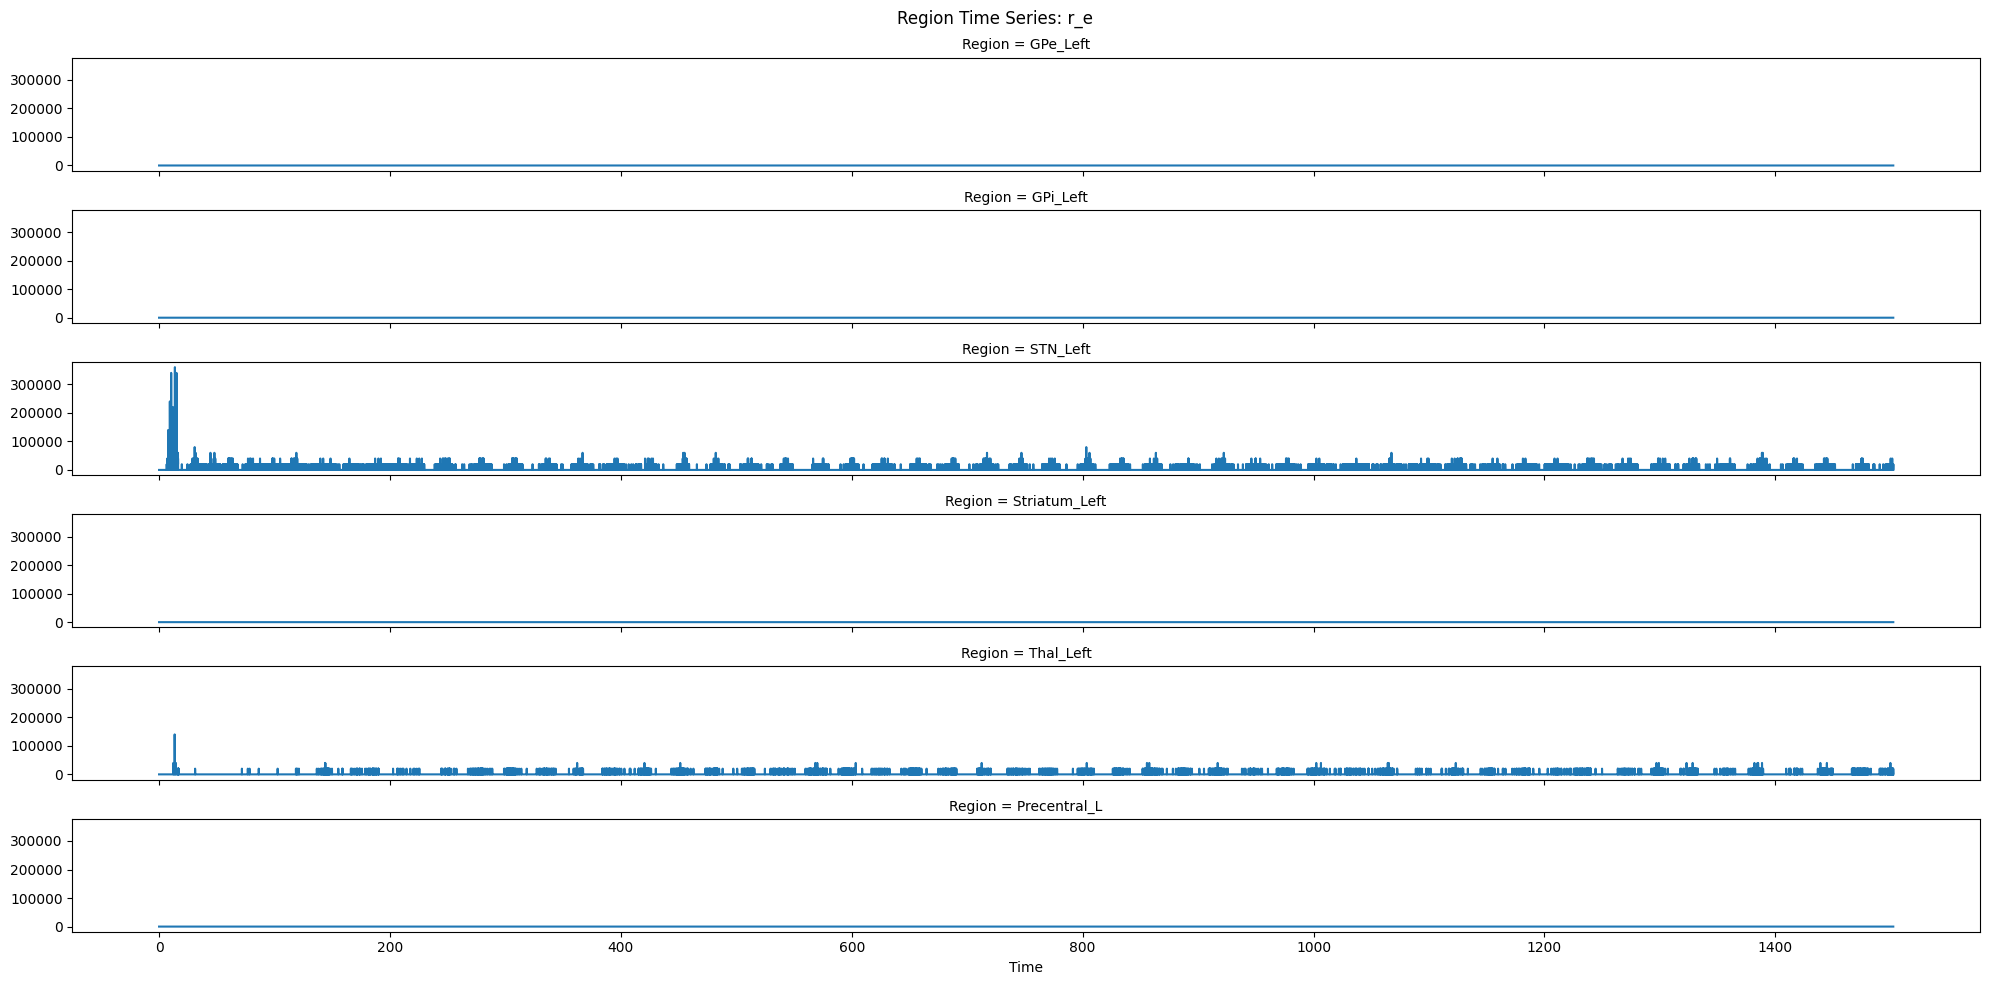

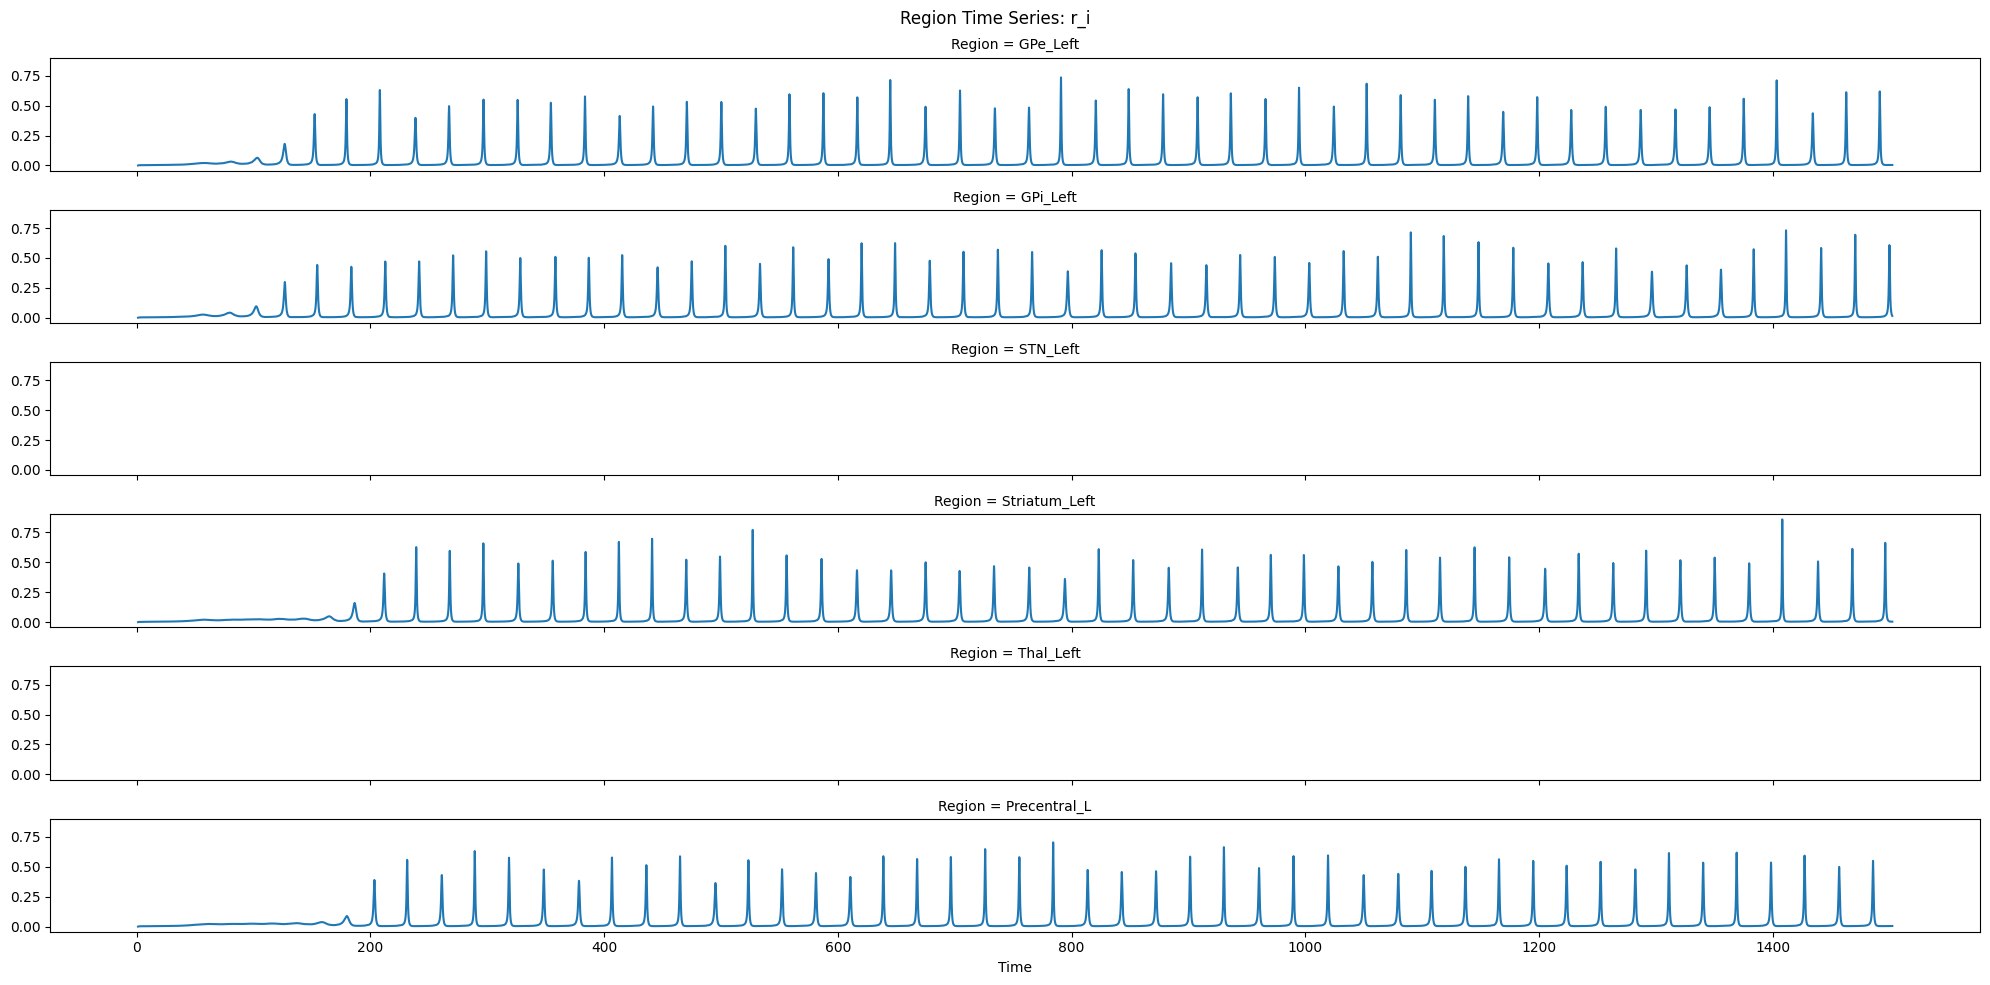

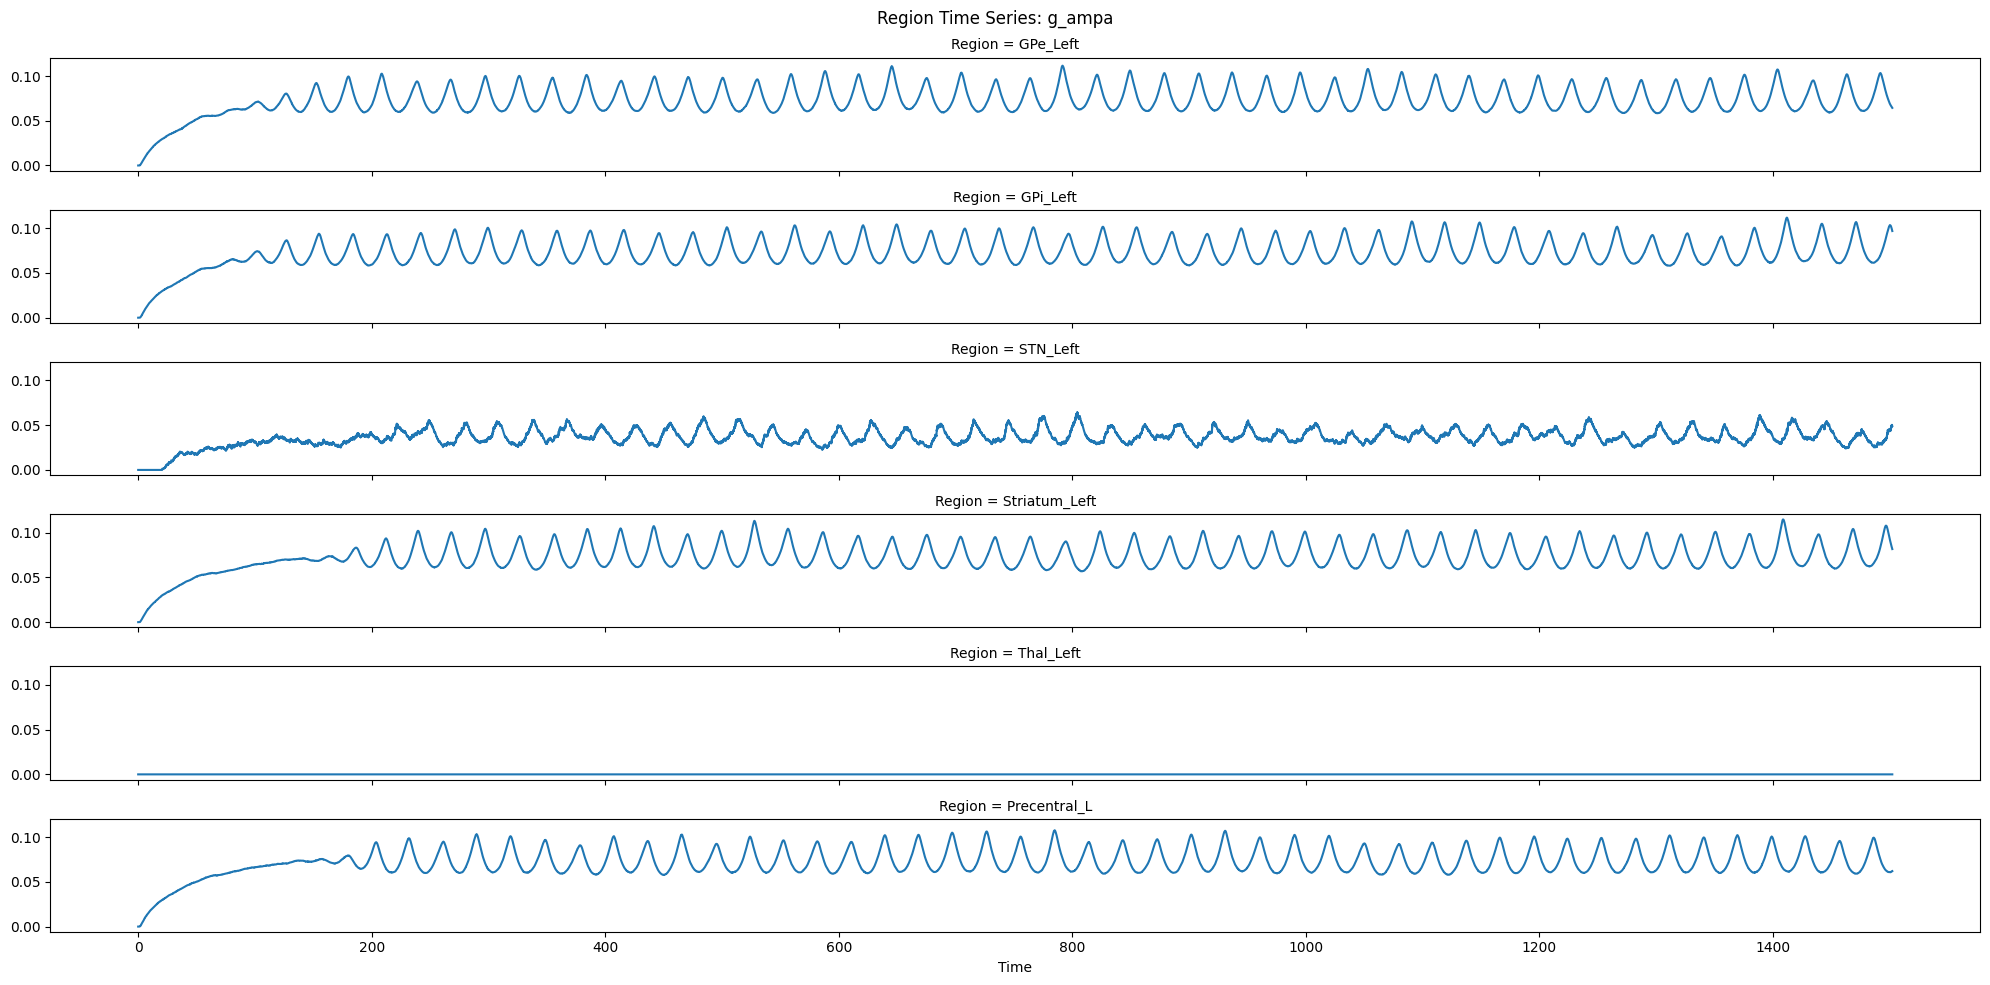

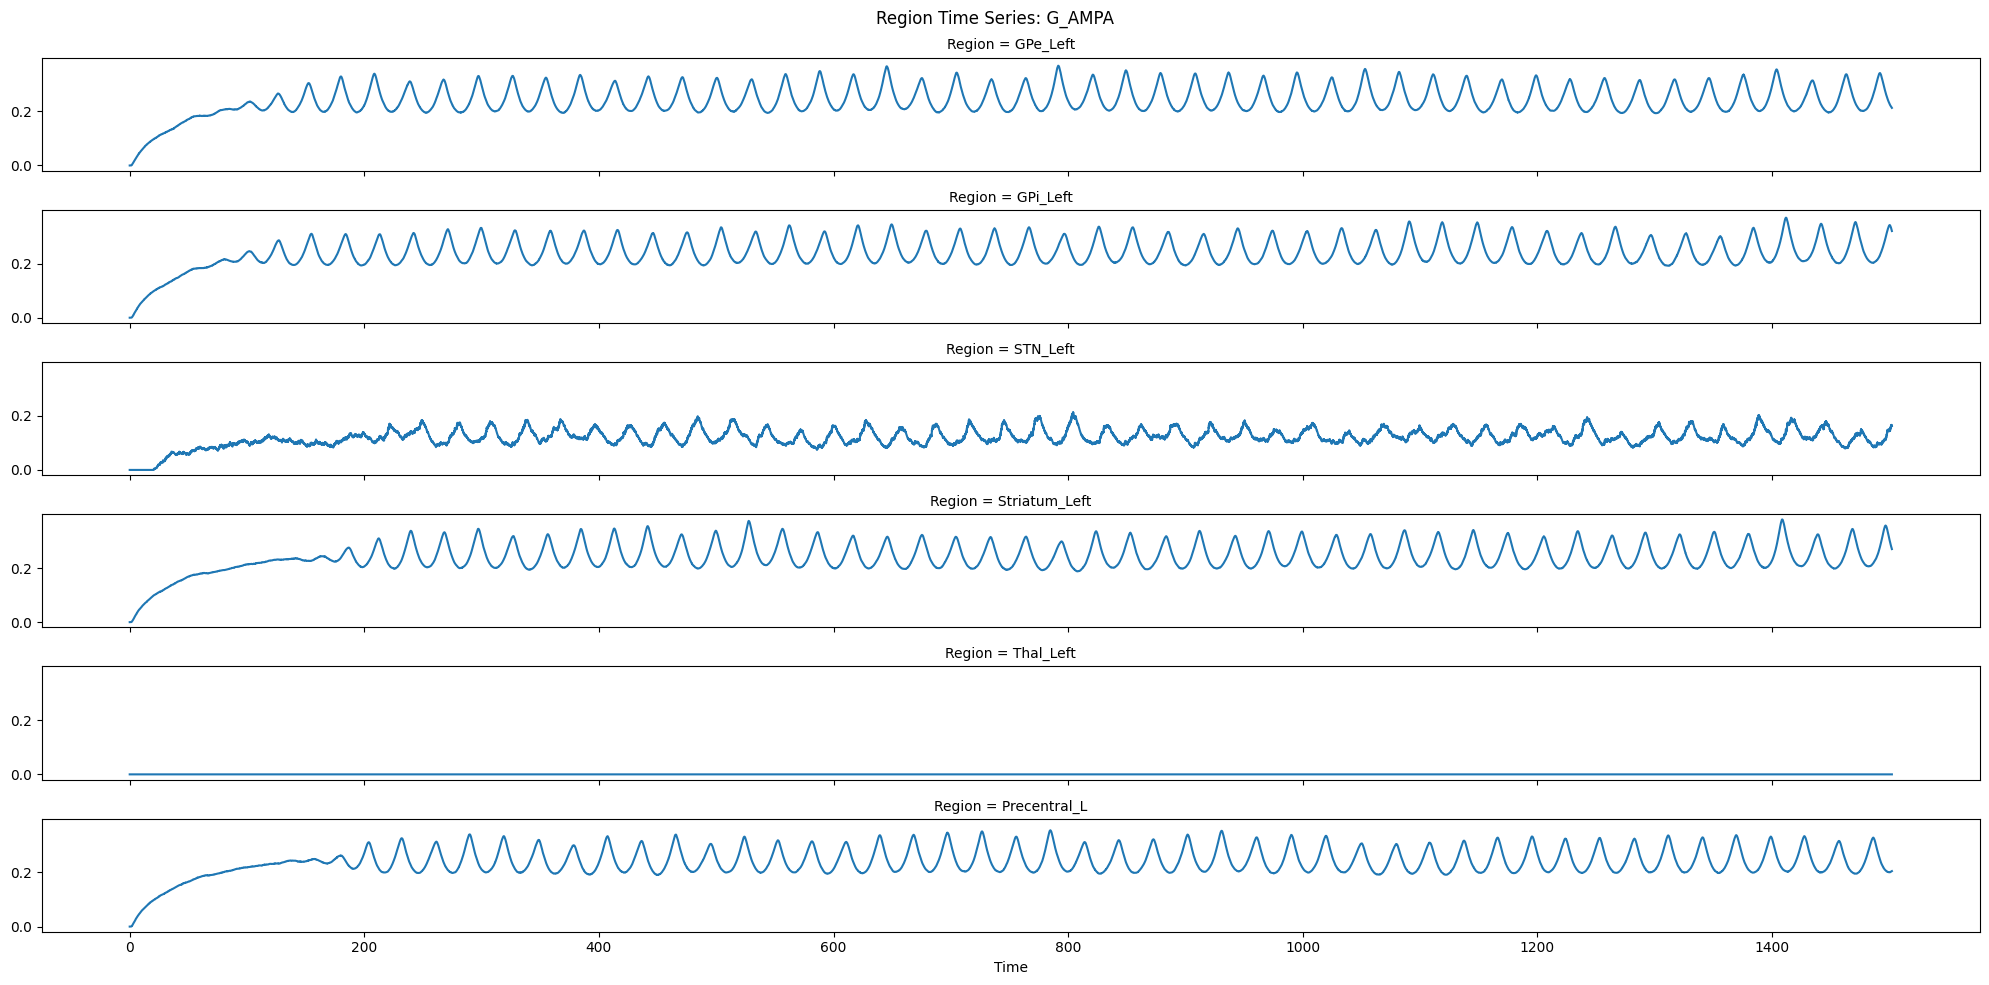

In [30]:
# Plot TVB time series
source_ts[:, 0].plot_timeseries(plotter_config=plotter.config, 
                          hue="Region" if source_ts.shape[2] > MAX_REGIONS_IN_ROWS else None, 
                          per_variable=source_ts.shape[1] > MAX_VARS_IN_COLS, 
                          figsize=FIGSIZE);

source_ts[:, 1].plot_timeseries(plotter_config=plotter.config, 
                          hue="Region" if source_ts.shape[2] > MAX_REGIONS_IN_ROWS else None, 
                          per_variable=source_ts.shape[1] > MAX_VARS_IN_COLS, 
                          figsize=FIGSIZE);

source_ts[:, 6].plot_timeseries(plotter_config=plotter.config, 
                          hue="Region" if source_ts.shape[2] > MAX_REGIONS_IN_ROWS else None, 
                          per_variable=source_ts.shape[1] > MAX_VARS_IN_COLS, 
                          figsize=FIGSIZE);

source_ts[:, 12].plot_timeseries(plotter_config=plotter.config, 
                          hue="Region" if source_ts.shape[2] > MAX_REGIONS_IN_ROWS else None, 
                          per_variable=source_ts.shape[1] > MAX_VARS_IN_COLS, 
                          figsize=FIGSIZE);

In [31]:
# # TVB time series raster plot:
# if source_ts.number_of_labels > MIN_REGIONS_FOR_RASTER_PLOT:
#     source_ts.plot_raster(plotter_config=plotter.config, 
#                           per_variable=source_ts.shape[1] > MAX_VARS_IN_COLS,
#                           figsize=FIGSIZE);

2026-03-31 09:38:58,078 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:38:58,079 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:38:58,134 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:38:58,134 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:38:58,194 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:38:58,195 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


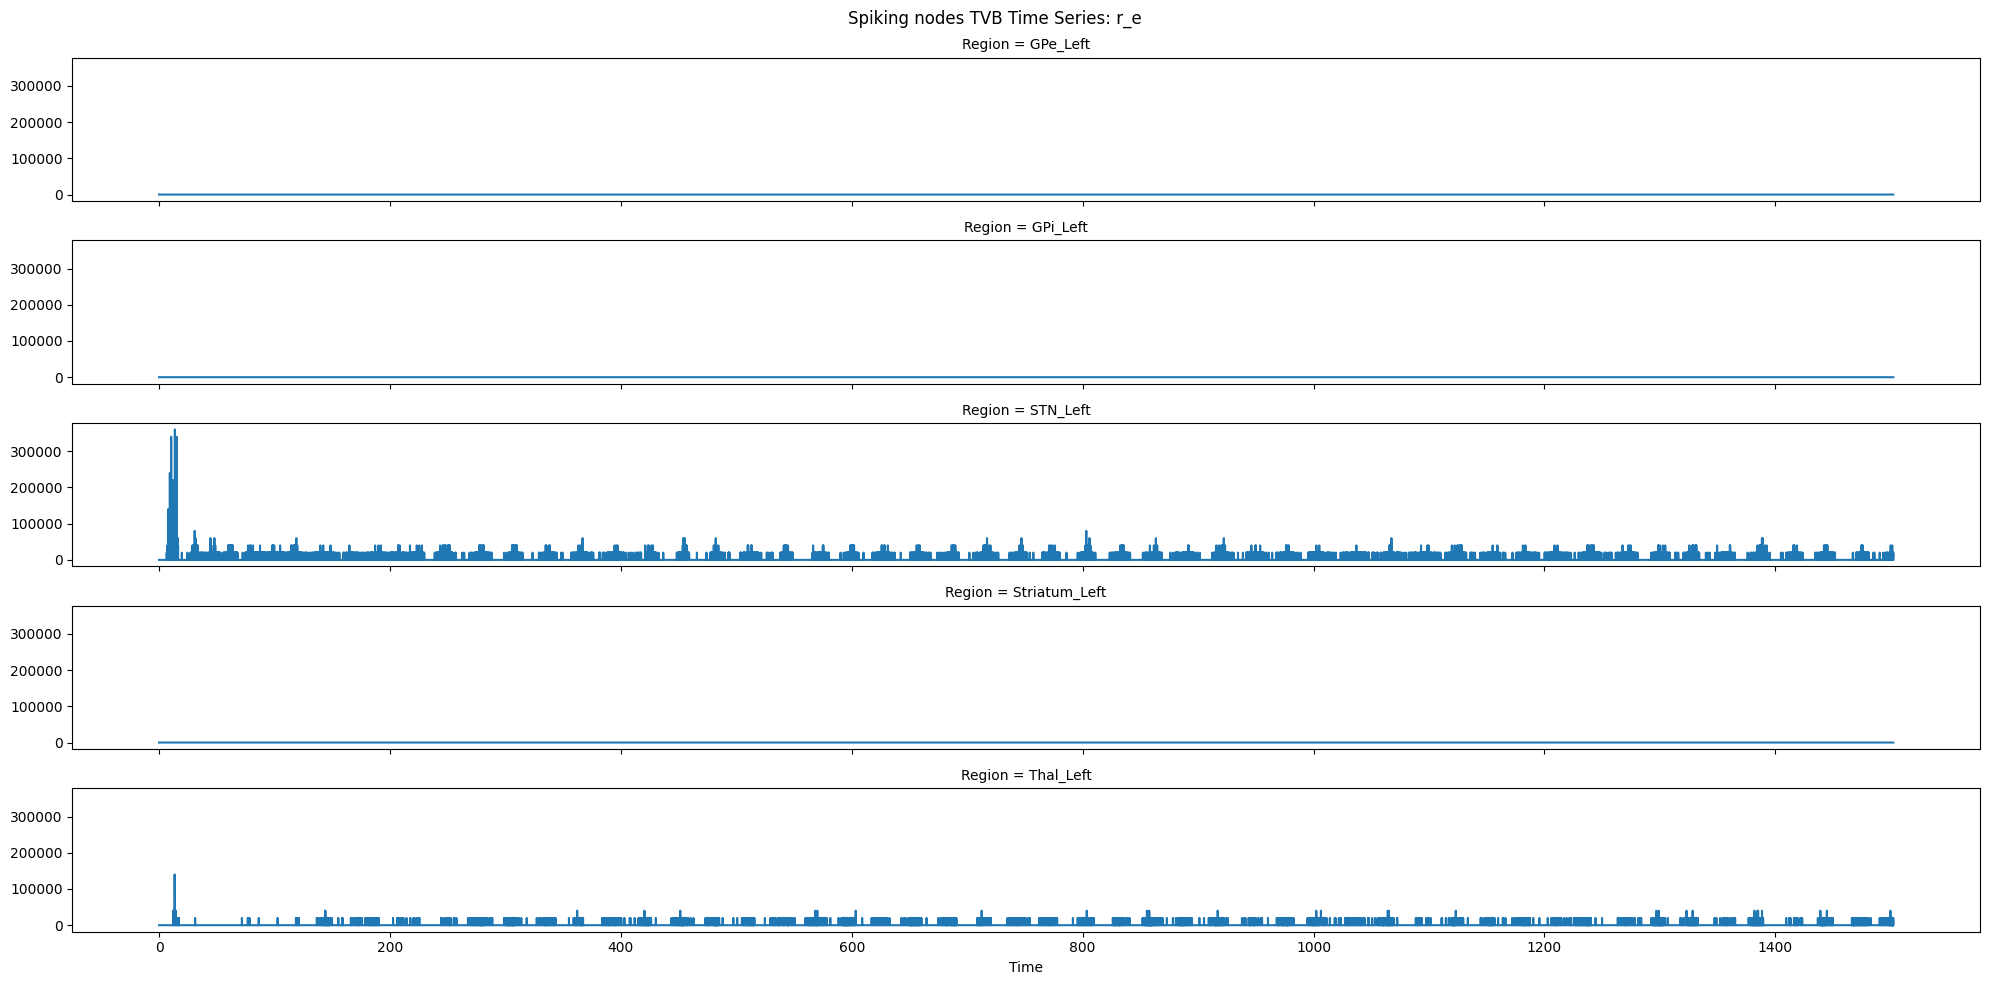

2026-03-31 09:38:58,854 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:38:58,855 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:38:58,914 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:38:58,914 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


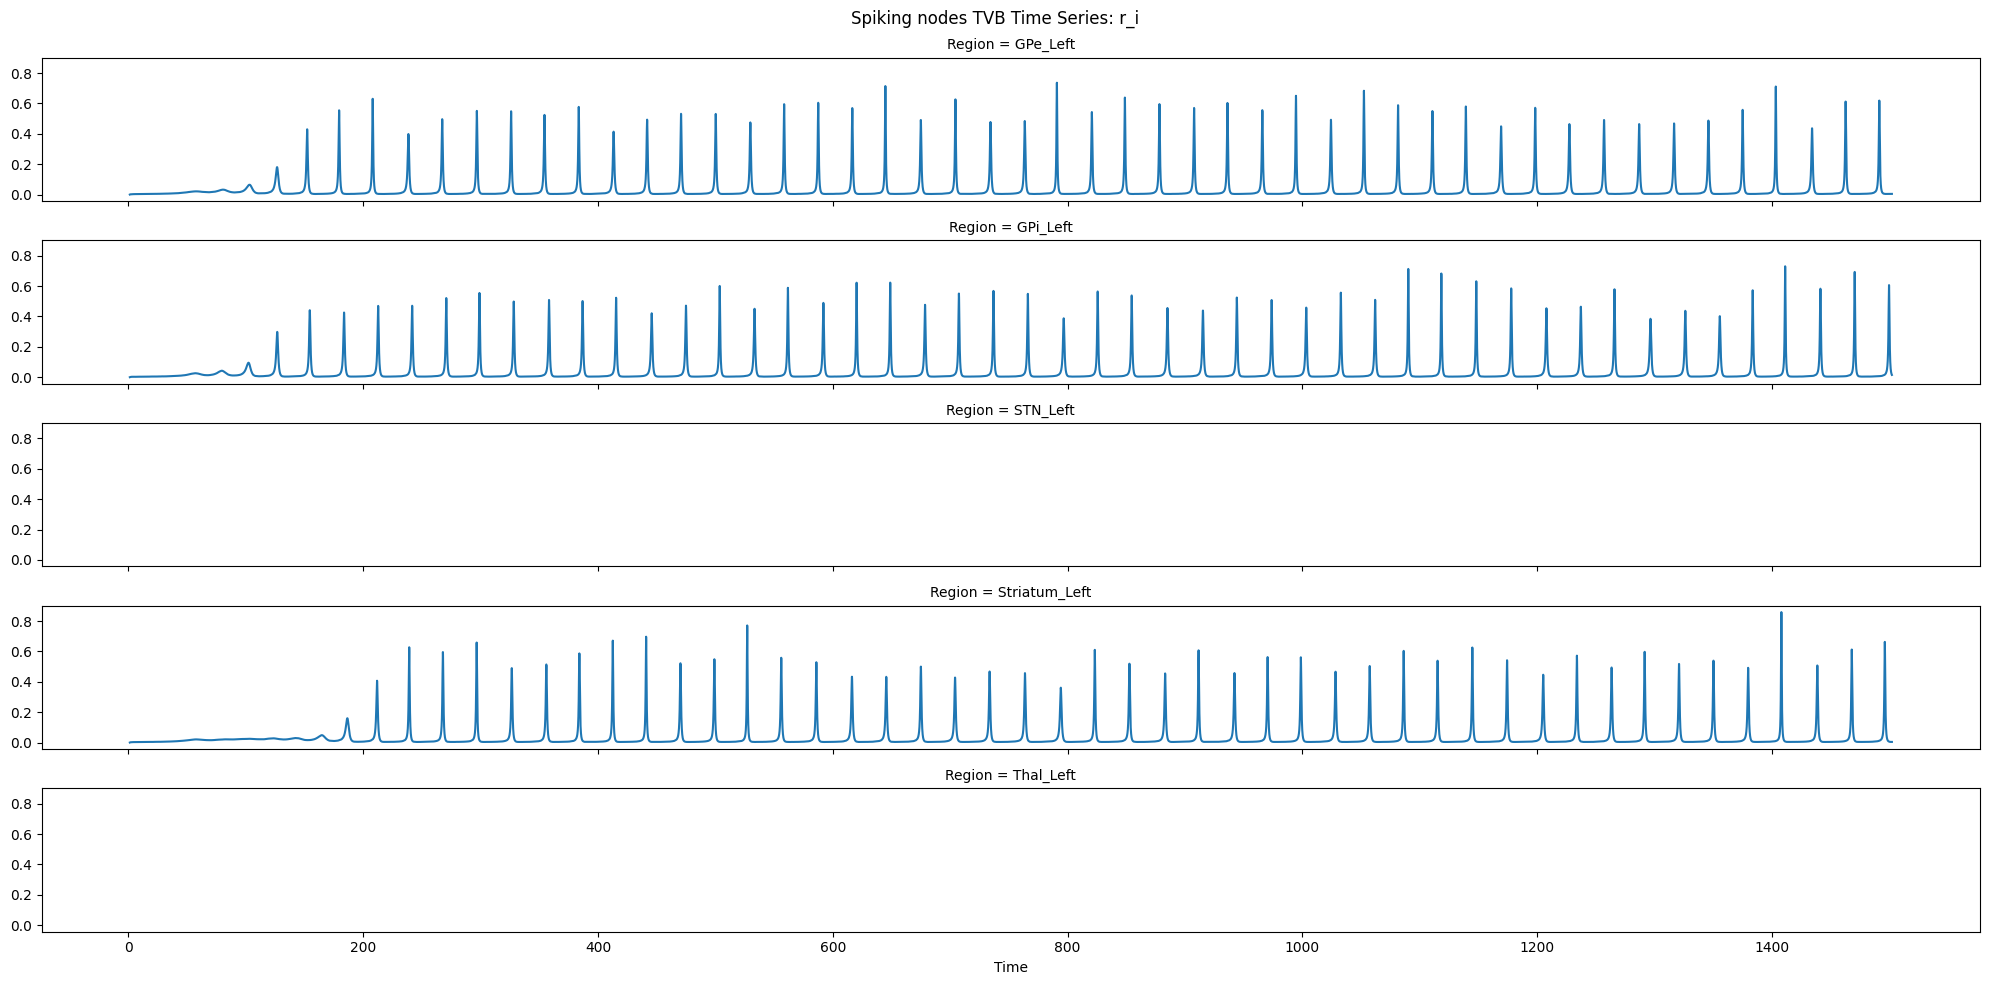

2026-03-31 09:38:59,577 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:38:59,577 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:38:59,638 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:38:59,639 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


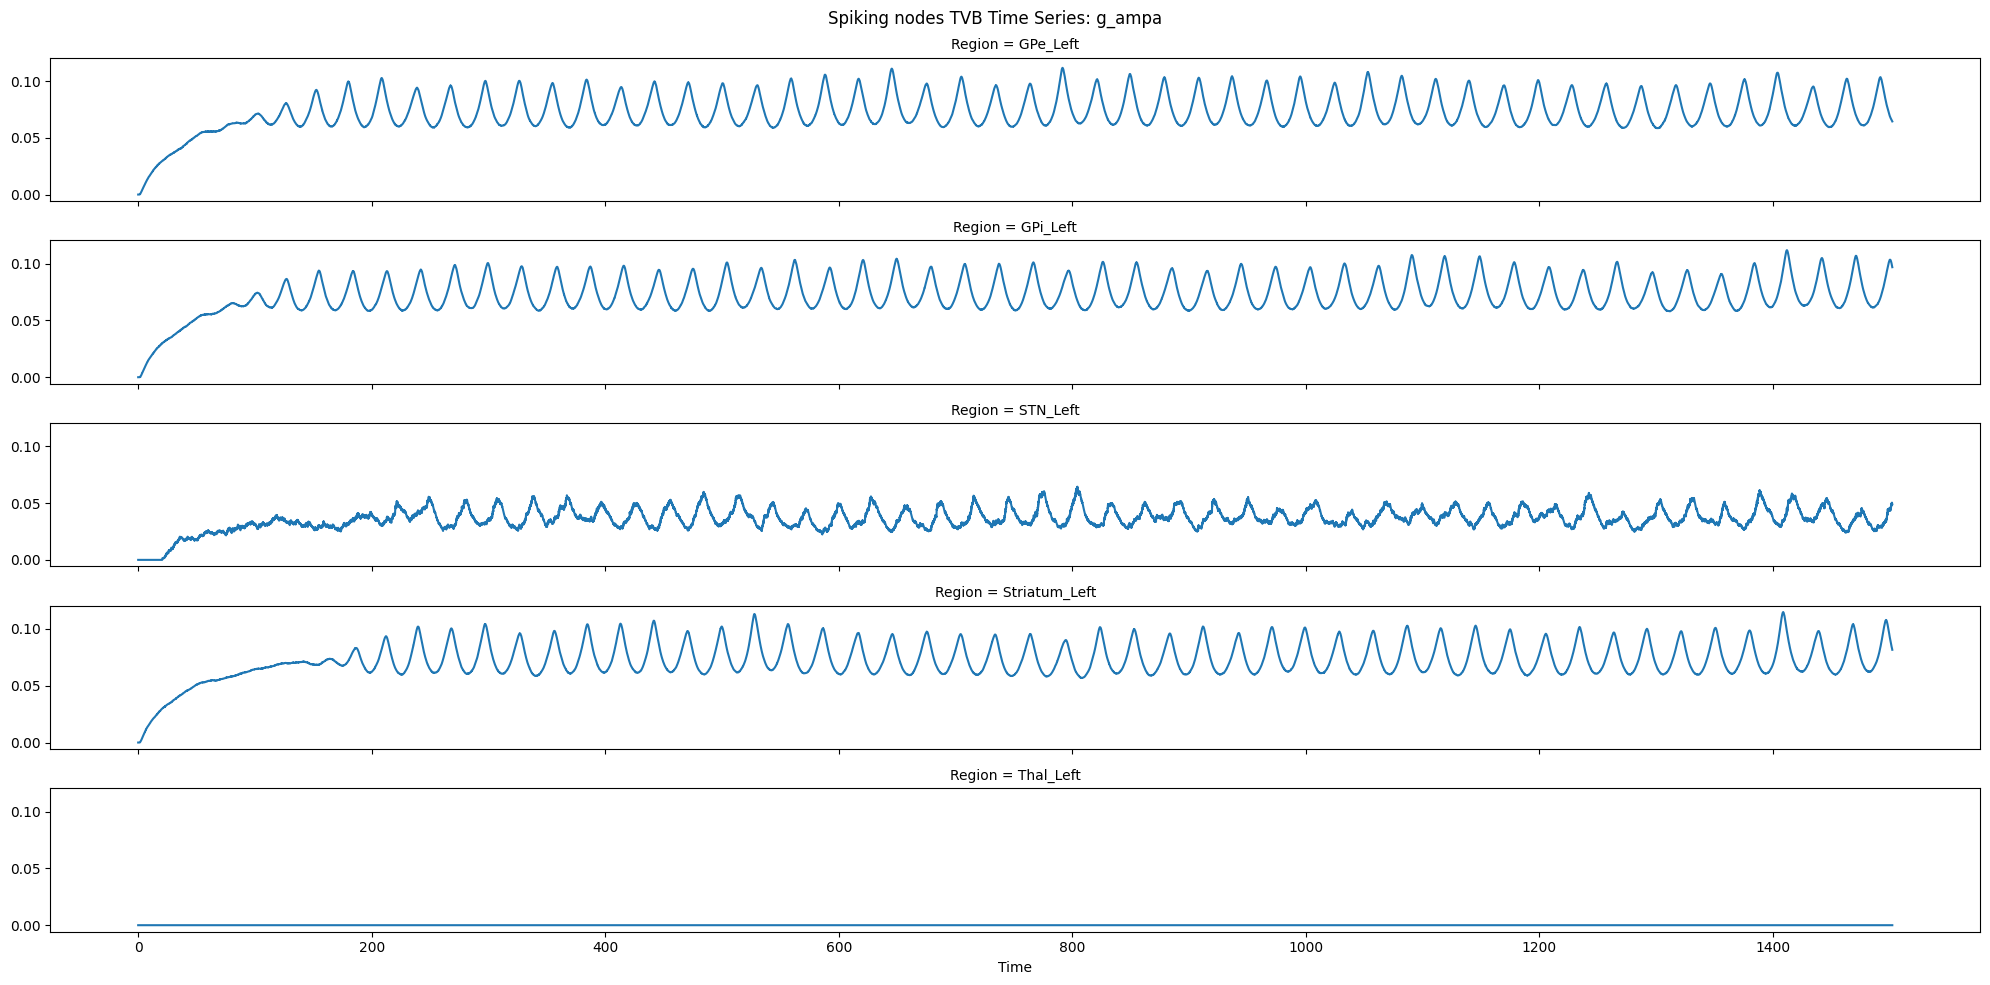

2026-03-31 09:39:00,289 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:00,289 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:00,351 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:00,352 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


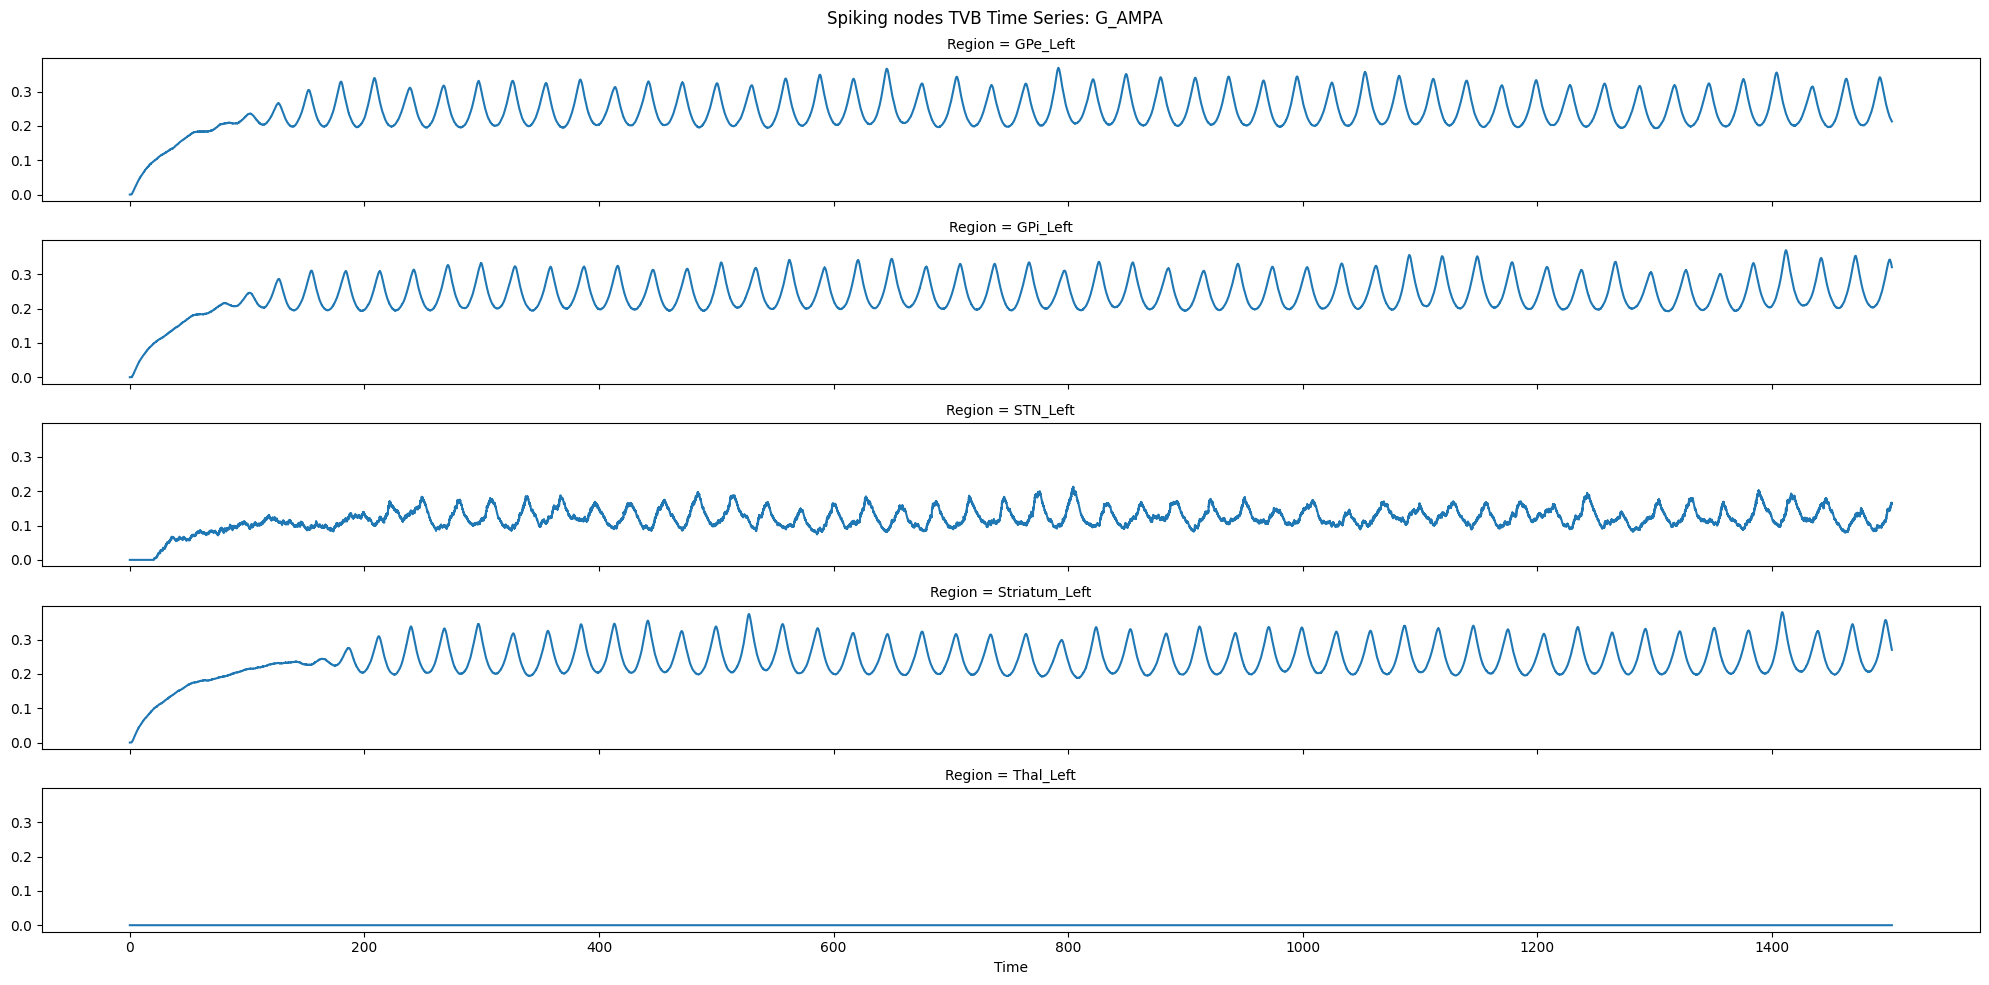

In [32]:
# Focus on the nodes modelled in ANNarchy: 
n_spiking_nodes = len(spiking_nodes_ids)
source_ts_ann = source_ts[:, :, spiking_nodes_ids]
source_ts_ann[:, 0].plot_timeseries(plotter_config=plotter.config, 
                               hue="Region" if source_ts_ann.shape[2] > MAX_REGIONS_IN_ROWS else None, 
                               per_variable=source_ts_ann.shape[1] > MAX_VARS_IN_COLS, 
                               figsize=FIGSIZE, figname="Spiking nodes TVB Time Series");

source_ts_ann[:, 1].plot_timeseries(plotter_config=plotter.config, 
                               hue="Region" if source_ts_ann.shape[2] > MAX_REGIONS_IN_ROWS else None, 
                               per_variable=source_ts_ann.shape[1] > MAX_VARS_IN_COLS, 
                               figsize=FIGSIZE, figname="Spiking nodes TVB Time Series");


source_ts_ann[:, 6].plot_timeseries(plotter_config=plotter.config, 
                               hue="Region" if source_ts_ann.shape[2] > MAX_REGIONS_IN_ROWS else None, 
                               per_variable=source_ts_ann.shape[1] > MAX_VARS_IN_COLS, 
                               figsize=FIGSIZE, figname="Spiking nodes TVB Time Series");

source_ts_ann[:, 12].plot_timeseries(plotter_config=plotter.config, 
                               hue="Region" if source_ts_ann.shape[2] > MAX_REGIONS_IN_ROWS else None, 
                               per_variable=source_ts_ann.shape[1] > MAX_VARS_IN_COLS, 
                               figsize=FIGSIZE, figname="Spiking nodes TVB Time Series");

In [33]:
# # Focus on the nodes modelled in ANNarchy: raster plot
# if source_ts_ann.number_of_labels > MIN_REGIONS_FOR_RASTER_PLOT:
#     source_ts_ann.plot_raster(plotter_config=plotter.config, 
#                                per_variable=source_ts_ann.shape[1] > MAX_VARS_IN_COLS,
#                                figsize=FIGSIZE, figname="Spiking nodes TVB Time Series Raster");

### Interactive time series plot

In [34]:
# # ...interactively as well
# # For interactive plotting:
# %matplotlib notebook 
# plotter.plot_timeseries_interactive(TimeSeriesRegion().from_xarray_DataArray(source_ts._data, 
#                                                                              connectivity=source_ts.connectivity))

### Spiking Network plots

In [35]:
from tvb_multiscale.core.data_analysis.spiking_network_analyser import SpikingNetworkAnalyser
# Create a SpikingNetworkAnalyzer:
spikeNet_analyzer = \
    SpikingNetworkAnalyser(spikeNet=annarchy_network,
                           start_time=period, end_time=simulation_length, 
                           period=period, transient=transient, # transient,
                           time_series_output_type="TVB", return_data=True,
                           # elephant_mean_firing_rate=False,
                           force_homogeneous_results=True, connectivity=simulator.connectivity)

### Plot spikes' raster and mean spike rates and correlations

In [36]:
# Spikes rates and correlations per Population and Region
spikes_res = \
    spikeNet_analyzer.\
        compute_spikeNet_spikes_rates_and_correlations(
            populations_devices=None, regions=None,
            rates_methods=[], rates_kwargs=[{}],rate_results_names=[],
            corrs_methods=[], corrs_kwargs=[{}], corrs_results_names=[], bin_kwargs={},
            data_method=spikeNet_analyzer.get_spikes_from_device, data_kwargs={},
            return_devices=False
        );

2026-03-31 09:39:01,008 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model  for  created!
2026-03-31 09:39:01,008 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model  for  created!
2026-03-31 09:39:02,812 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:02,813 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


/home/docker/packages/tvb-root/tvb_contrib/tvb/contrib/scripts/utils/data_structures_utils.py:894: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'Region' ('Region',) The recommendation is to set join explicitly for this case.
  data = concat(data, Index(data_keys, name=concat_dim_name), fill_value=fill_value)
/home/docker/packages/tvb-root/tvb_contrib/tvb/contrib/scripts/utils/data_structures_utils.py:894: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'Region' ('Region',) The recommendation is to set join explici

<xarray.DataArray "Mean Populations' Spikes' Rates" (Population: 4, Region: 5)> Size: 160B
array([[        nan,         nan, 20.5128904 ,         nan,  7.23610049],
       [32.20791965, 34.78509866,         nan,         nan,         nan],
       [        nan,         nan,         nan,  0.39089488,         nan],
       [        nan,         nan,         nan,  2.17264826,         nan]])
Coordinates:
  * Population  (Population) object 32B 'E' 'I' 'IdSN' 'IiSN'
  * Region      (Region) object 40B 'GPe_Left' 'GPi_Left' ... 'Thal_Left'
<xarray.DataArray "Populations' Correlation Coefficient" (Population_i: 4,
                                                          Population_j: 4,
                                                          Region_i: 5,
                                                          Region_j: 5)> Size: 3kB
array([[[[        nan,         nan,         nan,         nan,
                  nan],
         [        nan,         nan,         nan,         nan,
            

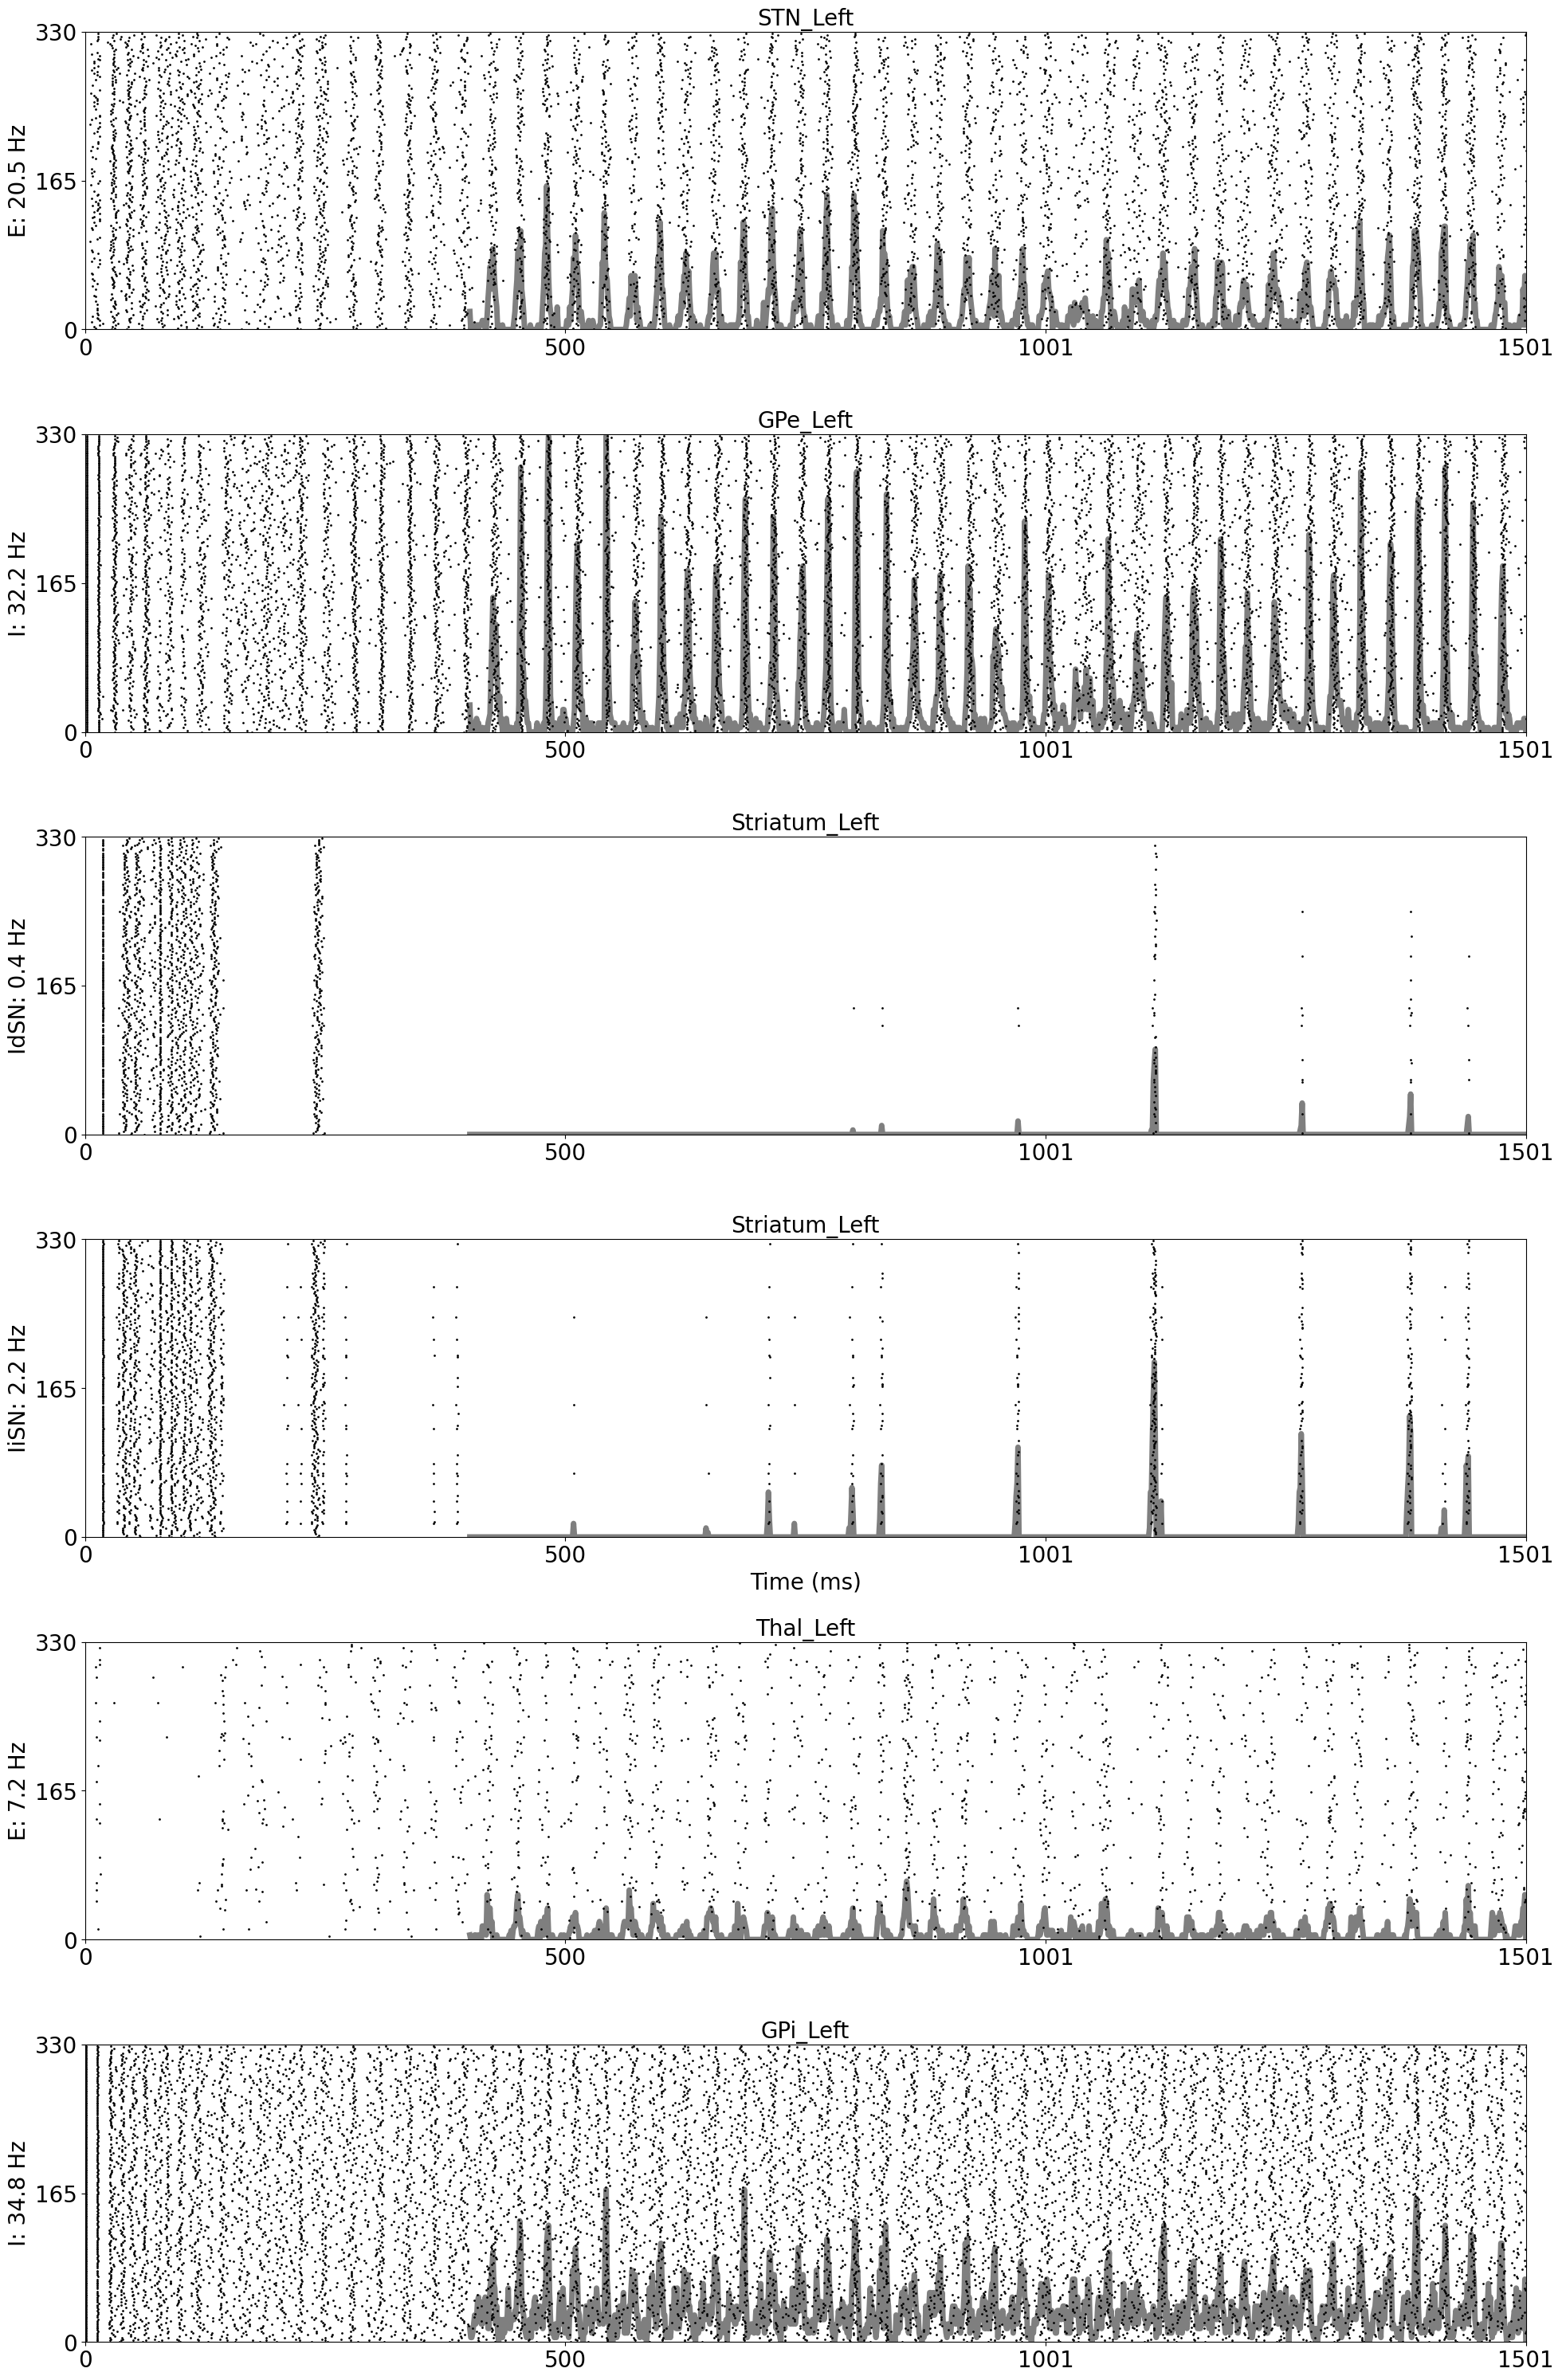

In [37]:
if spikes_res:
    print(spikes_res["mean_rate"])
    print(spikes_res["spikes_correlation_coefficient"])
    # Plot spikes' rasters together with mean population's spikes' rates' time series
    if plotter:
        plotter.config.FONTSIZE = 20 # plotter.config.LARGE_FONTSIZE  # LARGE = 12, default = 10
        plotter.plot_spike_events(spikes_res["spikes"], time_series=spikes_res["mean_rate_time_series"], 
                                  mean_results=spikes_res["mean_rate"], #
                                  stimulus=[start_stimulus] if simulation_mode != "rs" else None,
                                  mean_results_units="Hz", stimulus_linewidth=5.0,
                                  spikes_markersize=1.0, figsize=(20, 40), 
                                  n_y_ticks=3, n_time_ticks=4, show_time_axis=True, 
                                  time_axis_min=0.0, time_axis_max=simulation_length
                                 ) # 
        from tvb_multiscale.core.plot.correlations_plot import plot_correlations
        plot_correlations(spikes_res["spikes_correlation_coefficient"], plotter)

In [38]:
if spikes_res:
    print("Mean spike rates:")
    for pop in spikes_res["mean_rate"].coords["Population"]:
        for reg in spikes_res["mean_rate"].coords["Region"]:
            if not np.isnan(spikes_res["mean_rate"].loc[pop, reg]):
                print("%s - %s: %0.1f" % (pop.values.item().split("_spikes")[0], reg.values.item(), 
                                       spikes_res["mean_rate"].loc[pop, reg].values.item()))

    savemat(os.path.join(config.out.FOLDER_RES, "spikes_mean_rates.mat"), spikes_res["mean_rate"].to_dict())


Mean spike rates:
E - STN_Left: 20.5
E - Thal_Left: 7.2
I - GPe_Left: 32.2
I - GPi_Left: 34.8
IdSN - Striatum_Left: 0.4
IiSN - Striatum_Left: 2.2


In [39]:
spikeNet_analyzer.resample = True
spikes_sync = None
spikes_sync = \
    spikeNet_analyzer.compute_spikeNet_synchronization(populations_devices=None, regions=None,
                                                       comp_methods=[spikeNet_analyzer.compute_spikes_sync, 
                                                                     spikeNet_analyzer.compute_spikes_sync_time_series, 
                                                                     spikeNet_analyzer.compute_spikes_distance, 
                                                                     spikeNet_analyzer.compute_spikes_distance_time_series,
                                                                     spikeNet_analyzer.compute_spikes_isi_distance, 
                                                                     spikeNet_analyzer.compute_spikes_isi_distance_time_series],
                                                       computations_kwargs=[{}], data_kwargs={},
                                                       return_spikes_trains=False, return_devices=False)
# print(spikes_sync)


2026-03-31 09:39:03,900 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model  for  created!
2026-03-31 09:39:03,900 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model  for  created!
2026-03-31 09:39:15,560 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:15,561 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:15,569 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:15,569 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:15,577 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable


/home/docker/packages/tvb-root/tvb_contrib/tvb/contrib/scripts/utils/data_structures_utils.py:894: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'Region' ('Region',) The recommendation is to set join explicitly for this case.
  data = concat(data, Index(data_keys, name=concat_dim_name), fill_value=fill_value)
/home/docker/packages/tvb-root/tvb_contrib/tvb/contrib/scripts/utils/data_structures_utils.py:894: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'Region' ('Region',) The recommendation is to set join explici

2026-03-31 09:39:15,594 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:15,595 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:15,604 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:15,605 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:15,613 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:15,614 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:15,623 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:15,624 - WARNING - tvb.contrib.scripts.da

<Figure size 640x480 with 0 Axes>

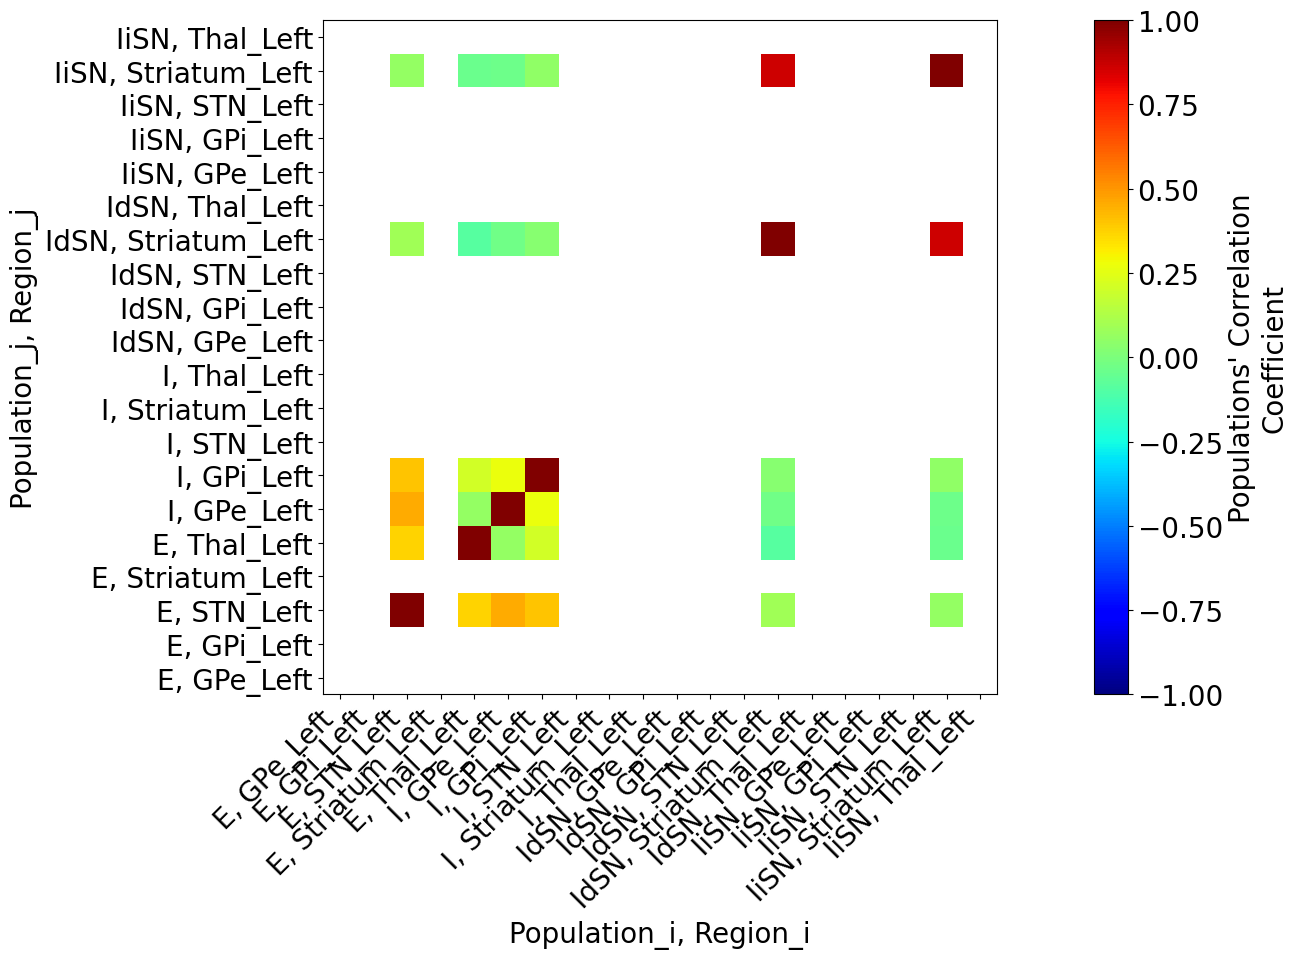

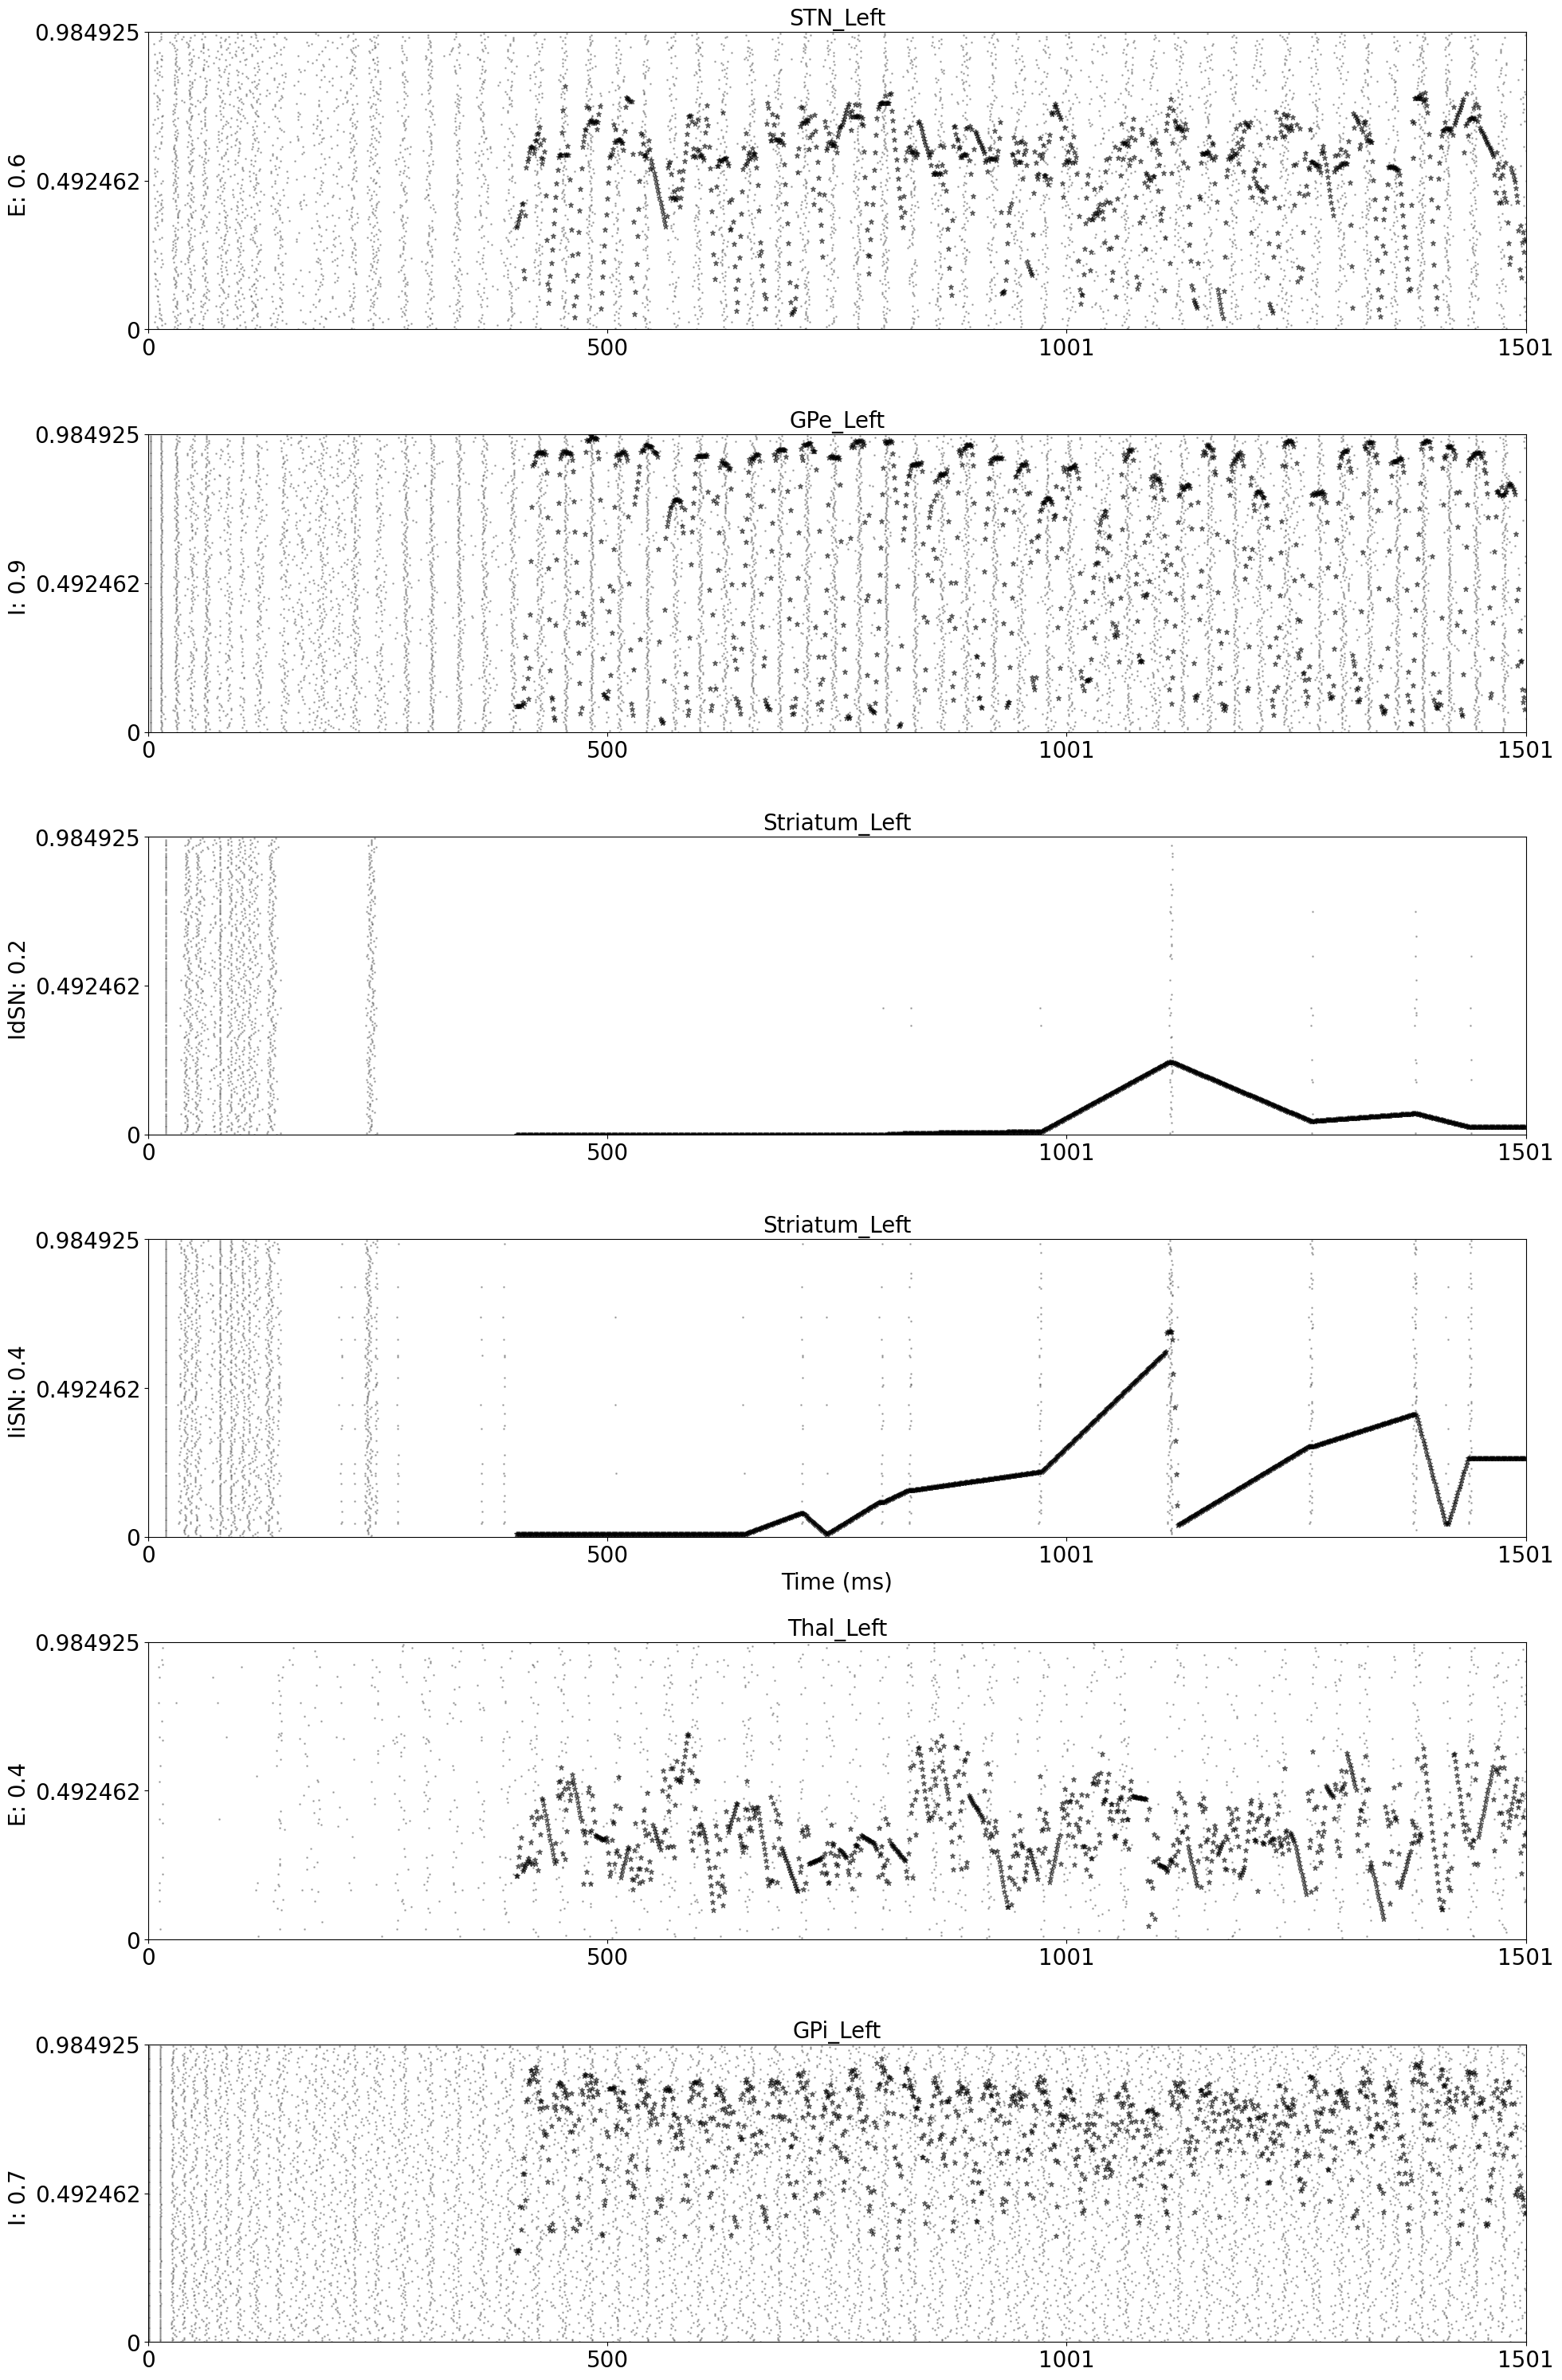

In [40]:
if spikes_sync:
    plotter.config.FONTSIZE = 20 # plotter.config.LARGE_FONTSIZE  # LARGE = 12, default = 10
    plotter.plot_spike_events(spikes_res["spikes"], 
                              time_series=spikes_sync["spikes_sync_time_series"], 
                              mean_results=spikes_sync["spikes_sync"], 
                              stimulus=[start_stimulus] if simulation_mode != "rs" else None,
                              plot_spikes=True, spikes_alpha=0.25,
                              spikes_markersize=1.0, stimulus_linewidth=5.0, time_series_marker="*", 
                              figsize=(20, 40), n_y_ticks=3, n_time_ticks=4, show_time_axis=True,
                              time_axis_min=0.0, time_axis_max=simulation_length
                                     )

2026-03-31 09:39:16,529 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:16,529 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:16,539 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:16,539 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:16,549 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:16,550 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:16,559 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:16,560 - WARNING - tvb.contrib.scripts.da

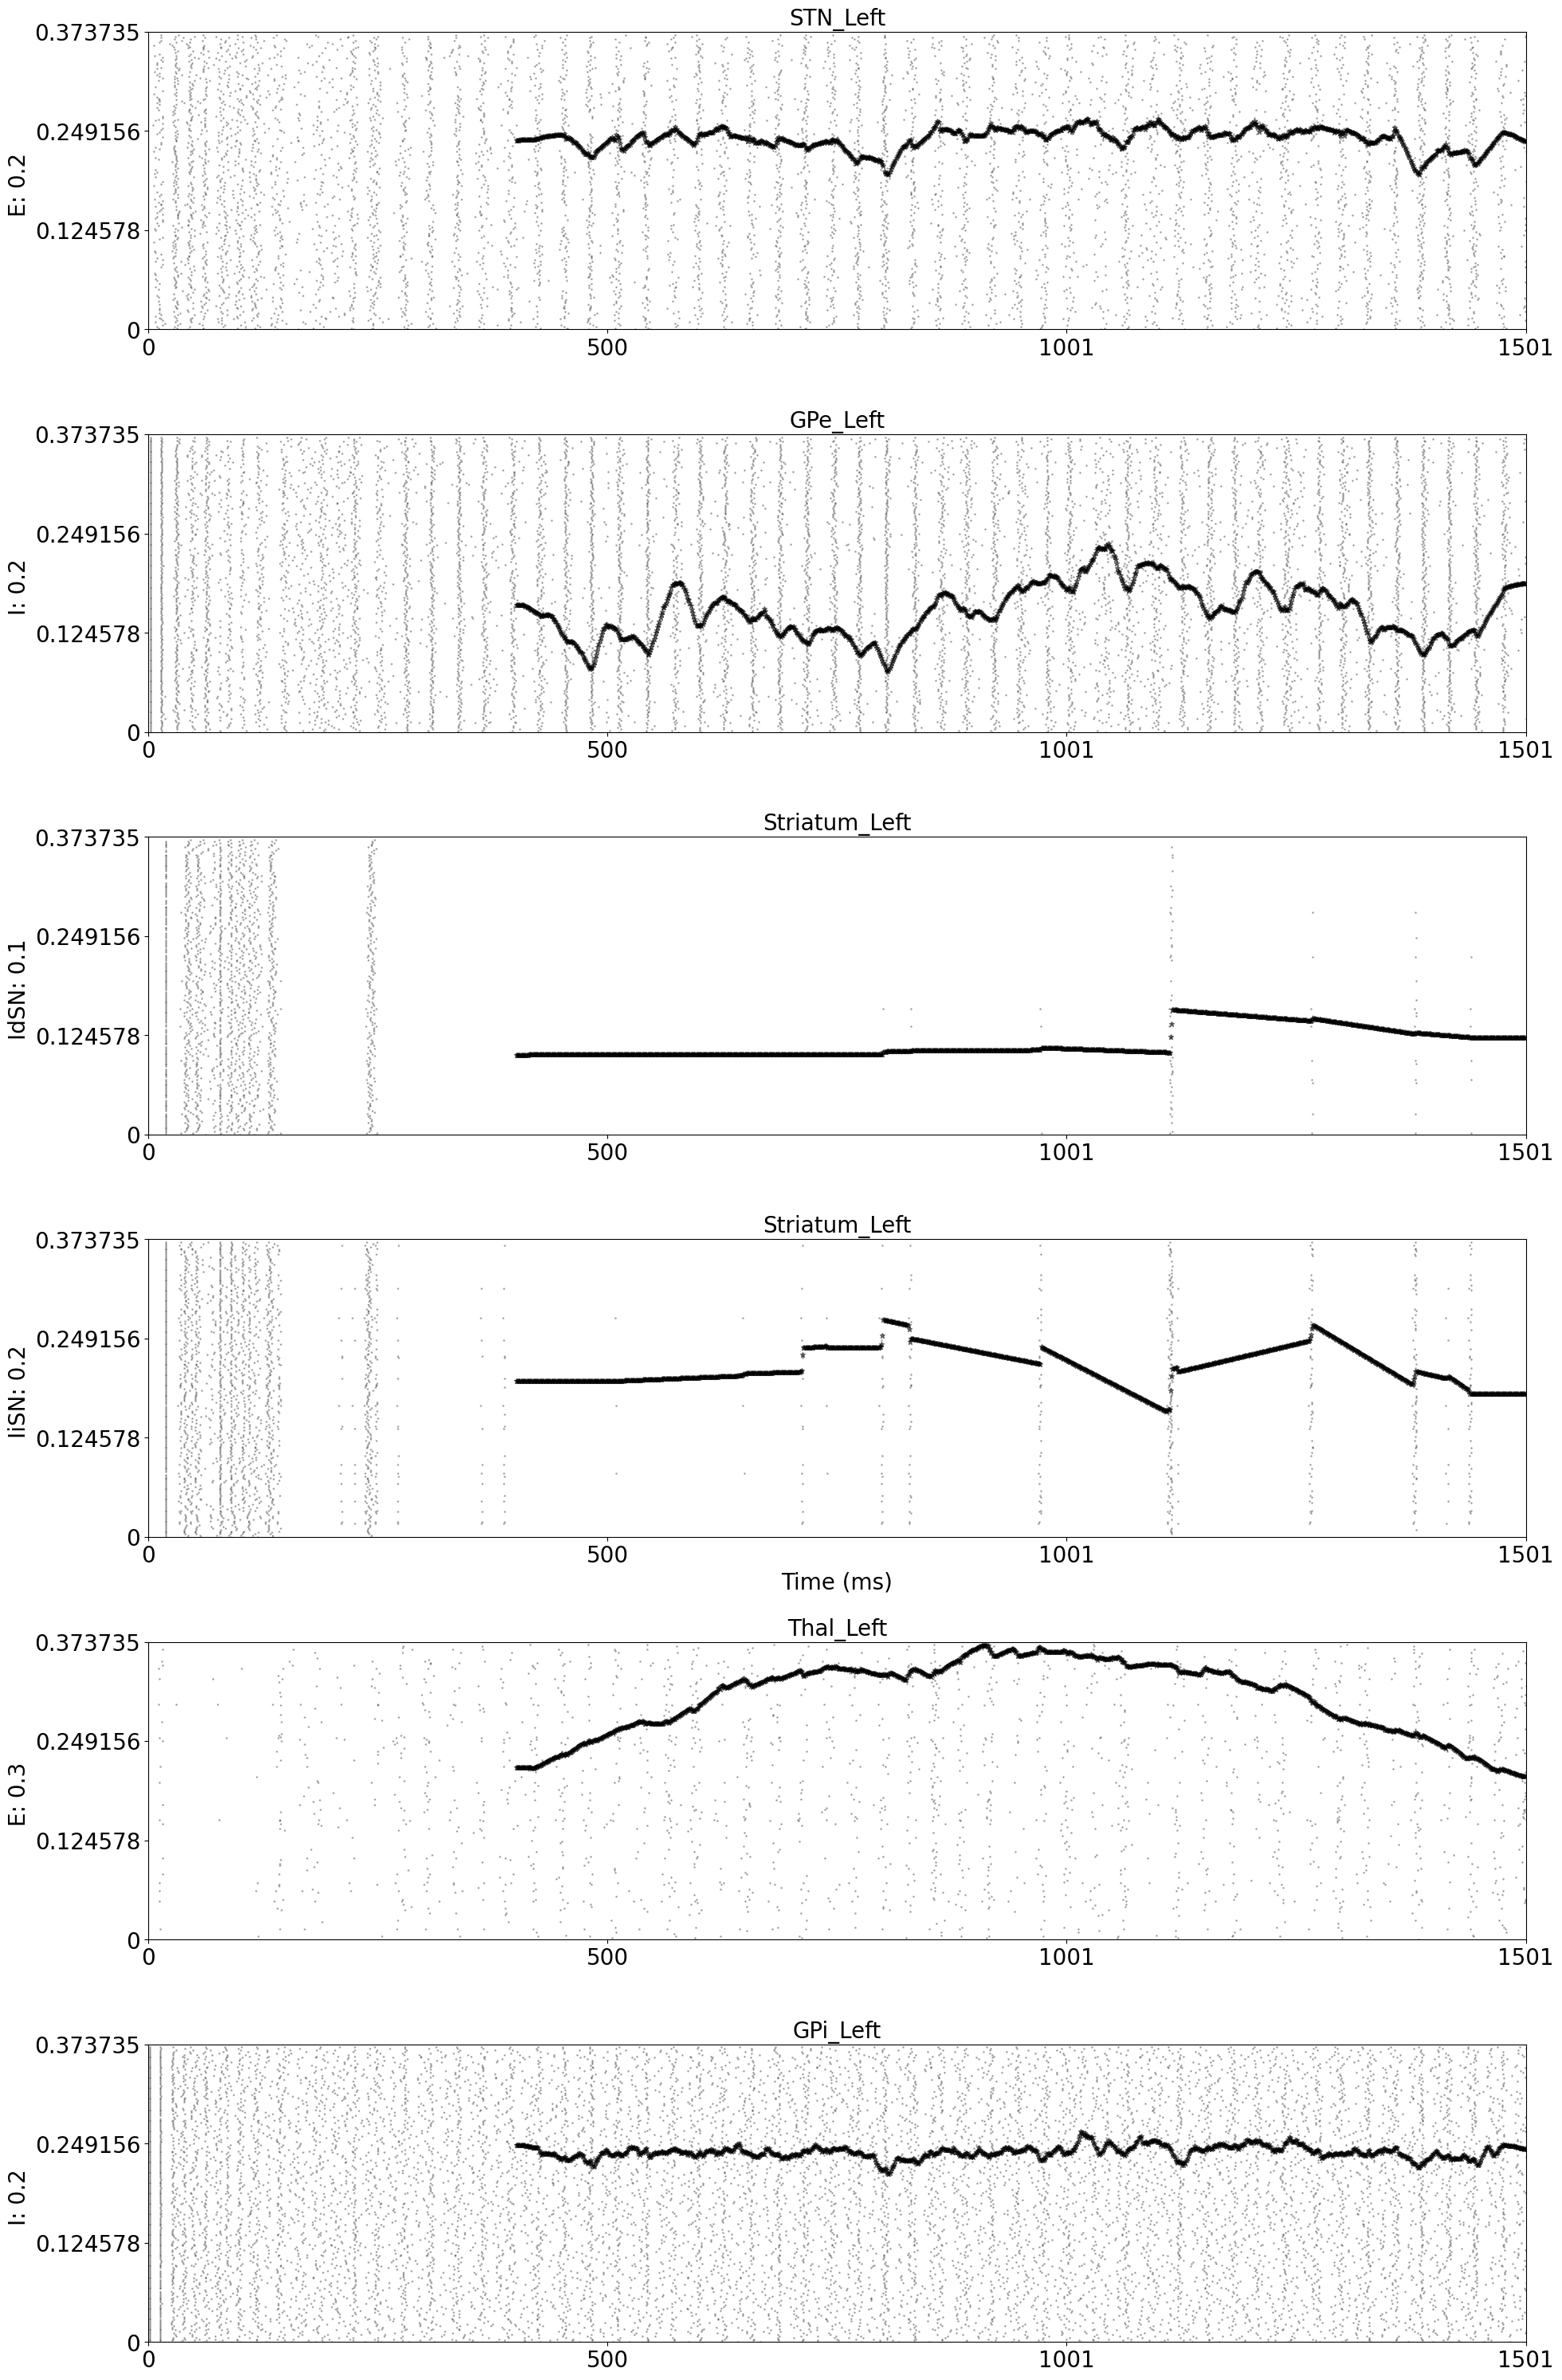

In [41]:
if spikes_sync:
    plotter.config.FONTSIZE = 20 # plotter.config.LARGE_FONTSIZE  # LARGE = 12, default = 10
    plotter.plot_spike_events(spikes_res["spikes"], 
                              time_series=spikes_sync["spikes_distance_time_series"], 
                              mean_results=spikes_sync["spikes_distance"], 
                              stimulus=[start_stimulus] if simulation_mode != "rs" else None,
                              plot_spikes=True, spikes_alpha=0.25,
                              spikes_markersize=1.0, stimulus_linewidth=5.0, time_series_marker="*", 
                              figsize=(20, 40), n_time_ticks=4, show_time_axis=True, n_y_ticks=4,
                              time_axis_min=0.0, time_axis_max=simulation_length
                                     )

2026-03-31 09:39:17,319 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:17,319 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:17,327 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:17,328 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:17,337 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:17,338 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:17,347 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:17,348 - WARNING - tvb.contrib.scripts.da

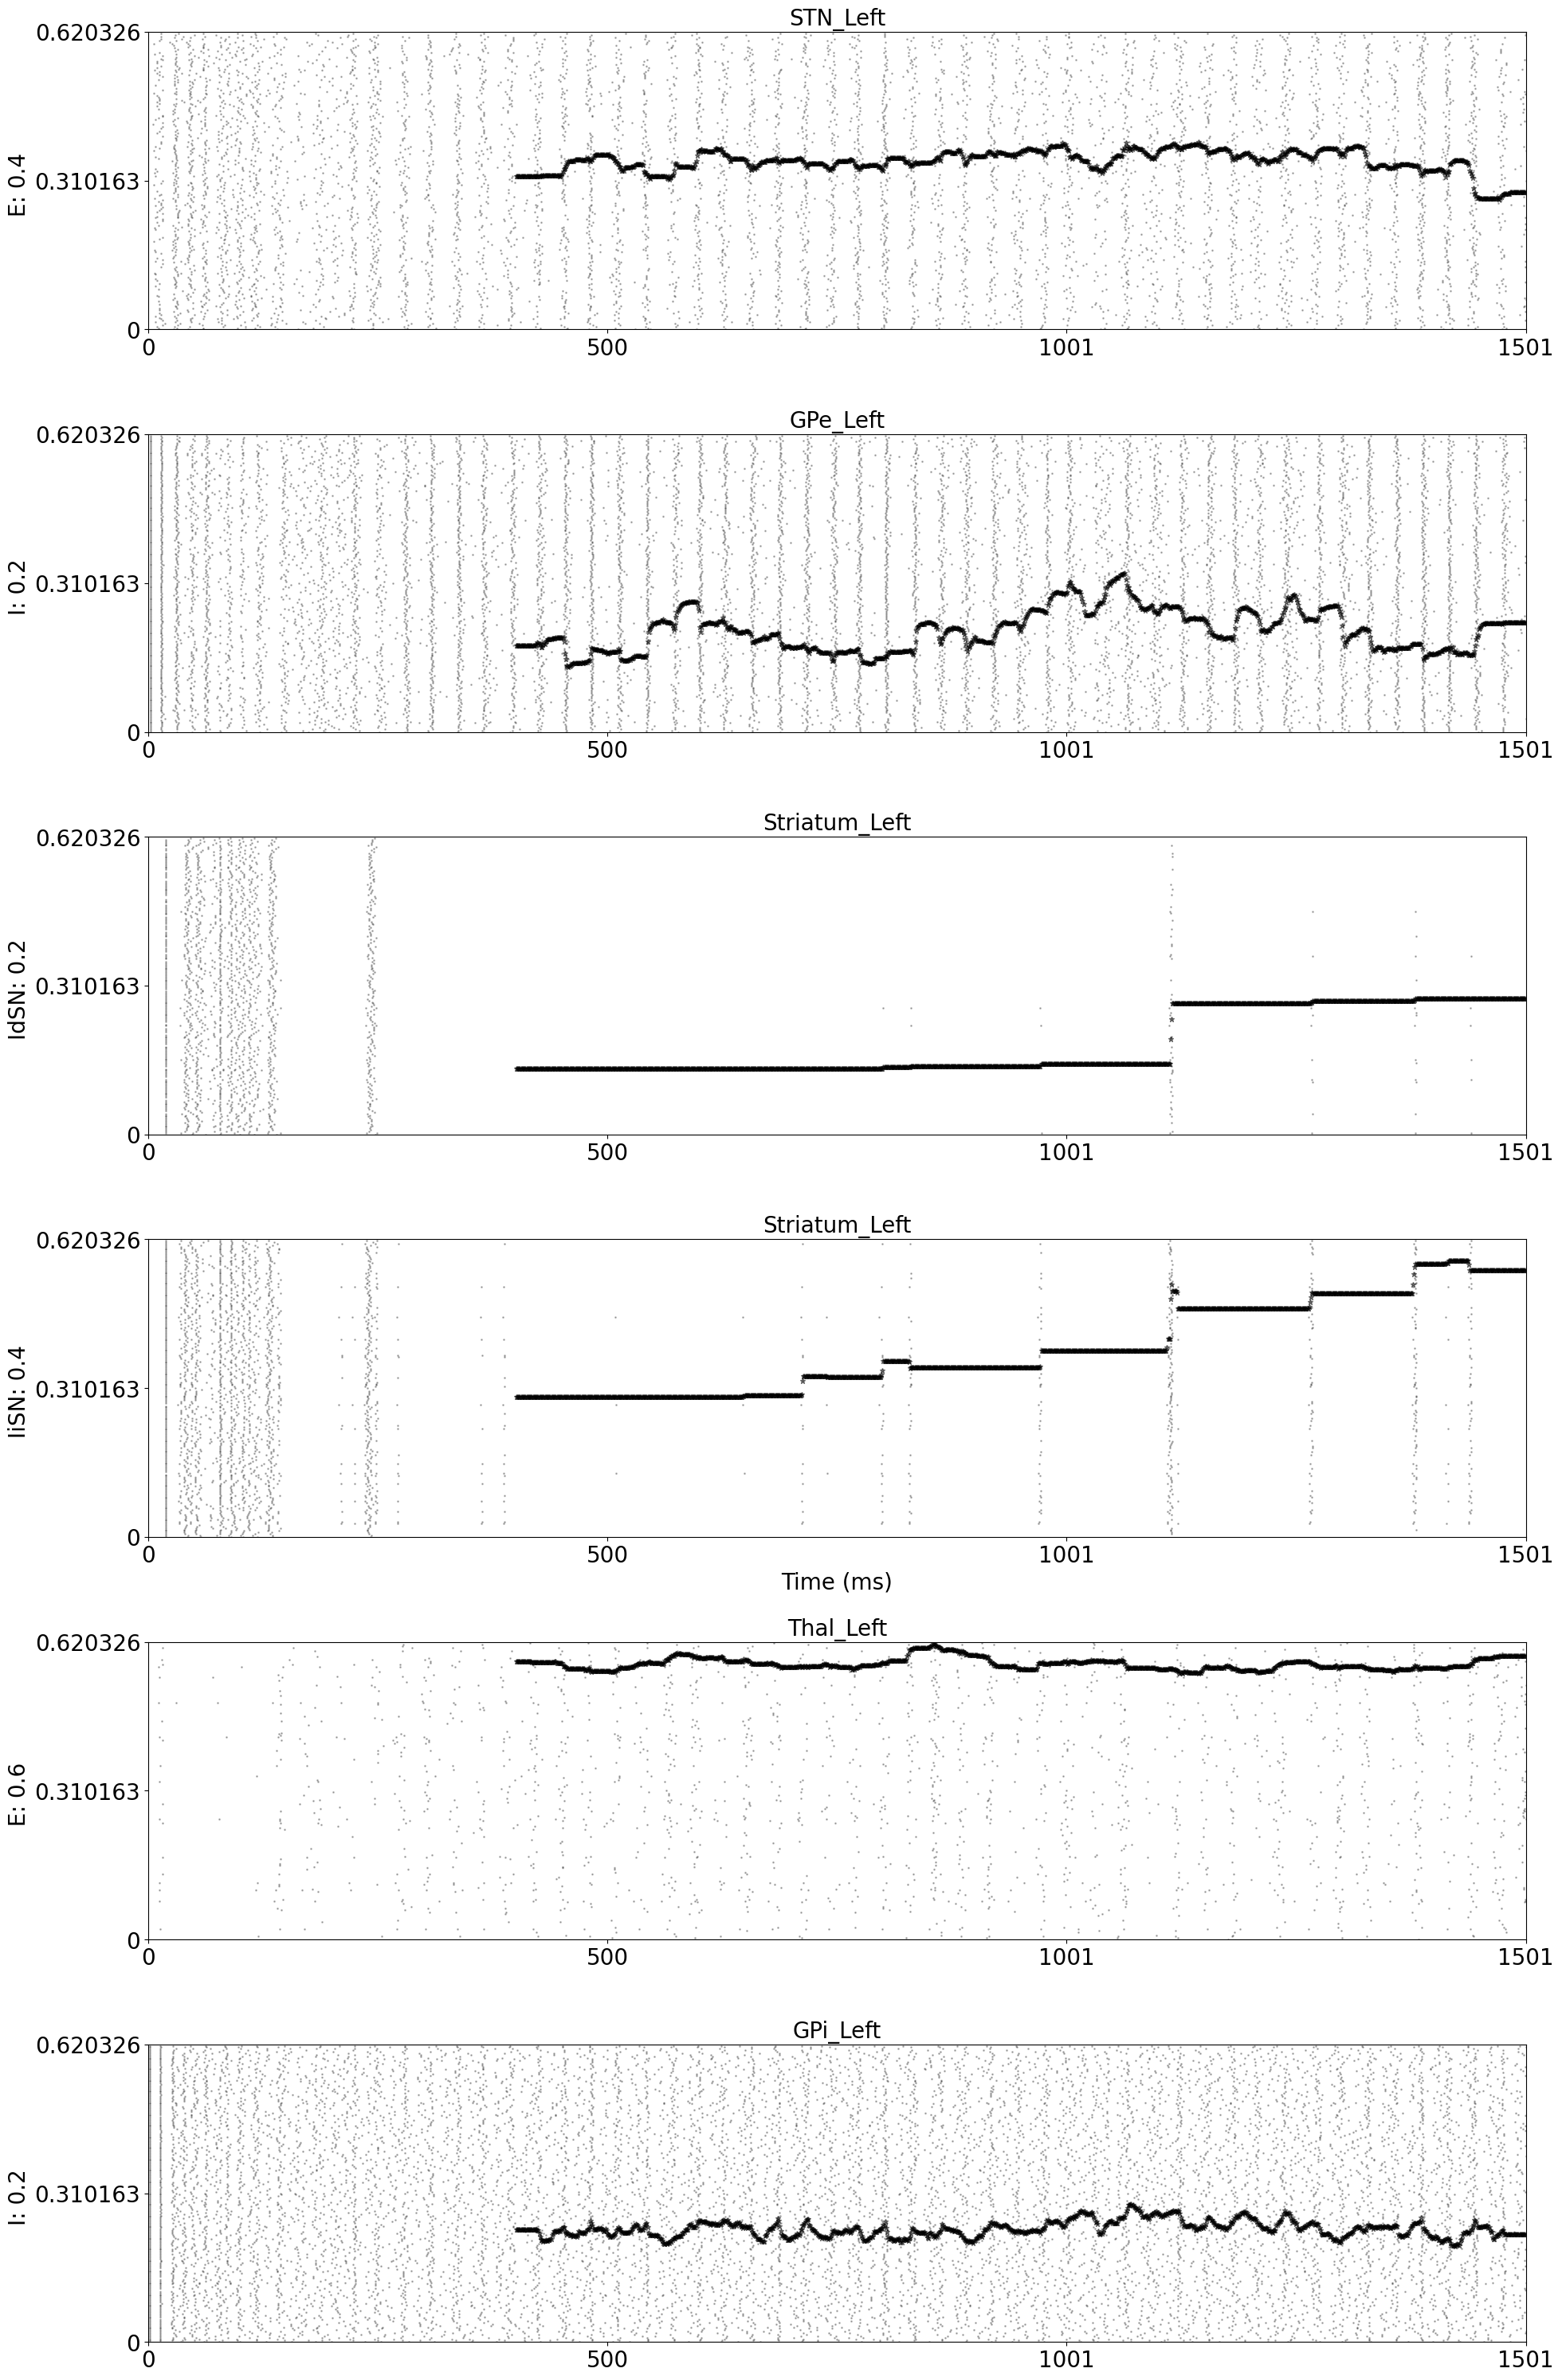

In [42]:
if spikes_sync:
    plotter.config.FONTSIZE = 20 # plotter.config.LARGE_FONTSIZE  # LARGE = 12, default = 10
    plotter.plot_spike_events(spikes_res["spikes"], 
                              time_series=spikes_sync["spikes_isi_distance_time_series"], 
                              mean_results=spikes_sync["spikes_isi_distance"], 
                              stimulus=[start_stimulus] if simulation_mode != "rs" else None,
                              plot_spikes=True, spikes_alpha=0.25,
                              spikes_markersize=1.0, stimulus_linewidth=5.0, time_series_marker="*", 
                              figsize=(20, 40), n_y_ticks=3, n_time_ticks=4, show_time_axis=True,
                              time_axis_min=0.0, time_axis_max=simulation_length
                                     )

In [43]:
if spikes_sync:
    print("Spike synchronization:")
    for pop in spikes_sync["spikes_sync"].coords["Population"]:
        for reg in spikes_sync["spikes_sync"].coords["Region"]:
            if not np.isnan(spikes_sync["spikes_sync"].loc[pop, reg]):
                print("%s - %s: %g" % (pop.values.item().split("_spikes")[0], reg.values.item(), 
                                       spikes_sync["spikes_sync"].loc[pop, reg].values.item()))

    savemat(os.path.join(config.out.FOLDER_RES, "spikes_sync.mat"), spikes_sync["spikes_sync"].to_dict())
    savemat(os.path.join(config.out.FOLDER_RES, "spikes_sync_time_series.mat"), spikes_sync["spikes_sync_time_series"].to_dict())

Spike synchronization:
E - STN_Left: 0.604222
E - Thal_Left: 0.38595
I - GPe_Left: 0.853071
I - GPi_Left: 0.7383
IdSN - Striatum_Left: 0.157181
IiSN - Striatum_Left: 0.374025


In [44]:
if spikes_sync:
    print("Spike distance:")
    for pop in spikes_sync["spikes_distance"].coords["Population"]:
        for reg in spikes_sync["spikes_distance"].coords["Region"]:
            if not np.isnan(spikes_sync["spikes_distance"].loc[pop, reg]):
                print("%s - %s: %g" % (pop.values.item().split("_spikes")[0], reg.values.item(), 
                                       spikes_sync["spikes_distance"].loc[pop, reg].values.item()))

    savemat(os.path.join(config.out.FOLDER_RES, "spikes_distance.mat"), spikes_sync["spikes_distance"].to_dict())
    savemat(os.path.join(config.out.FOLDER_RES, "spikes_distance_time_series.mat"), spikes_sync["spikes_distance_time_series"].to_dict())

Spike distance:
E - STN_Left: 0.24194
E - Thal_Left: 0.307425
I - GPe_Left: 0.153345
I - GPi_Left: 0.241183
IdSN - Striatum_Left: 0.116358
IiSN - Striatum_Left: 0.216505


In [45]:
if spikes_sync:
    print("Spike ISI distance:")
    for pop in spikes_sync["spikes_isi_distance"].coords["Population"]:
        for reg in spikes_sync["spikes_isi_distance"].coords["Region"]:
            if not np.isnan(spikes_sync["spikes_isi_distance"].loc[pop, reg]):
                print("%s - %s: %g" % (pop.values.item().split("_spikes")[0], reg.values.item(), 
                                       spikes_sync["spikes_isi_distance"].loc[pop, reg].values.item()))

    savemat(os.path.join(config.out.FOLDER_RES, "spikes_isi_distance.mat"), spikes_sync["spikes_isi_distance"].to_dict())
    savemat(os.path.join(config.out.FOLDER_RES, "spikes_isi_distance_time_series.mat"), spikes_sync["spikes_isi_distance_time_series"].to_dict())

Spike ISI distance:
E - STN_Left: 0.352301
E - Thal_Left: 0.577815
I - GPe_Left: 0.212397
I - GPi_Left: 0.237548
IdSN - Striatum_Left: 0.190051
IiSN - Striatum_Left: 0.398262


In [46]:
if spikes_res and writer:
    writer.write_object(spikes_res["spikes"].to_dict(), 
                        path=os.path.join(config.out.FOLDER_RES,  "Spikes") + ".h5");
    writer.write_object(spikes_res["mean_rate"].to_dict(),
                        path=os.path.join(config.out.FOLDER_RES,
                                          spikes_res["mean_rate"].name) + ".h5");
    write_RegionTimeSeriesXarray_to_h5(spikes_res["mean_rate_time_series"], writer,
                                       os.path.join(config.out.FOLDER_RES,
                                                    spikes_res["mean_rate_time_series"].title) + ".h5",
                                       recursive=False);
    writer.write_object(spikes_res["spikes_correlation_coefficient"].to_dict(),
                        path=os.path.join(config.out.FOLDER_RES,
                                          spikes_res["spikes_correlation_coefficient"].name) + ".h5");

2026-03-31 09:39:18,208 - WARNING - tvb_multiscale.core.tvb.io.h5_writer - Failed to decompose group object: {'E': STN_Left     times      [5.49, 5.72, 5.995, 5.995, 6.34, 6....
Thal_Left    times      [11.18, 11.18, 12.35, 12.35, 12.35,...
Name: E, dtype: object, 'I': GPe_Left    times      [2.305, 2.305, 2.305, 2.305, 2.305,...
GPi_Left    times      [1.35, 1.35, 1.35, 1.35, 1.35, 1.35...
Name: I, dtype: object, 'IdSN': Striatum_Left    times      [18.845, 18.85, 18.85, 18.85, 18.86...
Name: IdSN, dtype: object, 'IiSN': Striatum_Left    times      [18.865000000000002, 18.87, 18.88, ...
Name: IiSN, dtype: object}!
The error was
module 'numpy' has no attribute 'complex'.
`np.complex` was a deprecated alias for the builtin `complex`. To avoid this error in existing code, use `complex` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.complex128` here.
The aliases was originally deprecated in NumPy 1.20; for more det

### Get  SpikingNetwork mean field variable time series and plot them

2026-03-31 09:39:18,250 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model  for  created!
2026-03-31 09:39:18,250 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model  for  created!
2026-03-31 09:39:18,254 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model  for  created!
2026-03-31 09:39:18,254 - INFO - tvb_multiscale.core.spiking_models.devices - <class 'tvb_multiscale.core.spiking_models.devices.DeviceSet'> of model  for  created!
2026-03-31 09:39:19,894 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:19,894 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!
2026-03-31 09:39:19,899 - WARNING - tvb.contrib.scripts.datatypes.ti

/home/docker/packages/tvb-root/tvb_contrib/tvb/contrib/scripts/utils/data_structures_utils.py:894: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'Region' ('Region',) The recommendation is to set join explicitly for this case.
  data = concat(data, Index(data_keys, name=concat_dim_name), fill_value=fill_value)


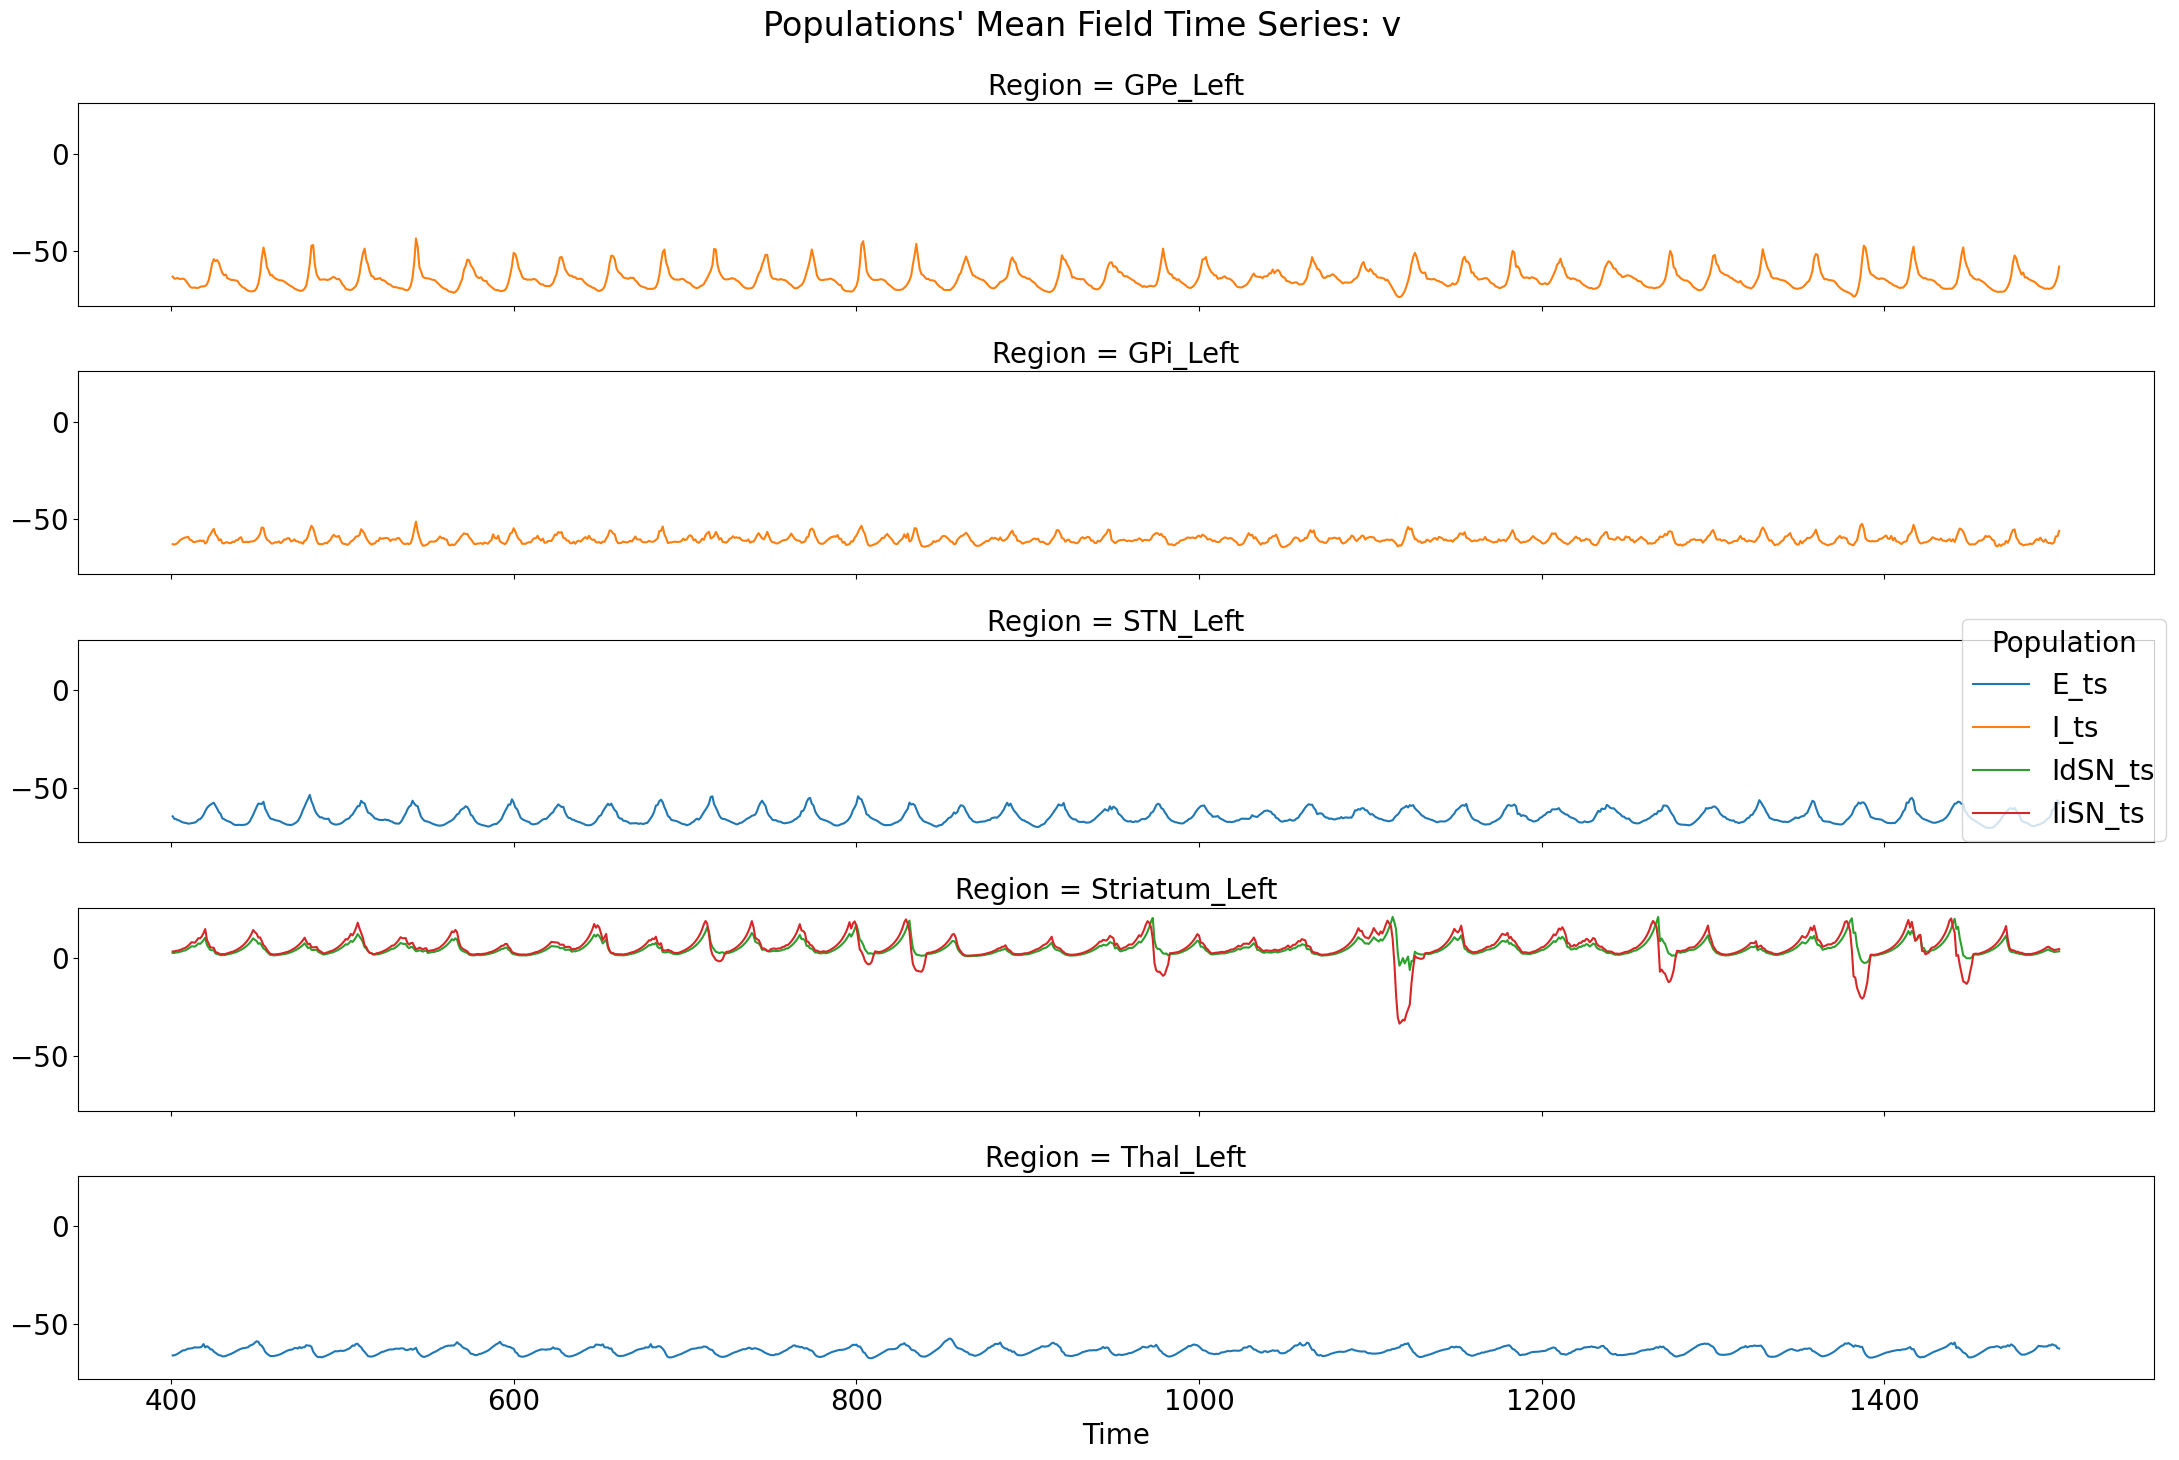

2026-03-31 09:39:20,538 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:20,538 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


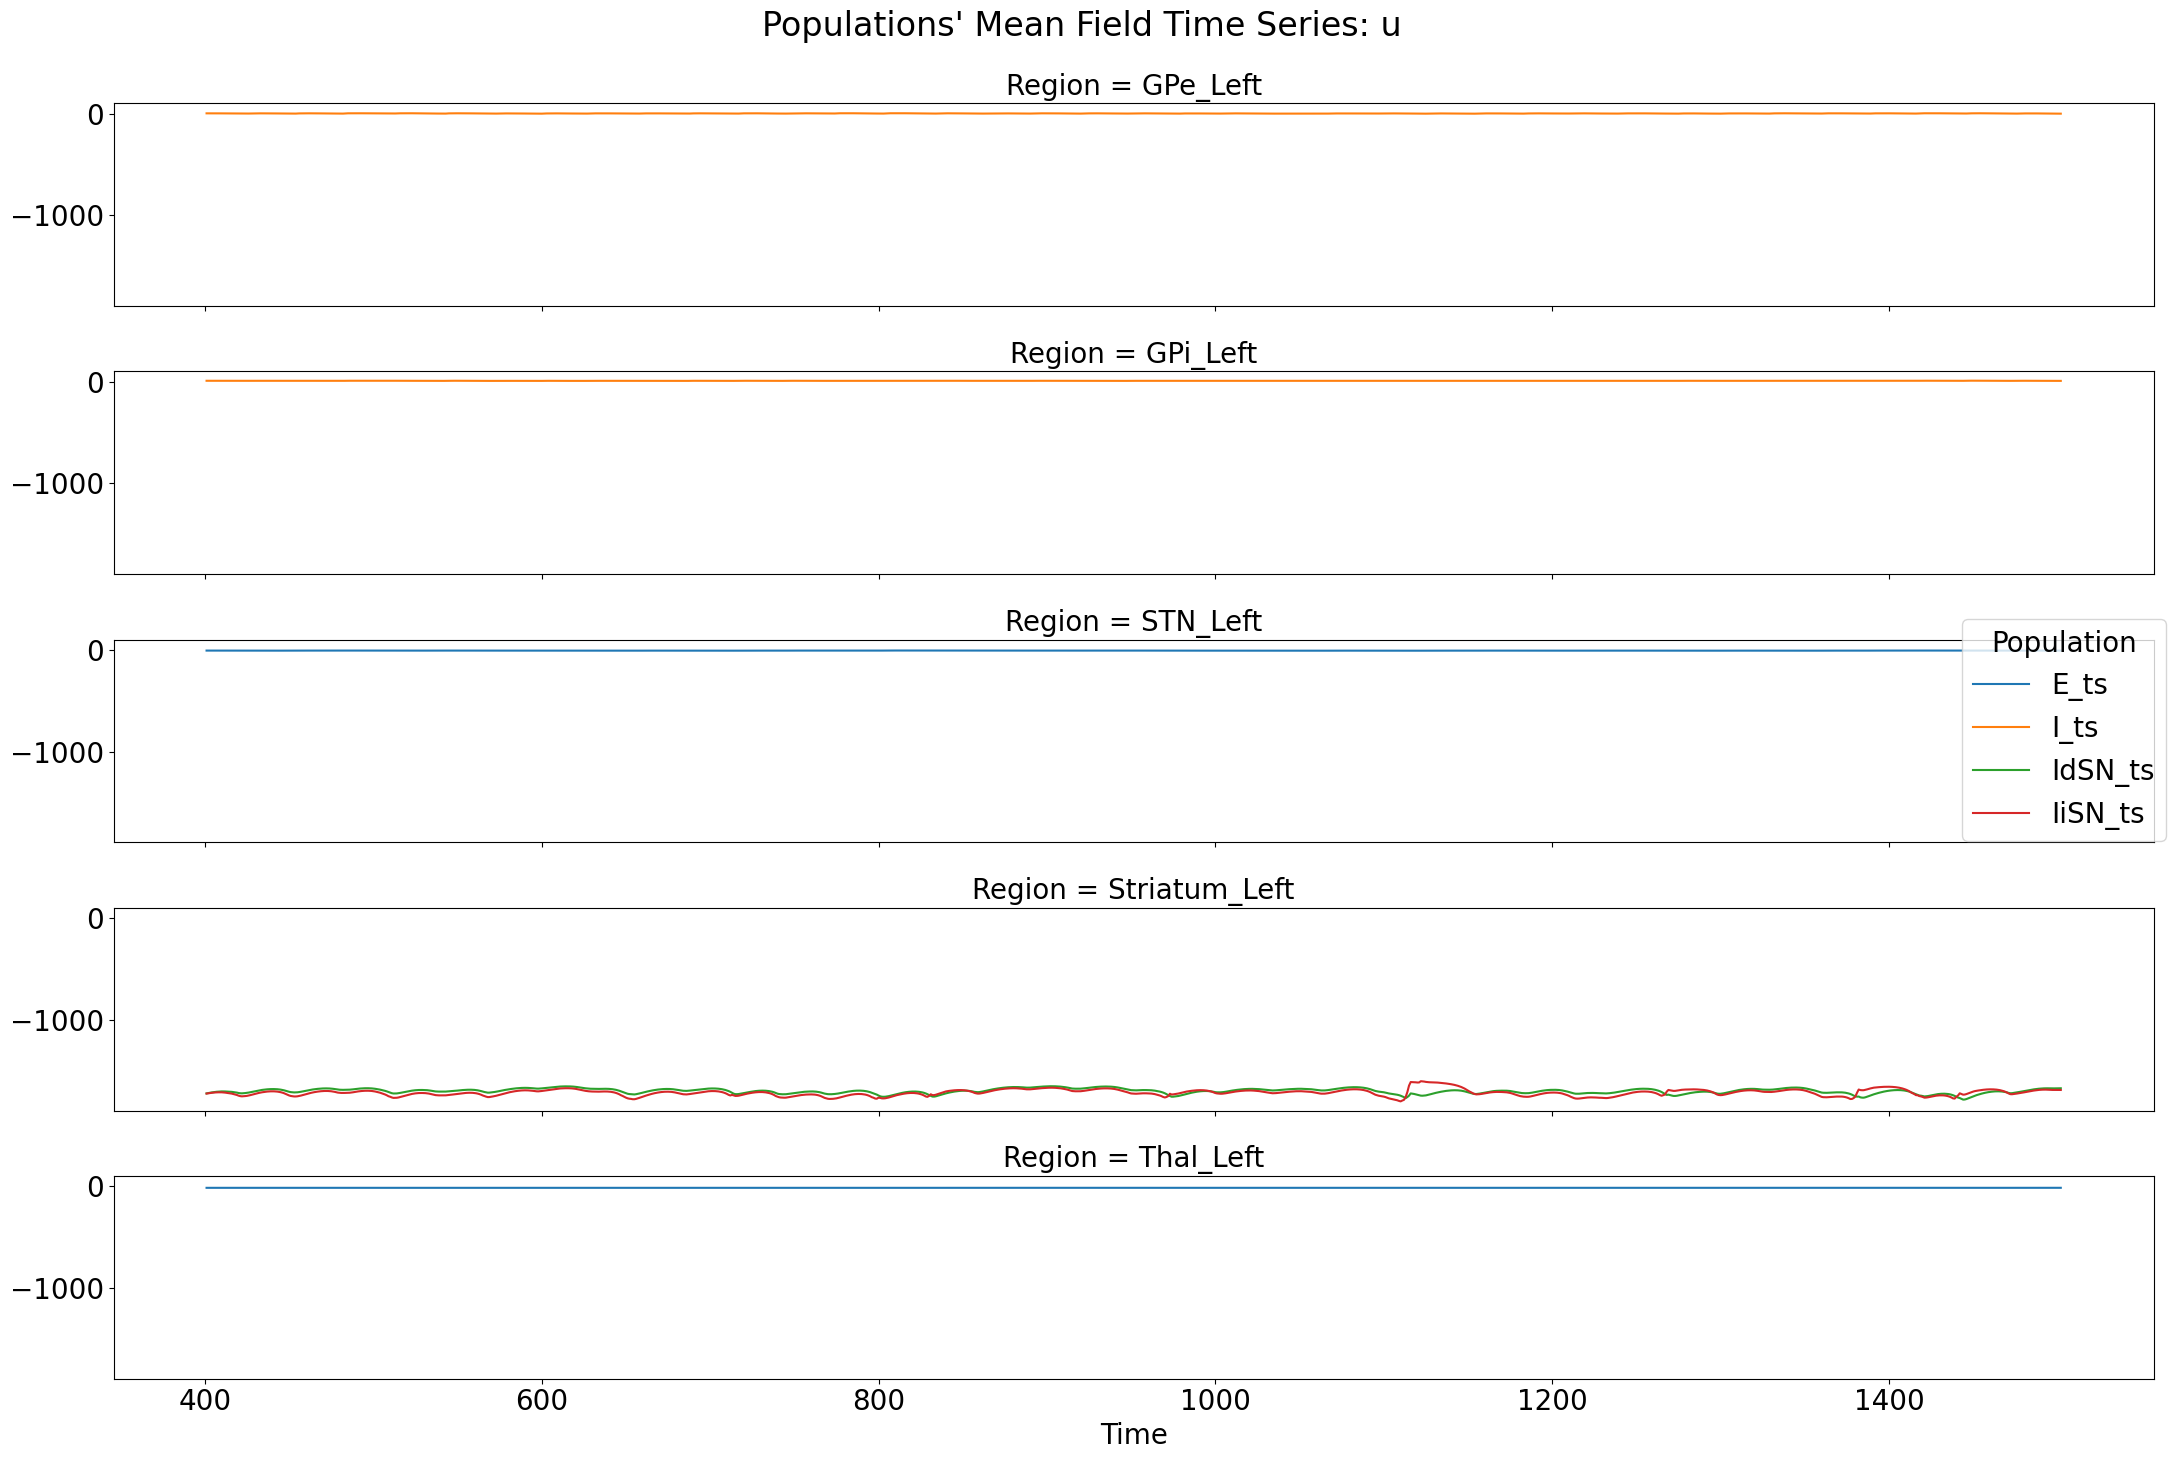

2026-03-31 09:39:21,124 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:21,125 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


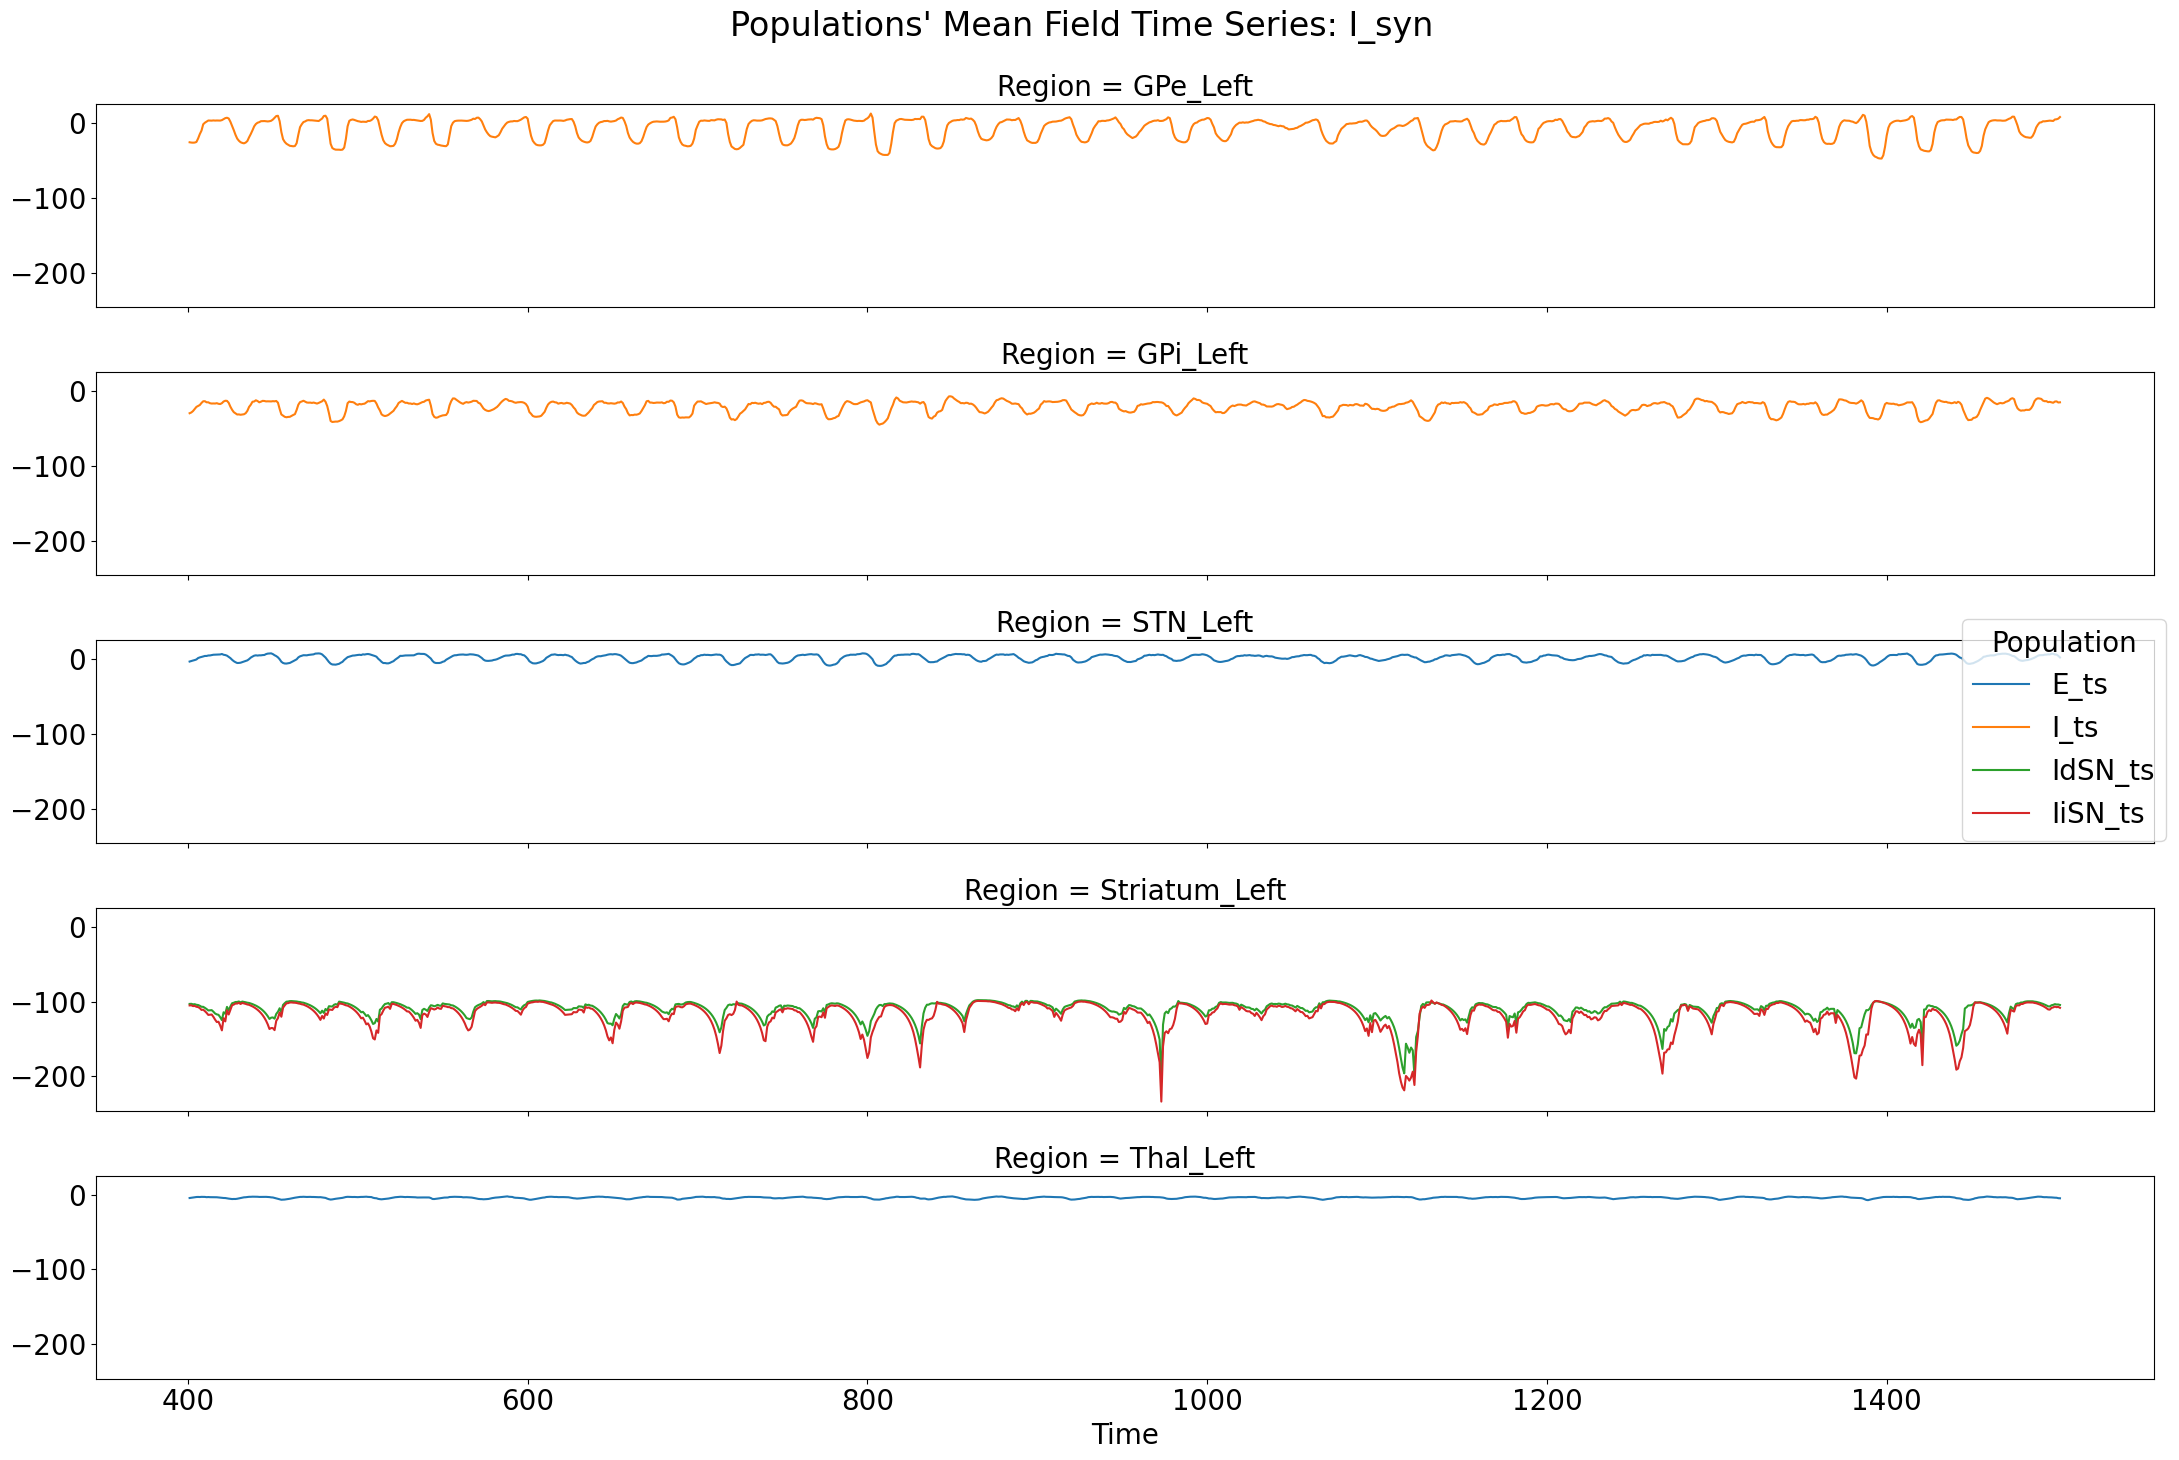

2026-03-31 09:39:21,802 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:21,802 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


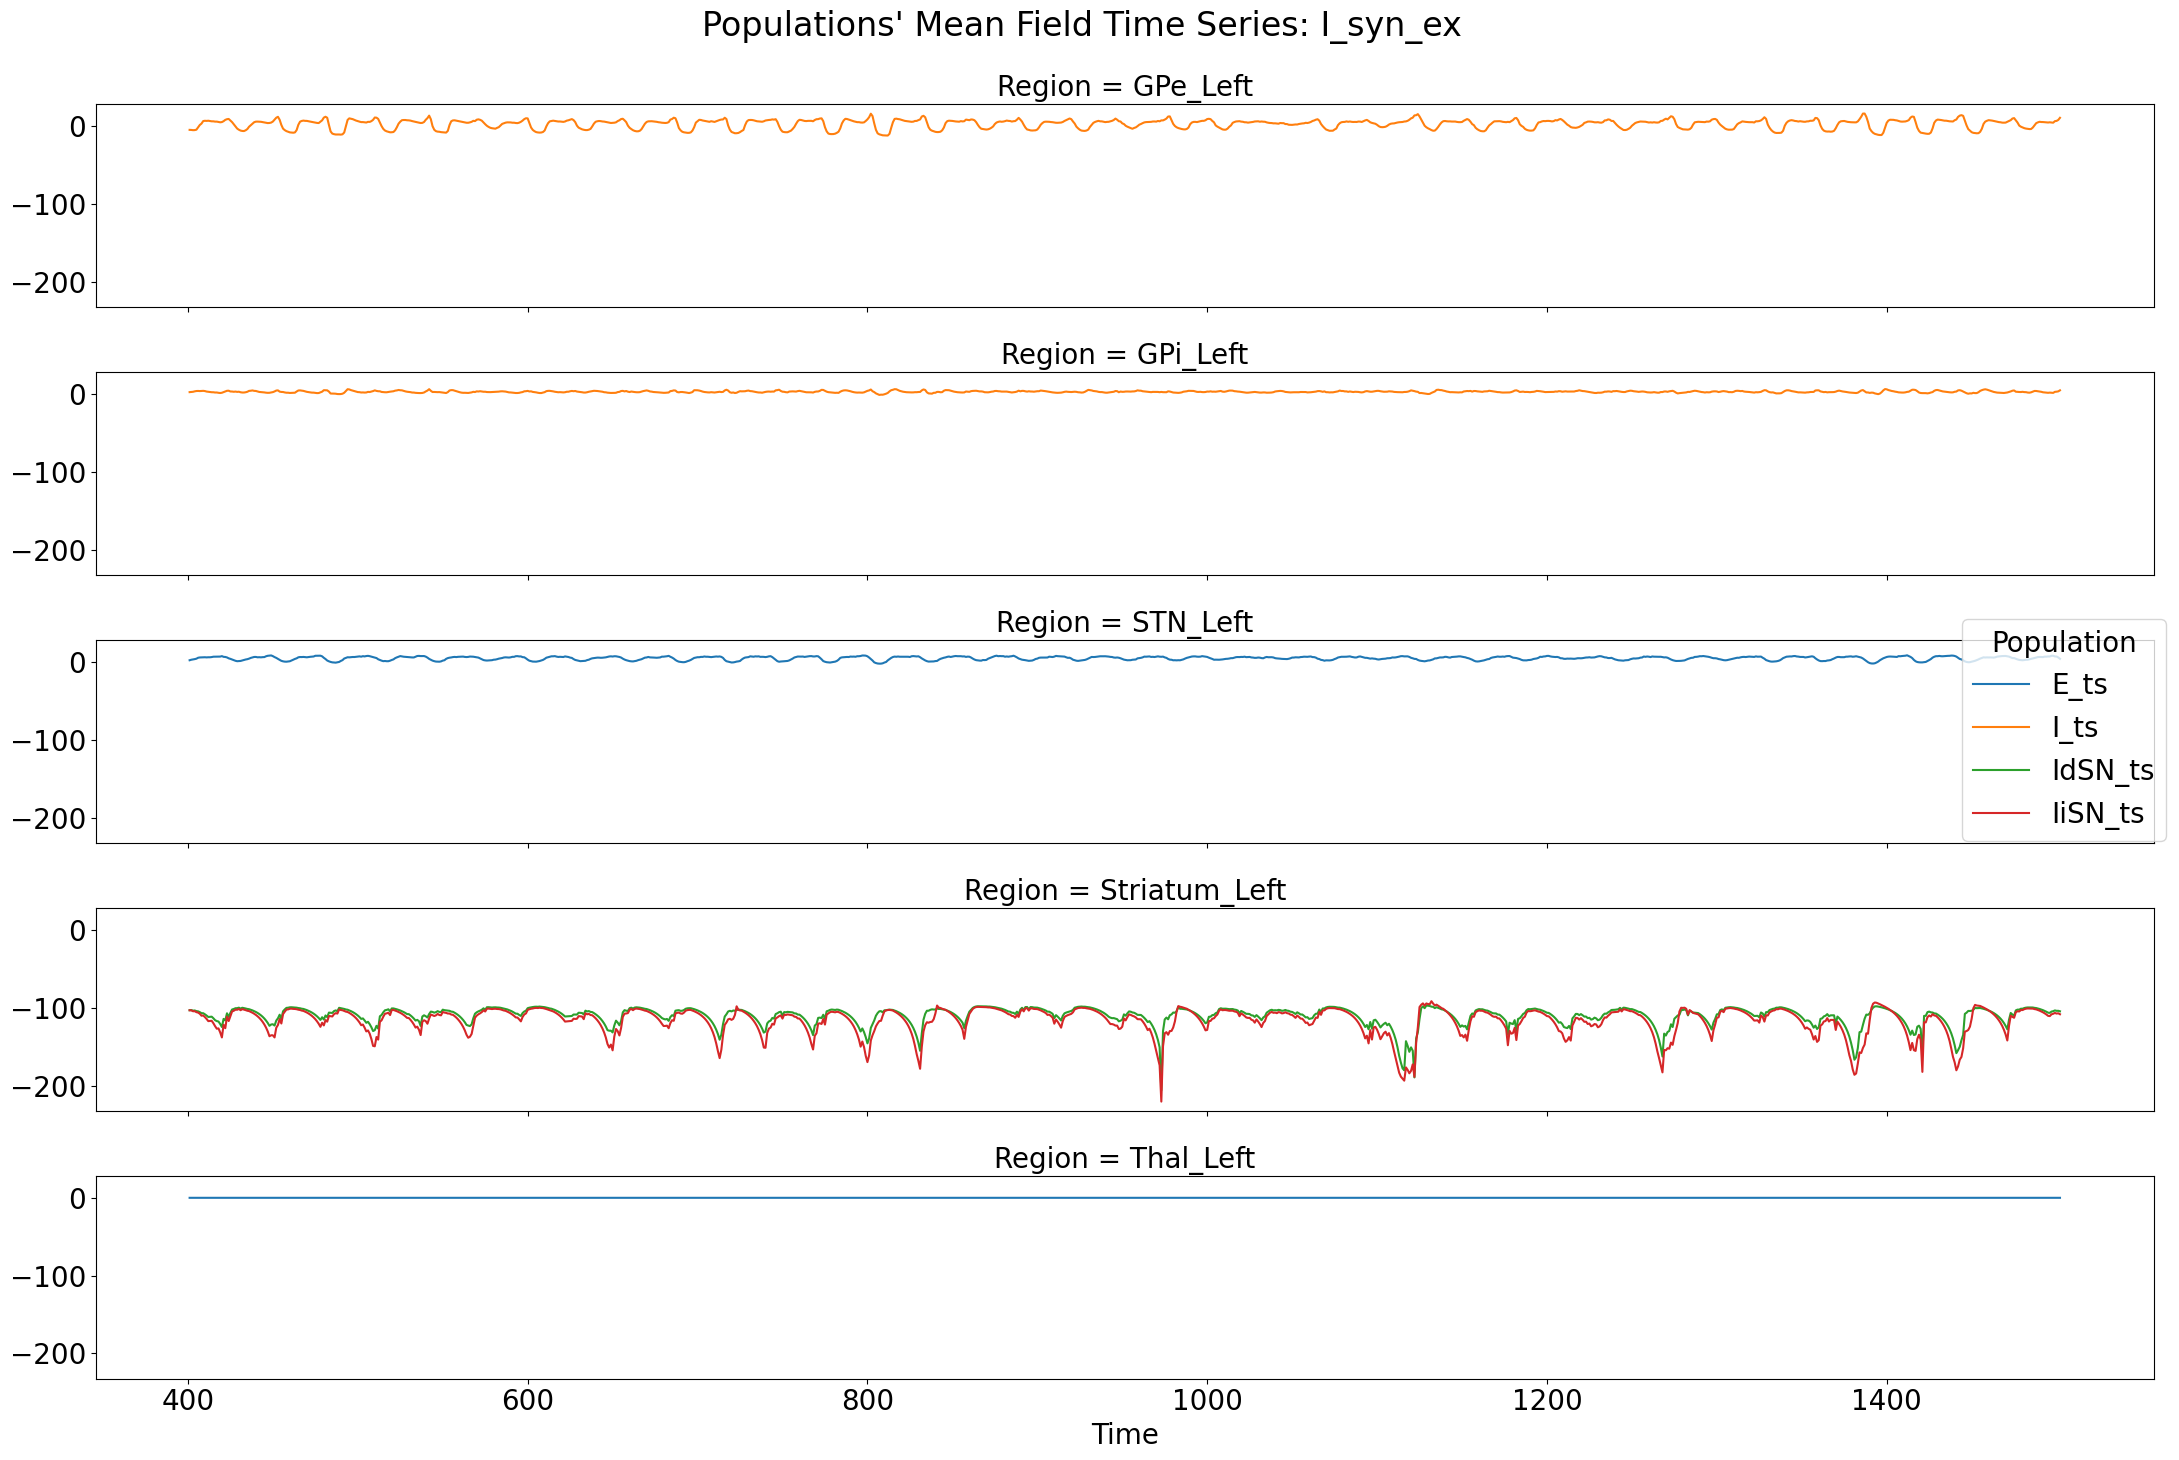

2026-03-31 09:39:22,471 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:22,472 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


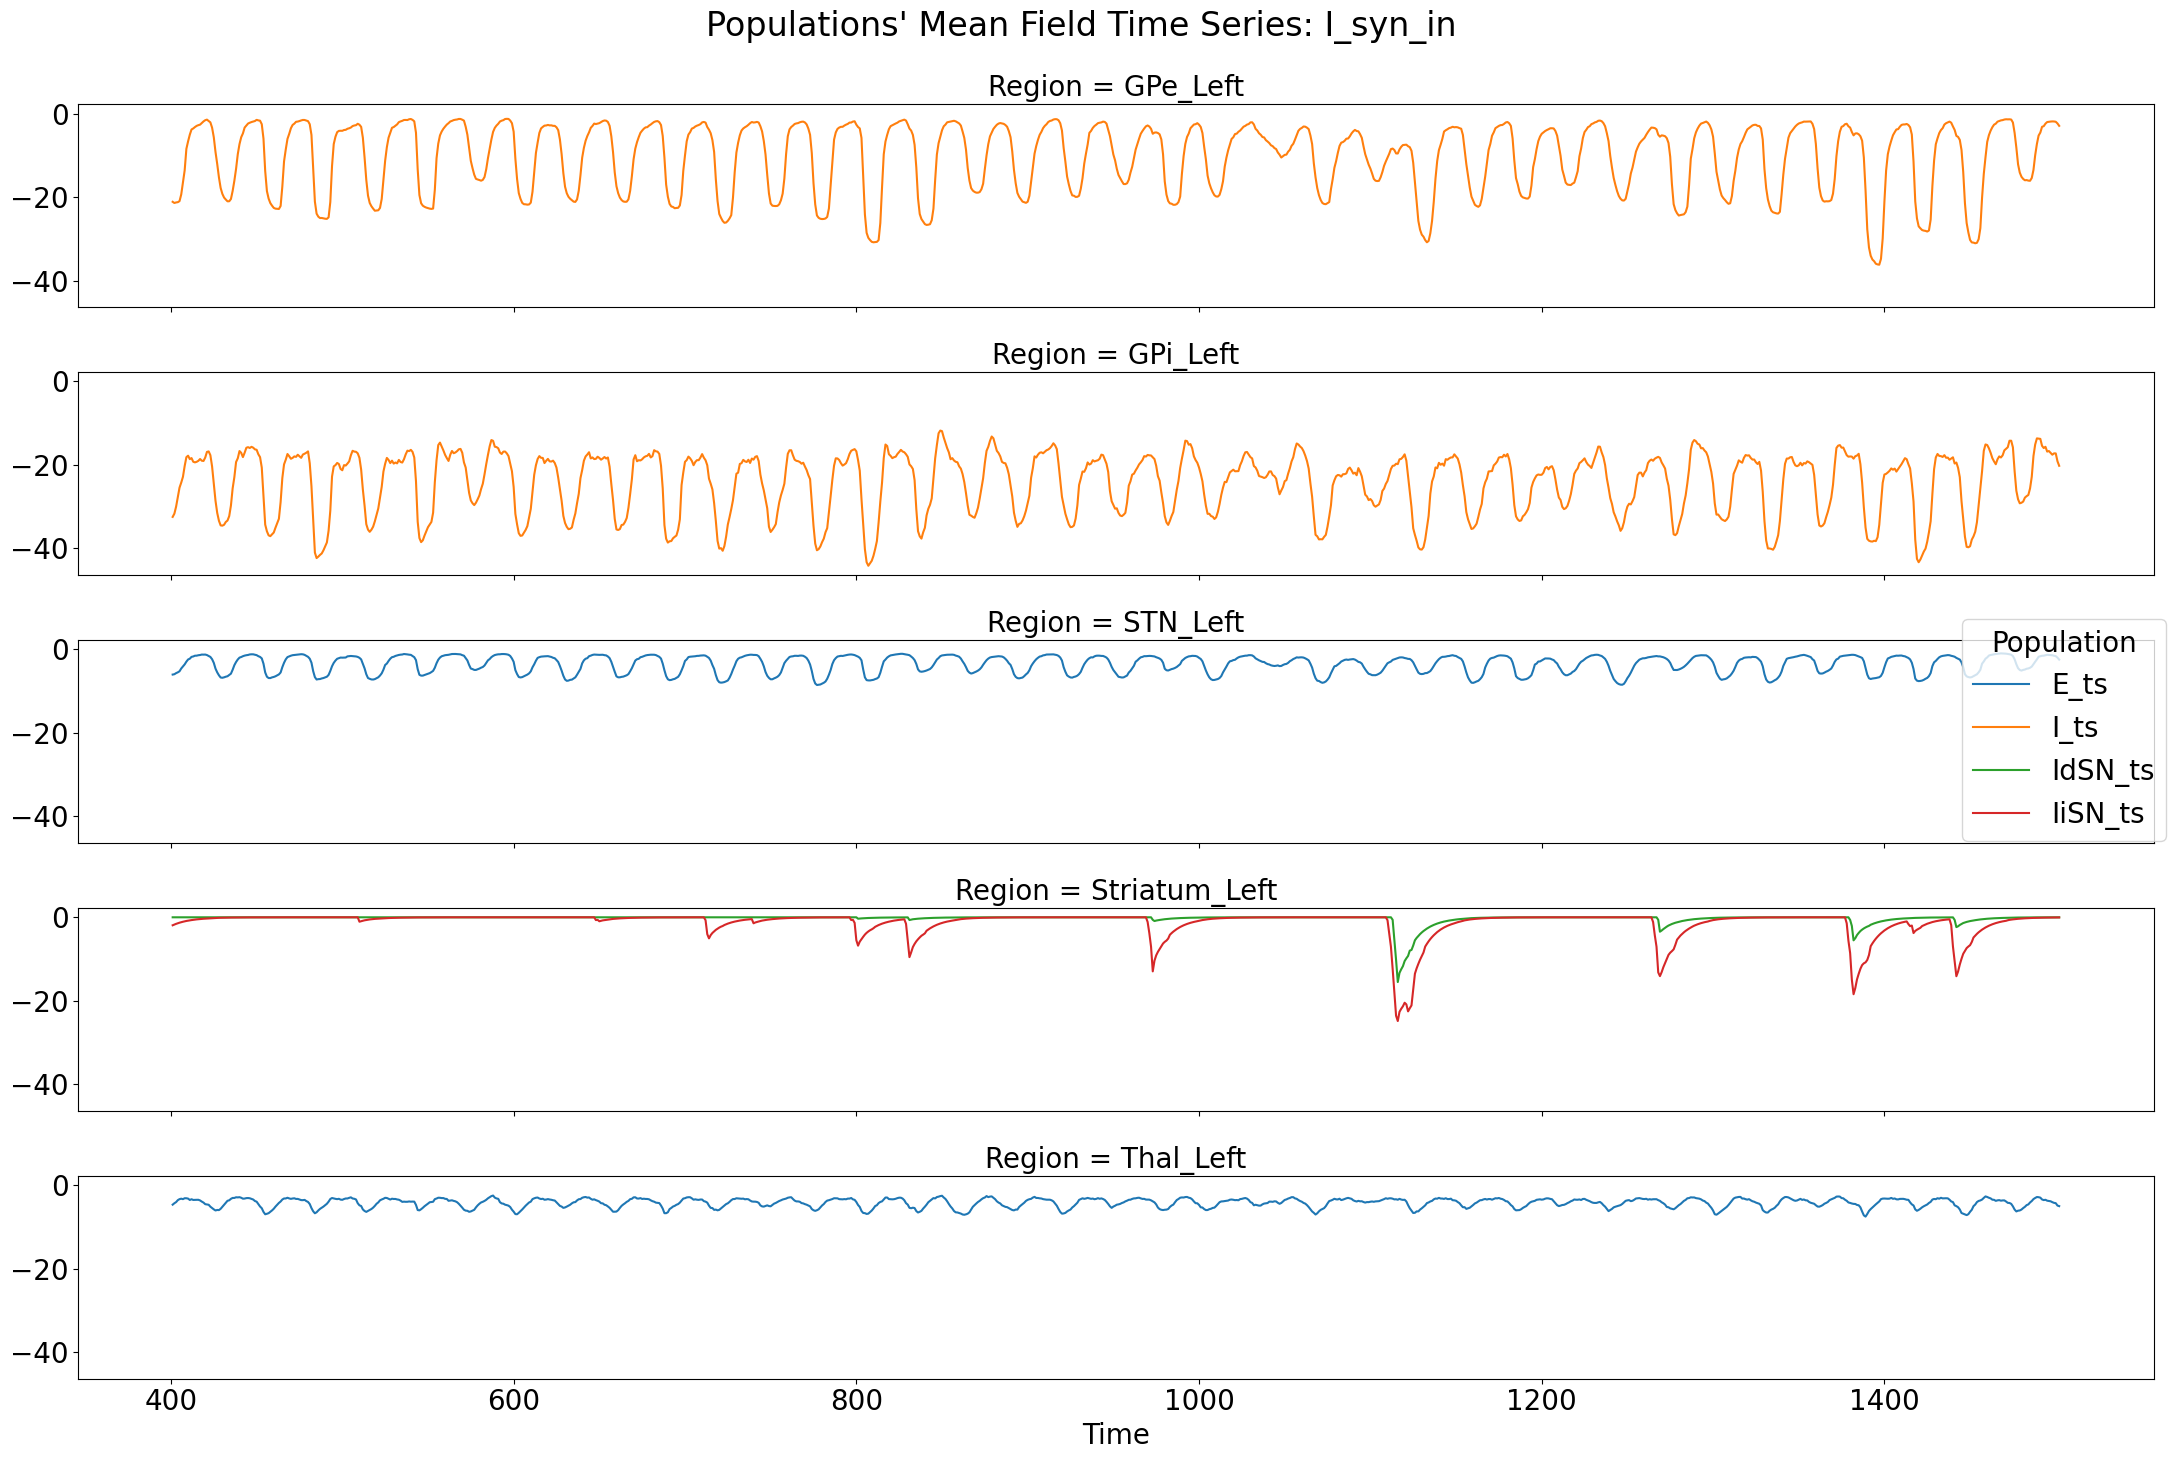

2026-03-31 09:39:23,131 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:23,132 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


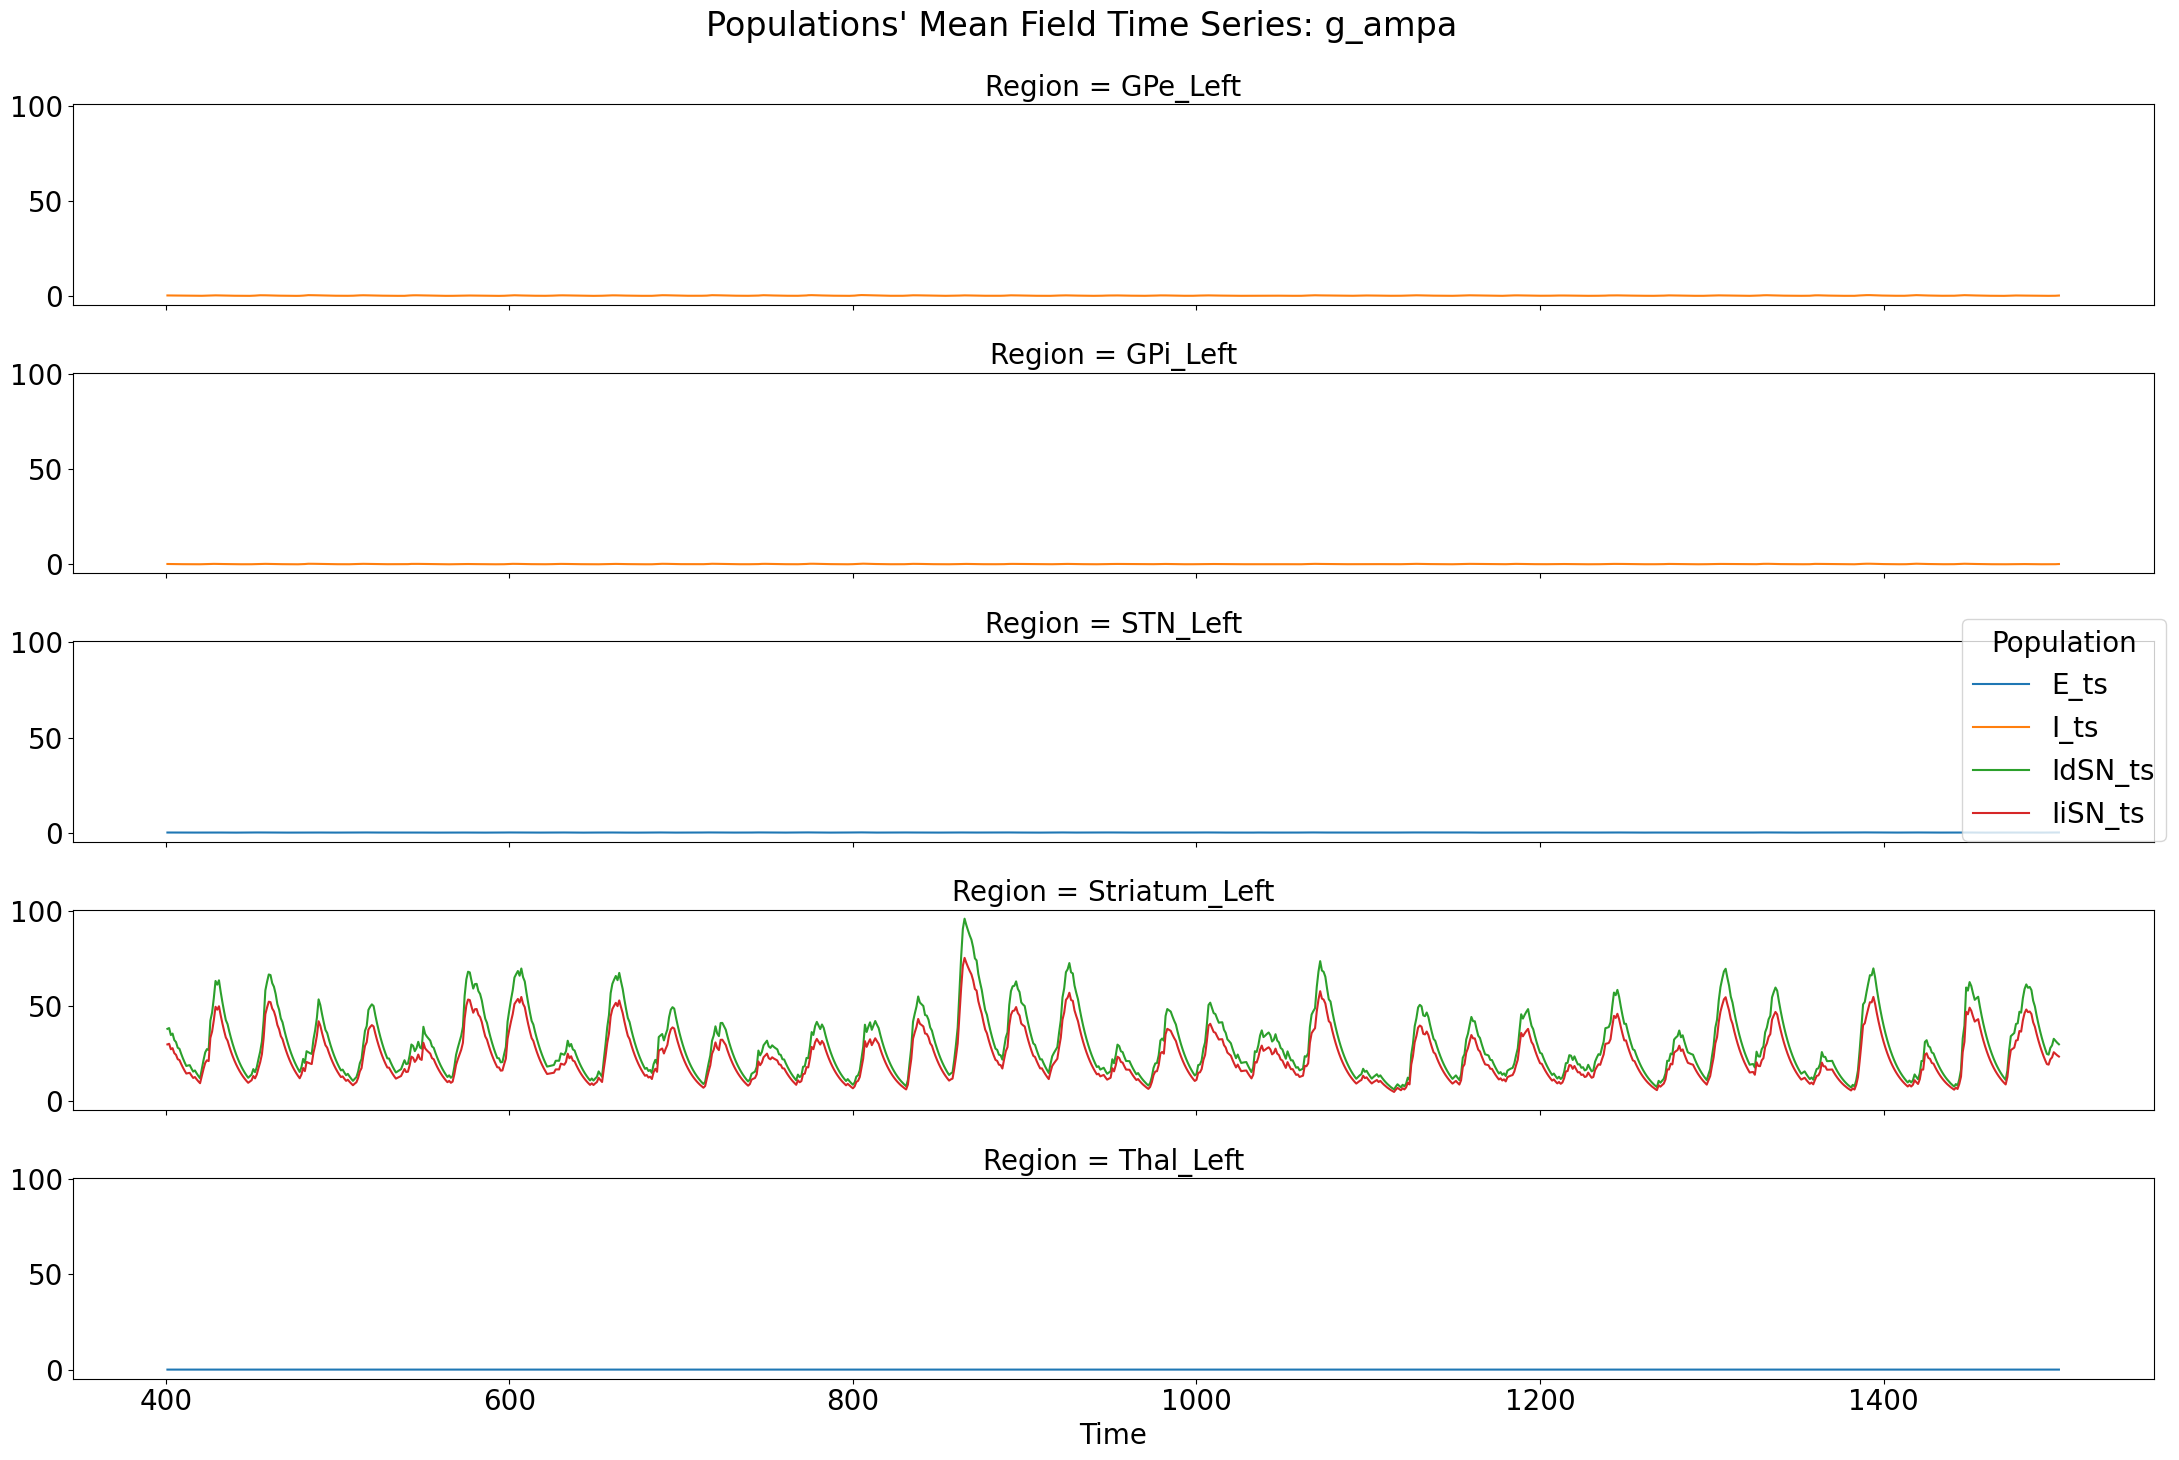

2026-03-31 09:39:23,782 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:23,782 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


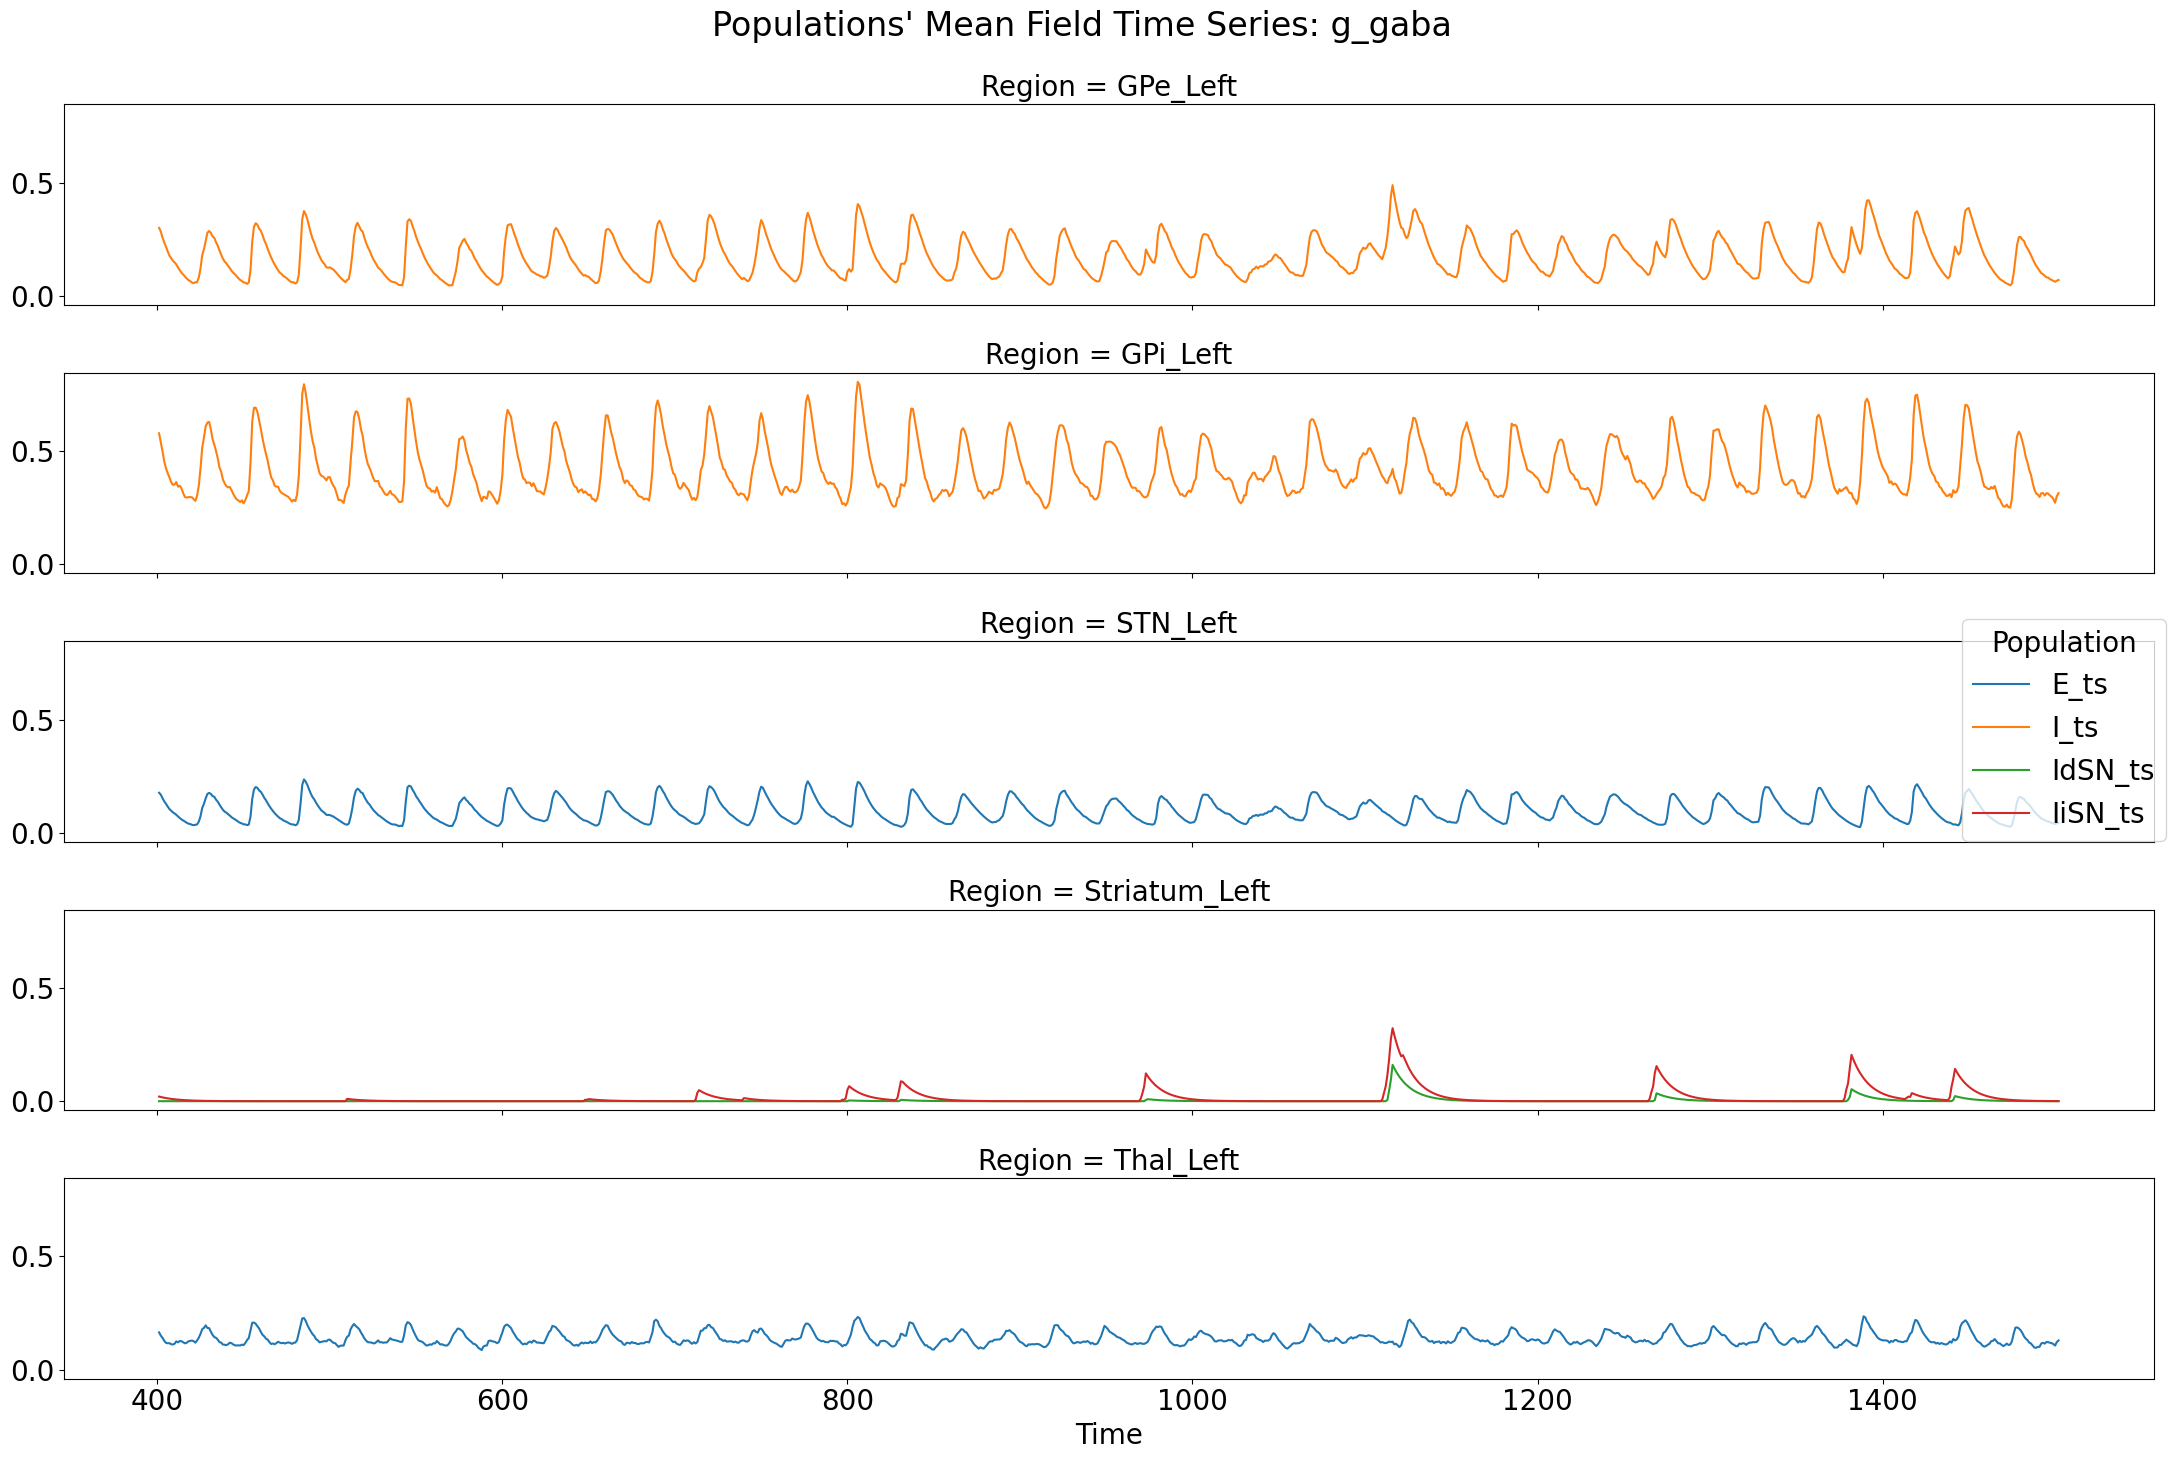

2026-03-31 09:39:24,667 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - 'NoneType' object is not subscriptable
2026-03-31 09:39:24,667 - WARNING - tvb.contrib.scripts.datatypes.time_series_xarray - Connectivity and RegionTimeSeries labels agreement failed!


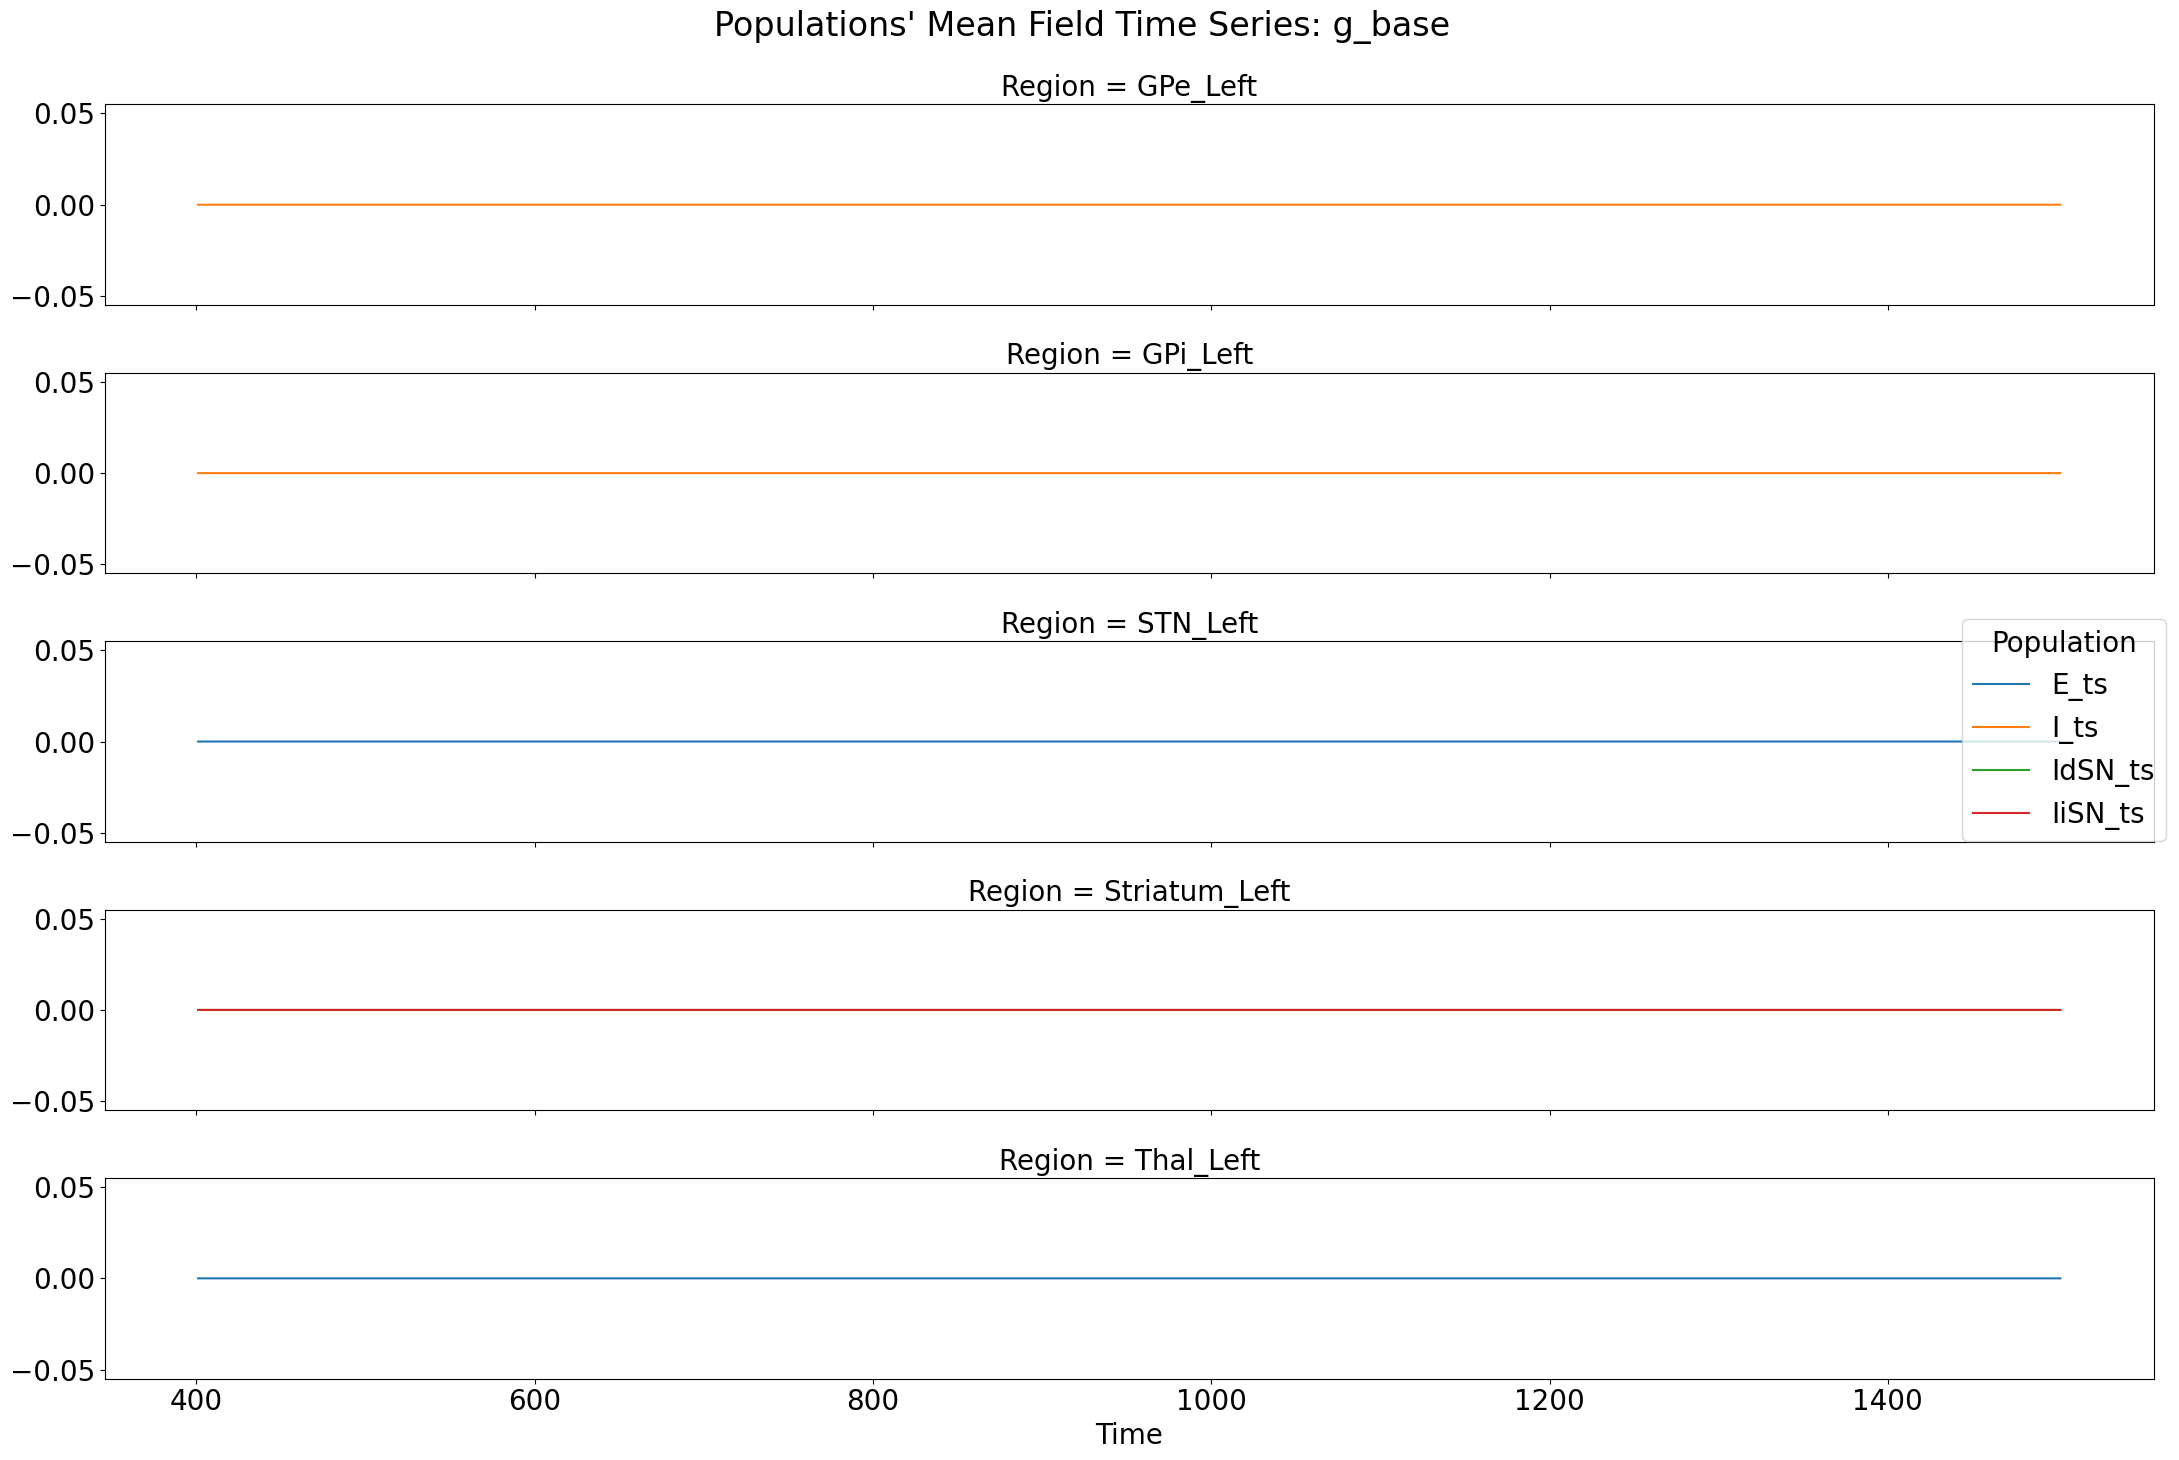

In [47]:
# Continuous time variables' data of spiking neurons
if plot_per_neuron:
    spikeNet_analyzer.return_data = True
else:
    spikeNet_analyzer.return_data = False
spikeNet_ts = \
    spikeNet_analyzer. \
         compute_spikeNet_mean_field_time_series(populations_devices=None, regions=None, variables=None,
                                                 computations_kwargs={}, data_kwargs={}, return_devices=False)
if spikeNet_ts:
    if plot_per_neuron:
        mean_field_ts = spikeNet_ts["mean_field_time_series"]  # mean field
        spikeNet_ts = spikeNet_ts["data_by_neuron"]  # per neuron data
    else:
        mean_field_ts = spikeNet_ts
    if mean_field_ts and mean_field_ts.size > 0:
        mean_field_ts.plot_timeseries(plotter_config=plotter.config, 
                                      per_variable=mean_field_ts.shape[1] > MAX_VARS_IN_COLS)
        if mean_field_ts.number_of_labels > MIN_REGIONS_FOR_RASTER_PLOT:
            mean_field_ts.plot_raster(plotter_config=plotter.config, 
                                      per_variable=mean_field_ts.shape[1] > MAX_VARS_IN_COLS,
                                      linestyle="--", alpha=0.5, linewidth=0.5)
else:
    mean_field_ts = None

datadict = mean_field_ts._data.to_dict()   
datadict["transient"] = transient
savemat(os.path.join(config.out.FOLDER_RES, "ANNarchy_timeseries.mat"), datadict)
del datadict

In [48]:
# Write results to file:
if mean_field_ts and writer:
    write_RegionTimeSeriesXarray_to_h5(mean_field_ts, writer,
                                       os.path.join(config.out.FOLDER_RES, mean_field_ts.title) + ".h5", 
                                       recursive=False)

### Compute per neuron spikes' rates times series and plot them

In [49]:
if spikes_res and plot_per_neuron:
    from tvb.simulator.plot.base_plotter import pyplot
    spikeNet_analyzer.return_data = False
    rates_ts_per_neuron = \
        spikeNet_analyzer. \
            compute_spikeNet_rates_time_series(populations_devices=None, regions=None,
                                               computations_kwargs={}, data_kwargs={},
                                               return_spikes_trains=False, return_devices=False);
    if rates_ts_per_neuron is not None and rates_ts_per_neuron.size:
        # Regions in rows
        row = rates_ts_per_neuron.dims[2] if rates_ts_per_neuron.shape[2] > 1 else None
        if row is None:
            # Populations in rows
            row = rates_ts_per_neuron.dims[1] if rates_ts_per_neuron.shape[1] > 1 else None
            col = None
        else:
            # Populations in columns
            col = rates_ts_per_neuron.dims[1] if rates_ts_per_neuron.shape[1] > 1 else None
        pyplot.figure()
        rates_ts_per_neuron.plot(y=rates_ts_per_neuron.dims[3], row=row, col=col, cmap="jet")
        plotter.base._save_figure(figure_name="Spike rates per neuron")
        # del rates_ts_per_neuron # to free memory

### Plot per neuron SpikingNetwork time series

In [50]:
# Regions in rows
if plot_per_neuron and spikeNet_ts.size:
    row = spikeNet_ts.dims[2] if spikeNet_ts.shape[2] > 1 else None
    if row is None:
        # Populations in rows
        row = spikeNet_ts.dims[3] if spikeNet_ts.shape[3] > 1 else None
        col = None
    else:
        # Populations in cols
         col = spikeNet_ts.dims[3] if spikeNet_ts.shape[3] > 1 else None
    for var in spikeNet_ts.coords[spikeNet_ts.dims[1]]:
        this_var_ts = spikeNet_ts.loc[:, var, :, :, :]
        this_var_ts.name = var.item()
        pyplot.figure()
        this_var_ts.plot(y=spikeNet_ts.dims[4], row=row, col=col, cmap="jet", figsize=FIGSIZE)
        plotter.base._save_figure(
            figure_name="Spiking Network variables' time series per neuron: %s" % this_var_ts.name)
    del spikeNet_ts # to free memory

# References

1 Sanz Leon P, Knock SA, Woodman MM, Domide L, <br>
  Mersmann J, McIntosh AR, Jirsa VK (2013) <br>
  The Virtual Brain: a simulator of primate brain network dynamics. <br>
  Frontiers in Neuroinformatics 7:10. doi: 10.3389/fninf.2013.00010 <br>
  https://www.thevirtualbrain.org/tvb/zwei <br>
  https://github.com/the-virtual-brain <br>

2 Ritter P, Schirner M, McIntosh AR, Jirsa VK (2013).  <br>
  The Virtual Brain integrates computational modeling  <br>
  and multimodal neuroimaging. Brain Connectivity 3:121–145. <br>

3 Vitay J, Dinkelbach HÜ and Hamker FH (2015). <br>
  ANNarchy: a code generation approach to neural simulations on parallel hardware. <br>
  Frontiers in Neuroinformatics 9:19. doi:10.3389/fninf.2015.00019 <br>
  For more details see https://annarchy.readthedocs.io/en/latest/ <br>

4 Baladron, J., Nambu, A., & Hamker, F. H. (2019). <br>
  The subthalamic nucleus‐external globus pallidus loop biases <br>
  exploratory decisions towards known alternatives: A neuro‐computational study. <br>
  European Journal of Neuroscience, 49:754–767. https://doi.org/10.1111/ejn.13666 <br>
  
5 Maith O, Villagrasa Escudero F, Ülo Dinkelbach H, Baladron J, <br>
  Horn, A, Irmen F, Kühn AA, Hamker FH (2020).<br>
  A computational model‐based analysis of basal ganglia pathway changes <br>
  in Parkinson’s disease inferred from resting‐state fMRI <br>
  European Journal of Neuroscience, 00:1–18. https://doi.org/10.1111/ejn.14868

In [51]:
print("Configured connections:\n")

print("Within node's connections:")
for iP, pop in enumerate(ann_model_builder.populations_connections):
    if hasattr(pop["weight"], "__call__"):
        weight = pop["weight"](pop["nodes"])
    else:
        weight = pop["weight"]
    try:
        p = pop["conn_spec"]["probability"]
    except:
        p = 1.0
    w_conn = assert_loadedParams[np.abs(weight)]
    conn = w_conn.split("_weights")[0]
    p_conn = loadedParams["%s_probs" % conn]
    w_conn = loadedParams[w_conn]
    print("%d. %s -> %s (%s) = %g (p=%g): %s (%g, %g)" 
          % (iP+1, pop["source"], pop["target"], pop["receptor_type"], weight, p,
             conn, w_conn, p_conn))
    
print("\nAmong node's connections:")
for iP, pop in enumerate(ann_model_builder.nodes_connections):
    if hasattr(pop["weight"], "__call__"):
        weight = pop["weight"](pop["source_nodes"], pop["target_nodes"])
    else:
        weight = pop["weight"]
    try:
        p = pop["conn_spec"]["probability"]
    except:
        p = 1.0
    w_conn = assert_loadedParams[np.abs(weight)]
    conn = w_conn.split("_weights")[0]
    p_conn = loadedParams["%s_probs" % conn]
    w_conn = loadedParams[w_conn]
    print("%d. %s -> %s (%s) = %g (p=%g): %s (%g, %g)" 
          % (iP + 5, pop["source"], pop["target"], pop["receptor_type"], weight, p,
             conn, w_conn, p_conn))
    
    
print("\nEffective connections:")
conns = ["GPeGPe", "GPiGPi", "dSNdSN", "iSNiSN", # "CtxICtxI", "CtxECtxI", "CtxICtxE", 
         "dSNGPi" , "iSNGPe", "GPeGPi", "GPiThal", "GPeSTN", "ThaldSN", "ThaliSN", 
         "STNGPe", "STNGPi"] # ,"CtxThal", "CtxSTN", "CtxdSN", "CtxiSN"
for iC, (name, proj) in enumerate(zip(conns, annarchy_network.annarchy_network.get_projections())):
    meanNconns = np.mean([len(d.pre_ranks) for d in proj.dendrites])
    p = meanNconns / proj.pre.size
    print("%d. %s: %s w = %g (%g) (%s), effective_probability = %g (%g)" % 
          (iC+1, proj.name, name, proj.w, loadedParams["%s_weights" % name], proj.target,
            p, loadedParams["%s_probs" % name]))  # meanNconns = %g,  meanNconns,


Configured connections:

Within node's connections:
1. I -> I (gaba) = 0.0234 (p=0.1): GPeGPe (0.0234, 0.1)
2. I -> I (gaba) = 0.0378 (p=0.1): GPiGPi (0.0378, 0.1)
3. IdSN -> IdSN (gaba) = 0.0356 (p=0.1): dSNdSN (0.0356, 0.1)
4. IiSN -> IiSN (gaba) = 0.0302 (p=0.1): iSNiSN (0.0302, 0.1)

Among node's connections:
5. IdSN -> I (gaba) = 0.0193 (p=0.1): dSNGPi (0.0193, 0.1)
6. IiSN -> I (gaba) = 0.0356 (p=0.1): dSNdSN (0.0356, 0.1)
7. I -> I (gaba) = 0.023 (p=0.1): GPeGPi (0.023, 0.1)
8. I -> E (gaba) = 0.0198 (p=0.1): GPiThal (0.0198, 0.1)
9. I -> E (gaba) = 0.0146 (p=0.1): GPeSTN (0.0146, 0.1)
10. E -> IdSN (ampa) = 0.0182 (p=0.1): ThaldSN (0.0182, 0.1)
11. E -> IiSN (ampa) = 0.013 (p=0.1): ThaliSN (0.013, 0.1)
12. E -> I (ampa) = 0.0451 (p=0.1): STNGPe (0.0451, 0.1)
13. E -> I (ampa) = 0.0352 (p=0.1): STNGPi (0.0352, 0.1)

Effective connections:
1. I -> I: GPeGPe w = 0.0234 (0.0234) (gaba), effective_probability = 0.1018 (0.1)
2. I -> I: GPiGPi w = 0.0378 (0.0378) (gaba), effective_pro

In [52]:
names = ["CtxSTN", "CtxdSN", "CtxiSN"]
weights = np.array([wCtxSTN, wCtxdSN, wCtxiSN])
# iweights = np.array([iwCtxSTN, iwCtxdSN, iwCtxiSN])
probs = np.array([pCtxSTN, pCtxdSN, pCtxiSN])
# wTVBs = tvb_spikeNet_model_builder.global_coupling_scaling[0] * np.array([iwCtxSTN * wTVBSTNs, iwCtxdSN * wTVBSNs, iwCtxiSN * wTVBSNs])
eff_weights = []
eff_probs = []
n_conn = -1
# G = tvb_spikeNet_model_builder.global_coupling_scaling[0]
for iC, (proj, interface) in enumerate(
        zip(annarchy_network.annarchy_network.get_projections()[13:], simulator.output_interfaces.interfaces)):
    w = proj.w # * interface.transformer.scale_factor[0] * G * np.sum(wTVBs[iC])
    name = names[iC]
    weight = weights[iC]
    prob = probs[iC]
    eff_weights.append(w)
    meanNconns = np.mean([len(d.pre_ranks) for d in proj.dendrites])
    p = meanNconns / proj.pre.size
    eff_probs.append(p)
    print("%d. %s: eff w = %g == %g (exp), eff p = %g ~= %g (exp)" % 
          (iC+1, proj.name, w, 
           weight, # G*np.sum(wTVBs[iC]), 
           p, prob))

1. ['r_e']->['E'] - STN_Left -> E: eff w = 0.0227 == 0.0227 (exp), eff p = 0.101042 ~= 0.1 (exp)
2. ['r_e']->['IdSN'] - Striatum_Left -> IdSN: eff w = 0.0178 == 0.0178 (exp), eff p = 0.0988917 ~= 0.1 (exp)
3. ['r_e']->['IiSN'] - Striatum_Left -> IiSN: eff w = 0.0136 == 0.0136 (exp), eff p = 0.101642 ~= 0.1 (exp)


In [53]:
# rates = []
# spikes = {}
# TVBrates = [TVBrateSTN, TVBratedSN, TVBrateiSN]
# for iR, (interface, TVBrate) in enumerate(zip(simulator.output_interfaces.interfaces, TVBrates)):
#     region = interface.proxy.target.keys()[0]
#     monitor = interface.proxy.target[0].record
#     if spikes.get(region, False) == False:
#         spikes[region] = monitor.get("spike").copy()
#     spike_times, ranks = monitor.raster_plot(spikes[region].copy())
#     if len(ranks):
#         eff_spike_times = np.array(spike_times)[np.where(spike_times > transient)]
#         rate = len(eff_spike_times) / np.unique(ranks).size / (simulation_length - transient) * 1000.0
#     else:
#         rate = 0.0
#     rates.append(rate)
#     print("%s rate = %g ~= %g (exp)" % (region, rate, TVBrate))
# total_rate = np.sum(rates)
# print("mean rate = %g (%g) ~= %g (exp)" % (np.mean(rates), total_rate/3, np.array(TVBrates).mean()))

$$ \frac{dx}{dt} = \frac{\mu-x}{\tau} + \sigma\frac{\xi}{\sqrt{\tau}} $$

In [54]:
from matplotlib import pyplot as plt

n_transient = int(transient/ann.dt())

def remove_transient(spikes, n_transient):
    if n_transient > 0:
        for nI in spikes:
            spikes[nI] = (np.array(spikes[nI])[np.array(spikes[nI]) > transient]).tolist()
    return spikes

def get_plot_spikes(m, smooth=10.0, n_transient=0.0):
    spikes = remove_transient(m.get('spike'), n_transient)
    spike_times, ranks = m.raster_plot(spikes)
    fig, axes = plt.subplots(3, 1, figsize=(15, 15))
    axes[0].plot(spike_times, ranks, '.')
    mean_fr = 0.0
    if len(spike_times):
        mean_fr = m.mean_fr(spikes)
    axes[0].set_title("spikes, mean rate = %g" % mean_fr)
    axes[0].set_ylabel("neuron")
    rates = m.population_rate(spikes, smooth=smooth)
    time = np.linspace(0, ann.get_time(), len(rates))
    axes[1].plot(time, rates)
    axes[1].set_title("r (smooth=%g ms)" % smooth)
    axes[1].set_xlabel("time")
    isi = m.inter_spike_interval(spikes)
    axes[2].hist(isi, bins=np.linspace(0, 200, 101))
    axes[2].set_title("ISI")
    axes[2].set_xlabel("time (ms)")
    # axes[1].set_ylim([0.0, 50.0])
    return spike_times, ranks, spikes, isi, mean_fr, m, fig, axes


def get_plot_vars(m, vrs=["r","g_ampa"]):
    times = m.times()
    outputs = {}
    ts = {} 
    n_vrs = len(vrs)
    fig, axes = plt.subplots(n_vrs, 1, figsize=(15, 5*n_vrs))
    if n_vrs == 1:
        axes = [axes]
    for iV, var in enumerate(vrs):
        outputs[var] = m.get(var)
        ts[var] = np.linspace(times[var]["start"][0], ann.get_time(), len(outputs[var]))
        axes[iV].plot(ts[var], outputs[var])
        axes[iV].set_title(var)
        # axes[iV].set_ylim([0.0, 20.0])
    axes[-1].set_xlabel("time")
    fig.show()
    return outputs, ts, m, fig, axes


In [55]:
outputs = dict()
spike_times = dict()
ranks = dict()
spikes = dict()
ISI = dict()
rate = dict()
for interface in simulator.output_interfaces.interfaces:   
    print(interface.label)
    outputs[interface.label] = {}
    print(simulator.connectivity.region_labels[interface.proxy_inds])
    if tvb_spikeNet_model_builder.model == TVBtoANNarchyModels.CURRENT.name:
        out, ts, m, fig, axes = get_plot_vars(interface.proxy.target[0].record, vrs="r")
        outputs[interface.label].update(dict(deepcopy(out)))
        if TVB_TO_SPIKENET_INTERFACE_CURRENT_PROXY_MODEL == "EI":
            vrs=["g_ampa", "g_gaba", "v", "I_syn_ex", "I_syn_in"]
        else:
            vrs=["g_ampa", "v", "I_syn_ex"]
        out, ts, m, fig, axes = \
            get_plot_vars(interface.proxy.target[0].proxy.record, vrs=vrs)
        outputs[interface.label].update(dict(deepcopy(out)))
        spike_times[interface.label], ranks[interface.label], spikes[interface.label], ISI[interface.label], rate[interface.label], m, fig, axes = \
            get_plot_spikes(interface.proxy.target[0].proxy.record, smooth=10.0, n_transient=n_transient)
        if TVB_TO_SPIKENET_INTERFACE_CURRENT_PROXY_MODEL == "EI":
            get_plot_vars(interface.proxy.target[0].proxy_monitors["I"], vrs=["g_ampa", "g_gaba"])
            get_plot_spikes(interface.proxy.target[0].proxy_monitors["I"], smooth=10.0, n_transient=n_transient)
    else:
        outputs[interface.label], ts, m, fig, axes = get_plot_vars(interface.proxy.target[0].record, vrs=["r"])
        spike_times[interface.label], ranks[interface.label], spikes[interface.label], ISI[interface.label], rate[interface.label], m, fig, axes = \
            get_plot_spikes(interface.proxy.target[0].record, smooth=10.0, n_transient=n_transient)
    

TVBtoANNarchyInterface: ['r_e'] ([[2]]) -> ['E'] ([[2]])
['STN_Left']
TVBtoANNarchyInterface: ['r_e'] ([[3]]) -> ['IdSN'] ([[3]])
['Striatum_Left']
TVBtoANNarchyInterface: ['r_e'] ([[3]]) -> ['IiSN'] ([[3]])
['Striatum_Left']


In [56]:
for interface in simulator.output_interfaces.interfaces:
    print(interface.transformer.scale_factor)
    print(interface.transformer.input_buffer.mean())
    print(interface.transformer.output_buffer.mean())
    print(interface.transformer.output_buffer.mean() / 
          interface.transformer.input_buffer.mean())

[[419.06820965]]
0.0392272225099391
16.438881906809137
419.06820965068266
[[2450.5508773]]
15.691383666169212
38452.53400923214
2450.5508773032047
[[2450.5508773]]
15.691383666169212
38452.53400923214
2450.5508773032047


In [57]:
interface = simulator.input_interfaces.interfaces[0]
for source in simulator.input_interfaces.interfaces[0].proxy.source:
    print(source._data.shape)
    print(source._data.max())
    print("%s -> %s" % (source.connections[0].pre.name, source.connections[0].post.name))
    print(source.connections[0].pre)

(150104, 1, 200)
<xarray.DataArray ()> Size: 8B
array(0.42890172)
E -> ['E']->['g_ampa'] - STN_Left_1
(150104, 1, 200)
<xarray.DataArray ()> Size: 8B
array(0.)
E -> ['E']->['g_ampa'] - Thal_Left_1


In [58]:
annarchy_network.brain_regions['STN_Left']["E"]._nodes

In [59]:
annarchy_network.brain_regions['Thal_Left']["E"]._nodes